# המחסור ברופאים בישראל — ניתוח נתונים חקרני (EDA)

**שאלת המחקר:** מה מלמדים הנתונים על התלות של ישראל בהכשרת רופאים בארץ ובחו״ל, וכיצד הרכב מסלולי ההכשרה של המתמחים קשור למדדי איכות הטיפול בבתי החולים?

**מבנה המחקר:** (1) מדדי OECD ומגמות בישראל, 2010–2024; (2) התפלגות מסלולי הכשרת מתמחים בין בתי חולים, 2021, ולפי התמחות, 2020; (3) שלושה מדדי איכות תהליכיים של משרד הבריאות; (4) מתאמים אקולוגיים ברמת בית חולים; (5) השוואת שני זוגות בתי חולים דומים; (6) מסקנות, מידע חסר ומגבלות.

**שיטת עבודה:** חוסרים אינם אפסים אלא אם הוצהרה במפורש הנחת עבודה שתיבדק ברגישות; משתמשים במדגם זמין מתאים לכל השוואה (`n` משתנה); במדדי OECD מבחינים בין **מלאי הרופאים לפי מקום ההכשרה** לבין **רופאים פעילים (Practising Physicians)**; המתאמים בישראל מתארים *בתי חולים*, ולא איכות של רופאים בודדים.

**מקורות:** OECD Health Workforce Migration, OECD Medical Graduates, OECD Practising Physicians; World Bank population; משרד הבריאות — שלושה קובצי מדדי איכות; הרכב מתמחים בבתי חולים ובהתמחויות מתוך פרסומי משרד הבריאות. הנתונים והמקורות נמצאים ב־`data/` ובקוד הטעינה.

**גרסה 22 — סגירת הפרשנות:** כולל גרפים של ההרכב הכללי (2021) וההתמחויות הרלוונטיות (2020), בדיקת רגישות נוספת למתאם הקרדיולוגיה, חישוב השוואת הרופאים הפעילים לחציון ולממוצע המדווחים ב־OECD, פרק מסקנות מדויק, פירוט נתונים נדרשים למחקר המשך, ורשימת משימות אימות לפני הגשה.

**עדכון אימות מונים חסרים (25.10.2026):** ההחלטה לחשב מונה ריק כאפס נתמכת כעת בהצלבה עם זמן ניתוח השבר ובשחזור נתוני פרסום רשמיים, כמפורט בסעיף 5.2.1. אין בכך אישור מפורש של הספק לכל NULL, ובדיקת בלעדיות הפילוחים עדיין פתוחה. המתאמים נותרים חקרניים ואינם מוכיחים איכות אישית או קשר סיבתי.


## 0. ספריות והגדרות

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('data')
assert DATA.is_dir(), 'Expected the data/ folder alongside this notebook'
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 130)
plt.rcParams['figure.figsize'] = (9, 5)
print('Source folder:', DATA.resolve())

Source folder: /mnt/data/Israel_Doctors_EDA_Exploration_22/data


## 1. טעינת כל המקורות

הקבצים המקוריים של משרד הבריאות שמורים בקידוד Windows Hebrew (`cp1255`); קובצי OECD שמורים ב־UTF-8. נשמור שמות שדות ואת הערכים הגולמיים במקור ונבצע שינויים רק בעותקי עבודה.

In [2]:
oecd_migration = pd.read_csv(DATA/'oecd_migration.csv', low_memory=False)
oecd_graduates = pd.read_csv(DATA/'oecd_graduates.csv', low_memory=False)
oecd_physicians = pd.read_csv(DATA/'oecd_physicians.csv', low_memory=False)

moh_sources = {
    'CHADS': 'moh_chads.csv',
    'Colon antibiotics': 'moh_colon_antibiotics.csv',
    'Hip fracture 48h': 'moh_hip_fracture.csv',
}
moh_parts = []
for metric, filename in moh_sources.items():
    frame = pd.read_csv(DATA/filename, encoding='cp1255', low_memory=False)
    frame['metric_short'] = metric
    moh_parts.append(frame)
moh = pd.concat(moh_parts, ignore_index=True)
residents_2021 = pd.read_csv(DATA/'residents_2021.csv', encoding='utf-8-sig')
residents_2020 = pd.read_csv(DATA/'residents_2020_specialties.csv', encoding='utf-8-sig')
aliases = pd.read_csv(DATA/'hospital_aliases.csv', encoding='utf-8-sig')
hospitals = pd.read_csv(DATA/'hospitals.csv', encoding='utf-8-sig')

sources = {'OECD Migration': oecd_migration, 'OECD Graduates': oecd_graduates,
           'OECD Physicians': oecd_physicians, 'MOH Quality': moh,
           'Residents 2021': residents_2021, 'Residents 2020': residents_2020}
summary = pd.DataFrame([{'source': name, 'rows': len(df), 'columns': len(df.columns),
                         'missing_cells': int(df.isna().sum().sum()),
                         'exact_duplicate_rows': int(df.duplicated().sum())}
                        for name, df in sources.items()])
display(summary)
assert sum(len(x) for x in [oecd_migration, oecd_graduates, oecd_physicians, moh, residents_2021, residents_2020]) == 48036

,source,rows,columns,missing_cells,exact_duplicate_rows
0,OECD Migration,1847,32,14682,0
1,OECD Graduates,553,40,8791,0
2,OECD Physicians,467,40,7202,0
3,MOH Quality,44984,24,2942,0
4,Residents 2021,25,10,25,0
5,Residents 2020,160,8,12,0


## 2. OECD — EDA חד־ממדי, חוסרים וכיסוי מדינות

נבחן כל מדד בנפרד, בלי להגביל מראש את החקירה למדגם המשותף. נבדיל בין **38 חברות OECD** לבין **מדינות נוספות המדווחות במאגר**, ובין ערך NULL שנמצא ברשומה לבין **היעדר רשומה של מדינה בשנה**.


In [3]:
# OECD membership at the time of the analysis: 38 countries.
# Includes only membership, NOT an assumption that all countries report all indicators.
OECD_MEMBERS = set("""AUS AUT BEL CAN CHL COL CRI CZE DNK EST FIN FRA DEU GRC HUN ISL IRL
ISR ITA JPN KOR LVA LTU LUX MEX NLD NZL NOR POL PRT SVK SVN ESP SWE CHE TUR GBR USA""".split())
assert len(OECD_MEMBERS) == 38
# 2.1 — Raw OECD source profiling (only the three OECD datasets)
# No cleaning or imputations are performed here.
oecd_eda_series = {
    'Foreign-trained (%)': (
        oecd_migration.loc[
            oecd_migration['TRAINING_PLACE'].eq('FOREIGN')
            & oecd_migration['UNIT_MEASURE'].eq('PT_WR_PRF_HLTH')
        ].copy(),
        'Foreign-trained physicians (%)'
    ),
    'Medical graduates / 100k': (
        oecd_graduates.loc[oecd_graduates['UNIT_MEASURE'].eq('10P5HB')].copy(),
        'New medical graduates per 100k'
    ),
    'Practising / 1k': (
        oecd_physicians.loc[
            oecd_physicians['UNIT_MEASURE'].eq('10P3HB')
            & oecd_physicians['HEALTH_PROF_ACTIVITY_STATUS'].eq('P')
        ].copy(),
        'Practising physicians per 1k'
    )
}

source_files = {
    'Foreign-trained (%)': oecd_migration,
    'Medical graduates / 100k': oecd_graduates,
    'Practising / 1k': oecd_physicians
}

oecd_eda_profile_rows = []
for label, (selected, _) in oecd_eda_series.items():
    raw = source_files[label]
    obs = pd.to_numeric(selected['OBS_VALUE'], errors='coerce')
    key_duplicates = int(selected.duplicated(['REF_AREA', 'TIME_PERIOD']).sum())
    oecd_eda_profile_rows.append({
        'indicator': label,
        'raw_file_rows': len(raw),
        'raw_columns': len(raw.columns),
        'selected_rows': len(selected),
        'countries_reported': selected['REF_AREA'].nunique(),
        'first_year': int(selected['TIME_PERIOD'].min()),
        'last_year': int(selected['TIME_PERIOD'].max()),
        'missing_OBS_VALUE': int(obs.isna().sum()),
        'missing_pct': round(obs.isna().mean() * 100, 2),
        'duplicate_country_year_keys': key_duplicates,
        'whole_row_duplicates': int(raw.duplicated().sum()),
    })
    assert key_duplicates == 0, f'Unexpected duplicate country/year keys: {label}'

oecd_eda_profile = pd.DataFrame(oecd_eda_profile_rows)
print('OECD source profile — missing values refer to the ACTUAL observation variable only:')
display(oecd_eda_profile)
print('Raw field types (illustration, not a distribution of countries):')
for field in ['REF_AREA','TIME_PERIOD','OBS_VALUE','UNIT_MEASURE']:
    print(field, ':', oecd_migration[field].dtype)
print('Migration training categories:', oecd_migration['TRAINING_PLACE'].value_counts().to_dict())
print('Migration observation units:', oecd_migration['UNIT_MEASURE'].value_counts().to_dict())
print('Raw OECD datasets have sparse optional metadata columns; exclude them from observation-value missingness.')

OECD source profile — missing values refer to the ACTUAL observation variable only:


,indicator,raw_file_rows,raw_columns,selected_rows,countries_reported,first_year,last_year,missing_OBS_VALUE,missing_pct,duplicate_country_year_keys,whole_row_duplicates
0,Foreign-trained (%),1847,32,473,37,2010,2024,0,0.00,0,0
1,Medical graduates / 100k,553,40,553,38,2010,2024,15,2.71,0,0
2,Practising / 1k,467,40,467,34,2010,2024,0,0.00,0,0


Raw field types (illustration, not a distribution of countries):
REF_AREA : object
TIME_PERIOD : int64
OBS_VALUE : float64
UNIT_MEASURE : object
Migration training categories: {'FOREIGN': 931, 'DOMESTIC': 458, '_T': 458}
Migration observation units: {'PS': 1374, 'PT_WR_PRF_HLTH': 473}
Raw OECD datasets have sparse optional metadata columns; exclude them from observation-value missingness.


### 2.2 — מדינות עם נתונים ומדינות חסרות

שנת 2021: במאגר הבוגרים יש תצפיות תקפות עבור **37 מתוך 38** חברות OECD (לוקסמבורג חסרה). בשיעור הכשרה בחו״ל קיימות **28 חברות OECD ועוד 6 מדינות מדווחות שאינן חברות**; ברופאים פעילים **32 חברות OECD**. רק **24 חברות OECD** מופיעות בכל שלוש הסדרות, אך אין סיבה להגביל ל־24 ניתוח שעוסק בסדרה אחת או בשתי סדרות בלבד. הגרף מציג את הכיסוי בנפרד עבור חברות OECD ומדינות מדווחות אחרות.


2021 source coverage, by membership:


,indicator,OECD_with_value,OECD_without_value,non_OECD_with_value,all_reporting
0,Foreign-trained (%),28,10,6,34
1,Medical graduates / 100k,37,1,0,37
2,Practising / 1k,32,6,0,32


Pairwise country overlaps (use for 2-variable analyses): {'Foreign-trained (%) + Medical graduates / 100k': 27, 'Foreign-trained (%) + Practising / 1k': 25, 'Medical graduates / 100k + Practising / 1k': 31}
Three-variable overlap: 24 countries


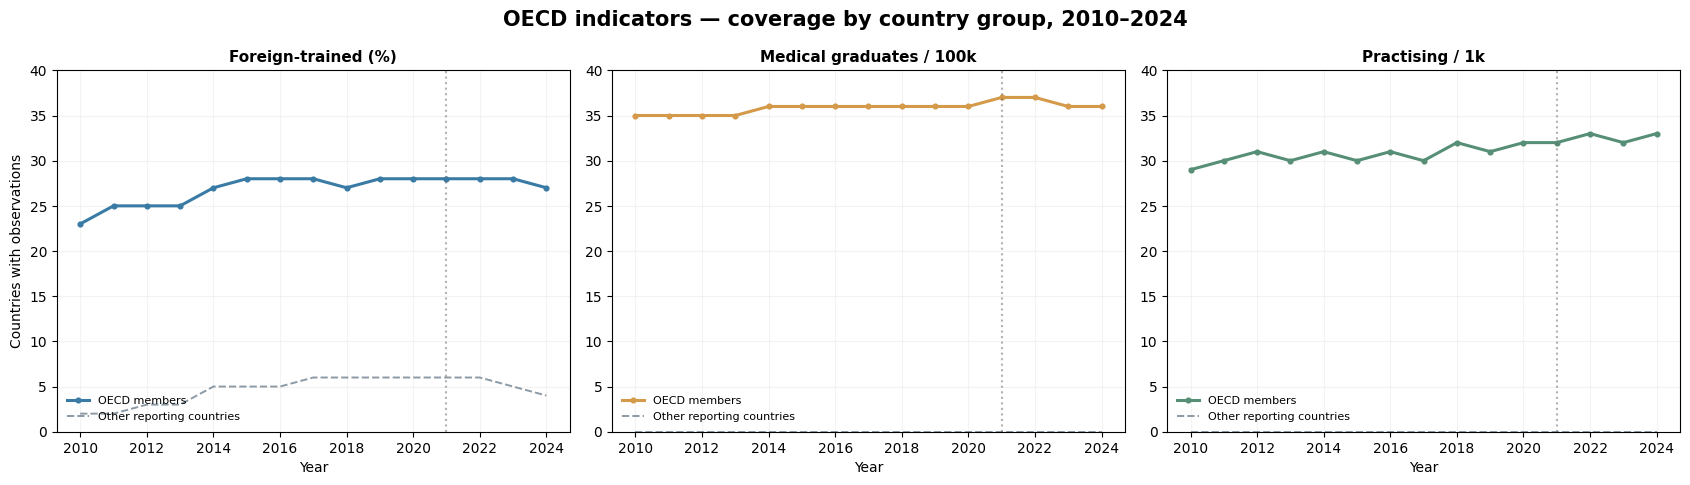

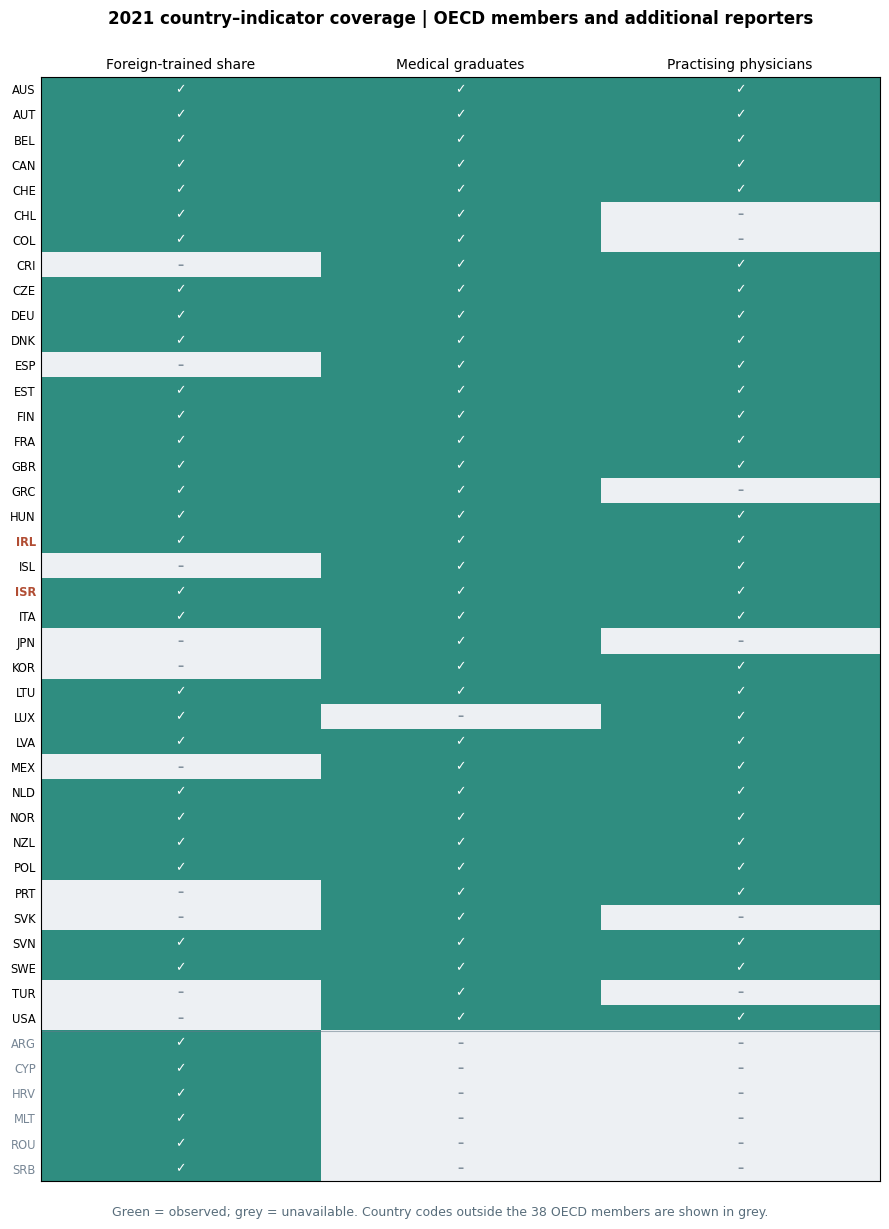

In [4]:
# 2.2 — OECD membership-aware data coverage, never require all 3 indicators by default
from pathlib import Path
from matplotlib.colors import ListedColormap

series_valid = {}
for label, (frame, _) in oecd_eda_series.items():
    valid = frame.loc[pd.to_numeric(frame['OBS_VALUE'], errors='coerce').notna(),
                      ['REF_AREA','TIME_PERIOD','OBS_VALUE']].copy()
    valid['member'] = valid['REF_AREA'].isin(OECD_MEMBERS)
    series_valid[label] = valid

coverage_long = []
for label, frame in series_valid.items():
    for (yr, member), group in frame.groupby(['TIME_PERIOD','member']):
        coverage_long.append({'year':int(yr),'indicator':label,'OECD_member':bool(member),
                              'countries':int(group.REF_AREA.nunique())})
coverage_long = pd.DataFrame(coverage_long)

valid_sets_2021 = {label:set(frame.loc[frame.TIME_PERIOD.eq(2021),'REF_AREA'])
                   for label,frame in series_valid.items()}
pair_specs=[('Foreign-trained (%)', 'Medical graduates / 100k'),
            ('Foreign-trained (%)', 'Practising / 1k'),
            ('Medical graduates / 100k', 'Practising / 1k')]
pair_counts_2021={f'{a} + {b}': len(valid_sets_2021[a] & valid_sets_2021[b]) for a,b in pair_specs}
triple_codes_2021=set.intersection(*valid_sets_2021.values())

coverage_2021=[]
for label, countryset in valid_sets_2021.items():
    coverage_2021.append({'indicator':label,
                          'OECD_with_value':len(countryset & OECD_MEMBERS),
                          'OECD_without_value':len(OECD_MEMBERS-countryset),
                          'non_OECD_with_value':len(countryset-OECD_MEMBERS),
                          'all_reporting':len(countryset)})
coverage_2021=pd.DataFrame(coverage_2021)
print('2021 source coverage, by membership:')
display(coverage_2021)
print('Pairwise country overlaps (use for 2-variable analyses):',pair_counts_2021)
print(f'Three-variable overlap: {len(triple_codes_2021)} countries')
assert coverage_2021.set_index('indicator').loc['Medical graduates / 100k','OECD_with_value']==37
assert coverage_2021.set_index('indicator').loc['Foreign-trained (%)','OECD_with_value']==28
assert coverage_2021.set_index('indicator').loc['Practising / 1k','OECD_with_value']==32
assert len(triple_codes_2021)==24

# Compact membership-specific coverage trend: solid = OECD members, dashed = additional reporters
fig, axes=plt.subplots(1,3,figsize=(17,4.9),sharex=True)
cols=['#397BA5','#D49A49','#568F75']
for ax,(label,color) in zip(axes,zip(series_valid,cols)):
    d=coverage_long.loc[coverage_long.indicator.eq(label)]
    years=np.arange(2010,2025)
    for member,line_style,text_label in [(True,'-','OECD members'),(False,'--','Other reporting countries')]:
        per_year=d.loc[d.OECD_member.eq(member)].set_index('year')['countries'].reindex(years,fill_value=0)
        ax.plot(years,per_year,color=color if member else '#8C9AA6',linestyle=line_style,
                linewidth=2.2 if member else 1.4,marker='o' if member else None,
                markersize=3.4,label=text_label)
    ax.axvline(2021,color='#666',linestyle=':',alpha=.5)
    ax.set_title(label,weight='bold',fontsize=11)
    ax.set_ylim(0,40)
    ax.set_xlabel('Year')
    ax.grid(alpha=.15)
    ax.legend(fontsize=8,frameon=False,loc='lower left')
axes[0].set_ylabel('Countries with observations')
fig.suptitle('OECD indicators — coverage by country group, 2010–2024',weight='bold',fontsize=15)
plt.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/oecd_coverage_by_indicator_2010_2024.png',dpi=175,bbox_inches='tight')
plt.show()

# 38 OECD countries plus any 2021 extra-reporting countries in the files: 1=available, 0=missing.
all_2021_codes=sorted(OECD_MEMBERS) + sorted(set.union(*valid_sets_2021.values())-OECD_MEMBERS)
columns_coverage=list(series_valid)
mat=np.array([[int(code in valid_sets_2021[lab]) for lab in columns_coverage]
              for code in all_2021_codes],dtype=int)
fig,ax=plt.subplots(figsize=(9.0,13.2))
ax.imshow(mat,aspect='auto',cmap=ListedColormap(['#EDF0F3','#2F8D80']),vmin=0,vmax=1)
ax.set_yticks(np.arange(len(all_2021_codes)),all_2021_codes,fontsize=8.3)
ax.set_xticks(np.arange(3),['Foreign-trained share','Medical graduates','Practising physicians'],fontsize=10)
ax.tick_params(axis='x',top=True,labeltop=True,bottom=False,labelbottom=False,length=0)
ax.tick_params(axis='y',length=0)
for yy,code in enumerate(all_2021_codes):
    tick=ax.get_yticklabels()[yy]
    if code in ['ISR','IRL']:tick.set_weight('bold');tick.set_color('#B14D33')
    elif code not in OECD_MEMBERS:tick.set_color('#778695')
    for j in range(3):
        ax.text(j, yy, '✓' if mat[yy,j] else '–',ha='center',va='center',
                color='white' if mat[yy,j] else '#81909C',fontsize=9,fontweight='bold')
ax.axhline(37.5,color='#657A89',linewidth=.8,alpha=.55)
ax.set_title('2021 country–indicator coverage | OECD members and additional reporters',fontsize=12,pad=38,weight='bold')
fig.text(.13,.035,'Green = observed; grey = unavailable. Country codes outside the 38 OECD members are shown in grey.',fontsize=9,color='#586D7B')
plt.tight_layout(rect=[0,.05,1,.96])
fig.savefig('charts/oecd_2021_country_indicator_coverage_matrix.png',dpi=185,bbox_inches='tight')
plt.show()

Path('exports').mkdir(exist_ok=True)
pd.DataFrame(mat,index=all_2021_codes,columns=columns_coverage).rename_axis('country_code').to_csv(
    'exports/OECD_2021_Indicator_Coverage_Matrix.csv',encoding='utf-8-sig')
coverage_2021.to_csv('exports/OECD_2021_Coverage_By_Indicator.csv',index=False,encoding='utf-8-sig')


### 2.3 — התפלגויות חד־ממדיות בשנת 2021

כל היסטוגרמה מציגה **את מלוא המדינות המדווחות למדד**, אך בצבעים שונים לחברות OECD ולאחרות. החציון וה־Box Plot מחושבים על **כל חברות OECD המדווחות את אותו מדד** — 28 בשיעור הכשרה בחו״ל, 37 בבוגרי רפואה ו־32 ברופאים פעילים. כך המדינות הנוספות נשארות גלויות בלי להיחשב כחברות OECD, ואיננו מגבילים את ההתפלגויות למדגם המשותף של 24.


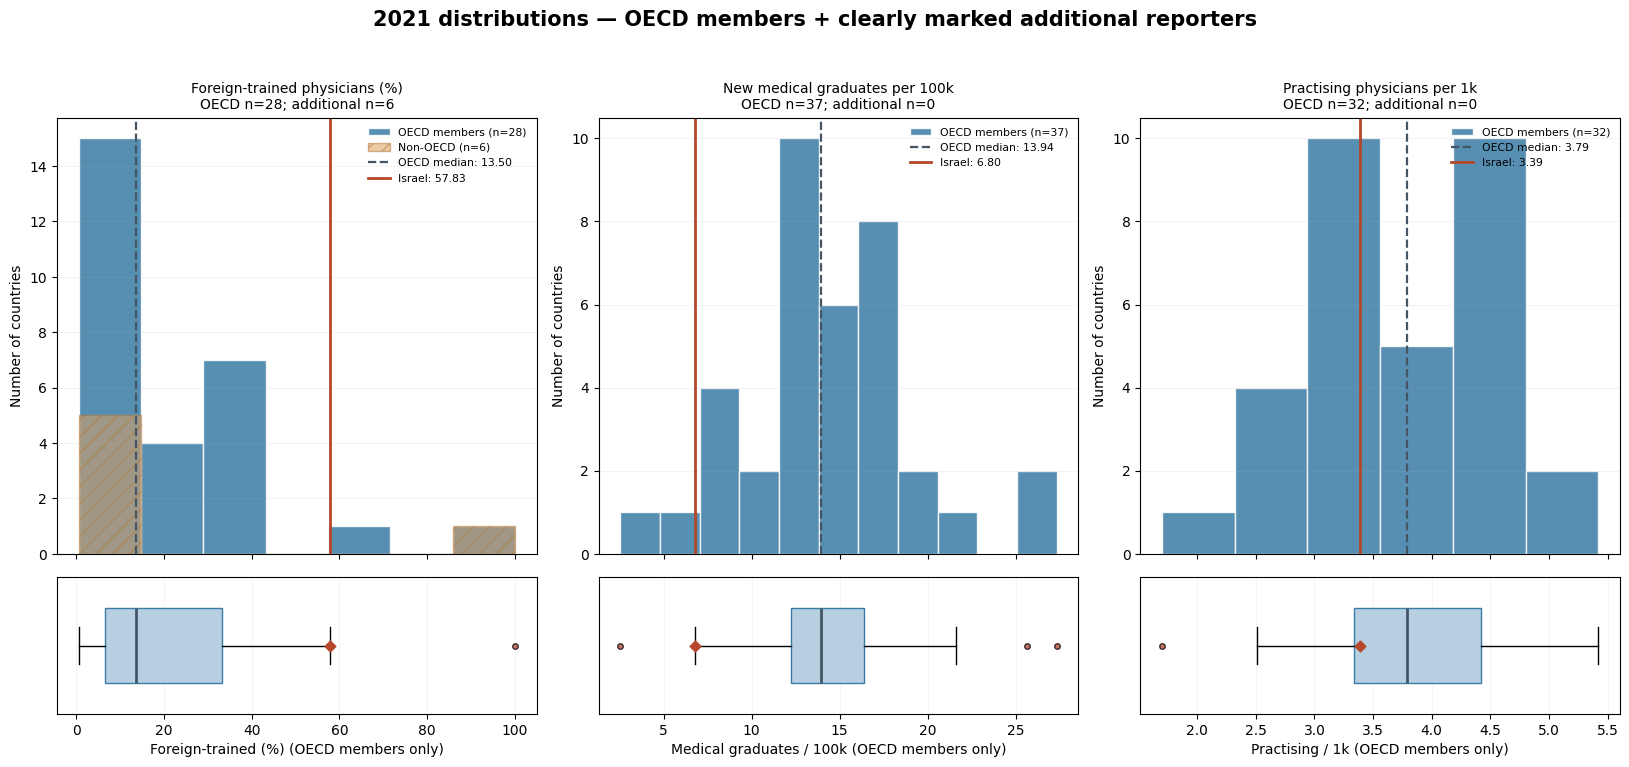

,indicator,OECD_n,extra_n,OECD_mean,OECD_median,OECD_min,OECD_max,israel,IQR_outliers
0,Foreign-trained (%),28,6,21.91,13.50,0.52,100.00,57.83,LUX
1,Medical graduates / 100k,37,0,14.24,13.94,2.54,27.33,6.80,"LVA, CHL, IRL"
2,Practising / 1k,32,0,3.77,3.79,1.70,5.42,3.39,CRI


In [5]:
# 2.3 — Univariate 2021: OECD member countries per measure; other reporters shown separately
fig,axes=plt.subplots(2,3,figsize=(16.4,7.4),gridspec_kw={'height_ratios':[3.2,1]},sharex='col')
summary=[]
for j,(label,(frame,full_title)) in enumerate(oecd_eda_series.items()):
    s=frame.loc[frame.TIME_PERIOD.eq(2021),['REF_AREA','OBS_VALUE']].copy()
    s['OBS_VALUE']=pd.to_numeric(s['OBS_VALUE'],errors='coerce')
    s=s.dropna(subset=['OBS_VALUE'])
    member=s.loc[s.REF_AREA.isin(OECD_MEMBERS)].copy()
    extra=s.loc[~s.REF_AREA.isin(OECD_MEMBERS)].copy()
    values=member.OBS_VALUE
    q1,median,q3=values.quantile([.25,.5,.75])
    lo=q1-1.5*(q3-q1);hi=q3+1.5*(q3-q1)
    out=member.loc[(values<lo)|(values>hi)]
    israel=member.loc[member.REF_AREA.eq('ISR'),'OBS_VALUE'].iloc[0]
    summary.append({'indicator':label,'OECD_n':len(member),'extra_n':len(extra),
        'OECD_mean':values.mean(),'OECD_median':median,'OECD_min':values.min(),
        'OECD_max':values.max(),'israel':israel,'IQR_outliers':', '.join(out.REF_AREA.tolist())})
    ax=axes[0,j]
    boundaries=np.histogram_bin_edges(s.OBS_VALUE,bins='auto')
    ax.hist(member.OBS_VALUE,bins=boundaries,color='#397BA5',edgecolor='white',alpha=.85,
            label=f'OECD members (n={len(member)})')
    if len(extra):
        ax.hist(extra.OBS_VALUE,bins=boundaries,color='#DEA160',alpha=.55,
                hatch='//',edgecolor='#B57B3F',label=f'Non-OECD (n={len(extra)})')
    ax.axvline(median,color='#445665',linestyle='--',linewidth=1.6,label=f'OECD median: {median:.2f}')
    ax.axvline(israel,color='#B5472A',linewidth=2.0,label=f'Israel: {israel:.2f}')
    ax.set_title(f'{full_title}\nOECD n={len(member)}; additional n={len(extra)}',fontsize=10)
    ax.set_ylabel('Number of countries')
    ax.grid(axis='y',alpha=.15)
    ax.legend(fontsize=7.8,loc='upper right',frameon=False)
    bx=axes[1,j]
    bx.boxplot(values,vert=False,widths=.55,patch_artist=True,
        boxprops={'facecolor':'#B7D0E1','edgecolor':'#397BA5'},
        medianprops={'color':'#445665','linewidth':2},
        flierprops={'marker':'o','markersize':4,'markerfacecolor':'#B5472A','alpha':.75})
    bx.scatter([israel],[1],marker='D',color='#B5472A',s=30,zorder=5)
    bx.set_yticks([]);bx.set_xlabel(label+' (OECD members only)');bx.grid(axis='x',alpha=.12)
fig.suptitle('2021 distributions — OECD members + clearly marked additional reporters',fontsize=15,weight='bold',y=1.03)
plt.tight_layout()
fig.savefig('charts/oecd_univariate_2021_hist_box.png',dpi=180,bbox_inches='tight')
plt.show()
oecd_eda_2021_summary=pd.DataFrame(summary)
display(oecd_eda_2021_summary.round(2))


### 2.4 — ממצאים מקדימים מבקרת האיכות (OECD בלבד)

- **כיסוי אינו NULL:** ב־2021 יש 37 חברות OECD עם נתוני בוגרים (לוקסמבורג ללא מדידות בוגרים בכל 2010–2024), 28 עם שיעור הכשרה בחו״ל, ו־32 עם נתוני רופאים פעילים. בנוסף, **6 מדינות שאינן חברות OECD** מדווחות את שיעור ההכשרה בחו״ל. אי אפשר להשלים מדינה שאין לה סדרה שלמה באינטרפולציה.
- **מדגם משתנה לפי השאלה:** 27 מדינות זמינות לקשר בין בוגרים לשיעור הכשרה בחו״ל; 25 לקשר בין שיעור הכשרה בחו״ל לרופאים פעילים; 31 לבוגרים מול רופאים פעילים; ו־24 לגרף עם שלושת המדדים. אלה **חיתוכי מדגמים שונים**, ולא צריך לצמצם את כל הגרפים ל־24.
- **ישראל חריגה גם כאשר מתייחסים למדינות OECD בלבד:** שיעור הכשרה בחו״ל 57.83% ובוגרים חדשים 6.80 ל־100 אלף בשנת 2021. לצורך מיקום יחסי יש להשוות לכל מדינות OECD המדווחות כל מדד, ולא בהכרח רק ל־24 המדינות בחיתוך.
- **שימוש למצגת:** להציג את החריגות של ישראל ולציין ליד כל ממצא את המדגם הרלוונטי. מטריצת הכיסוי, ה־Box Plots ומדיניות השלמת החוסרים יישארו במחברת כנספח מתודולוגי.


### 2.5 השלמת ערכים חסרים — אינטרפולציה ליניארית ובדיקת רגישות

**שאלה:** כאשר חסרה שנת דיווח אחת, אך יש מדידה תקפה בשנה שלפניה ובשנה שאחריה, האם אפשר להשלים את השנה החסרה מבלי לפגוע במסקנות?

נבדוק את **שלוש סדרות OECD שנבחרו לניתוח** (שיעור רופאים שהוכשרו בחו״ל, בוגרי רפואה חדשים, רופאים פעילים). נבחין בין שני סוגי חוסר:

1. **NULL בשורת מקור קיימת** — למשל לוקסמבורג בסדרת הבוגרים.
2. **שנה שלא דווחה כלל** — למשל יפן בסדרת הרופאים הפעילים, המדווחת אחת לשנתיים.

נבצע אינטרפולציה **רק לשנה חסרה אחת המוקפת בשתי שנים עוקבות בעלות ערך מקורי**, ללא השלמת קצוות וללא החלפת מספרים קיימים. נשמור את המדידות המקוריות בנפרד, ונוסיף דגל `is_imputed` לכל ערך משוער. לבסוף נעשה שתי בקרות: בדיקת דיוק על שנים שבהן הערך האמיתי קיים (הסתרה זמנית והערכה), והשוואת מתאמי שנת 2021 עם ובלי אומדנים.

**חשוב:** אינטרפולציה מבוססת על ההנחה שהשינוי בין שתי מדידות סמוכות היה בקירוב ליניארי; היא איננה מדידה אמיתית וגם איננה מתקנת פערי כיסוי בין מדינות וסדרות.

In [6]:
# 2.5.1 — Find genuinely interpolatable one-year gaps, without touching original values
# Everything here is computed from the downloaded OECD CSV files.
from pathlib import Path

series_inputs = {
    'Foreign-trained physicians (%)': oecd_eda_series['Foreign-trained (%)'][0],
    'Medical graduates / 100k': oecd_eda_series['Medical graduates / 100k'][0],
    'Practising physicians / 1k': oecd_eda_series['Practising / 1k'][0],
}
interp_parts = []
cv_records = []

for indicator, src in series_inputs.items():
    src = src[['REF_AREA','TIME_PERIOD','OBS_VALUE']].copy()
    src = src.rename(columns={'REF_AREA':'country_code','TIME_PERIOD':'year', 'OBS_VALUE':'value_original'})
    src['year'] = pd.to_numeric(src['year'], errors='raise').astype(int)
    src['value_original'] = pd.to_numeric(src['value_original'], errors='coerce')
    assert not src.duplicated(['country_code','year']).any(), f'Duplicate: {indicator}'
    src['source_row_exists'] = True

    # Include all years for countries with at least one source row, 2010–2024.
    grid = pd.MultiIndex.from_product(
        [sorted(src.country_code.unique()), range(2010,2025)],
        names=['country_code','year']
    ).to_frame(index=False)
    panel = grid.merge(src, on=['country_code','year'], how='left', validate='one_to_one')
    panel['source_row_exists'] = panel['source_row_exists'].eq(True)
    panel = panel.sort_values(['country_code','year']).reset_index(drop=True)

    groups = panel.groupby('country_code', sort=False)['value_original']
    prev = groups.shift(1)
    next_ = groups.shift(-1)
    one_year_gap = panel.value_original.isna() & prev.notna() & next_.notna()
    panel['is_imputed'] = one_year_gap
    panel['value_for_sensitivity'] = panel.value_original.where(~one_year_gap, (prev + next_) / 2)
    panel['indicator'] = indicator
    interp_parts.append(panel)

    # Holdout validation, using ONLY already observed values and their observed neighbours.
    # Each middle observation is hidden in turn for diagnostic purposes (not actually erased).
    eligible = panel.value_original.notna() & prev.notna() & next_.notna()
    tmp = panel.loc[eligible, ['country_code','year','value_original']].copy()
    tmp['estimate_from_neighbours'] = ((prev + next_) / 2).loc[eligible].to_numpy()
    tmp['indicator'] = indicator
    tmp['abs_error'] = (tmp.estimate_from_neighbours - tmp.value_original).abs()
    tmp['ape_pct'] = (tmp.abs_error / tmp.value_original.where(tmp.value_original.ne(0))).mul(100)
    cv_records.append(tmp)

imputed_series = pd.concat(interp_parts, ignore_index=True)
holdout_one_year = pd.concat(cv_records, ignore_index=True)

profile = imputed_series.groupby('indicator', as_index=False).agg(
    source_rows=('source_row_exists','sum'),
    raw_NULL_or_absent=('value_original', lambda s: int(s.isna().sum())),
    interpolated_years=('is_imputed','sum'),
    valid_original=('value_original','count')
)
profile['explicit_NULL'] = imputed_series.loc[imputed_series.source_row_exists].groupby('indicator').value_original.apply(lambda s: int(s.isna().sum())).reindex(profile.indicator).to_numpy()
profile['absent_country_year_rows'] = profile['raw_NULL_or_absent'] - profile['explicit_NULL']
print('Missingness and interpolation eligibility, 2010–2024:')
display(profile)

imputed_points = imputed_series.loc[imputed_series.is_imputed, ['indicator','country_code','year','value_for_sensitivity','source_row_exists']]
print('Every interpolated value (original source is unchanged):')
display(imputed_points)

assert imputed_series.is_imputed.sum() == 7, 'Unexpected missing-value pattern: inspect before use'
assert set(imputed_points.country_code) == {'JPN'}, 'Unexpected country interpolated'
assert imputed_series.loc[imputed_series.value_original.notna(),'is_imputed'].sum() == 0

Path('exports').mkdir(exist_ok=True)
imputed_series.to_csv('exports/OECD_2010_2024_Original_vs_Interpolated.csv', index=False, encoding='utf-8-sig')
print('Saved provenance table: exports/OECD_2010_2024_Original_vs_Interpolated.csv')


Missingness and interpolation eligibility, 2010–2024:


,indicator,source_rows,raw_NULL_or_absent,interpolated_years,valid_original,explicit_NULL,absent_country_year_rows
0,Foreign-trained physicians (%),473,82,0,473,0,82
1,Medical graduates / 100k,553,32,0,538,15,17
2,Practising physicians / 1k,467,43,7,467,0,43


Every interpolated value (original source is unchanged):


,indicator,country_code,year,value_for_sensitivity,source_row_exists
1426,Practising physicians / 1k,JPN,2011,2.250,False
1428,Practising physicians / 1k,JPN,2013,2.325,False
1430,Practising physicians / 1k,JPN,2015,2.395,False
1432,Practising physicians / 1k,JPN,2017,2.460,False
1434,Practising physicians / 1k,JPN,2019,2.545,False
1436,Practising physicians / 1k,JPN,2021,2.625,False
1438,Practising physicians / 1k,JPN,2023,2.675,False


Saved provenance table: exports/OECD_2010_2024_Original_vs_Interpolated.csv


Leave-one-year-out validation (year t estimated from ORIGINAL t-1 and t+1):


,holdout_n,MAE,median_absolute_error,median_absolute_pct_error,pct90_absolute_pct_error
indicator,,,,,
Foreign-trained physicians (%),399,0.203,0.075,0.614,6.361
Medical graduates / 100k,464,0.672,0.382,2.928,11.159
Practising physicians / 1k,391,0.037,0.015,0.446,2.067


Japan-specific biennial holdout (wider spacing; informative for trend linearity):


,year_held_out,actual,estimated,abs_error
0,2012,2.29,2.285,0.005
1,2014,2.36,2.360,0.000
2,2016,2.43,2.425,0.005
3,2018,2.49,2.515,0.025
4,2020,2.60,2.570,0.030
5,2022,2.65,2.650,0.000


Japan biennial masked-observation MAE: 0.0108 physicians per 1,000


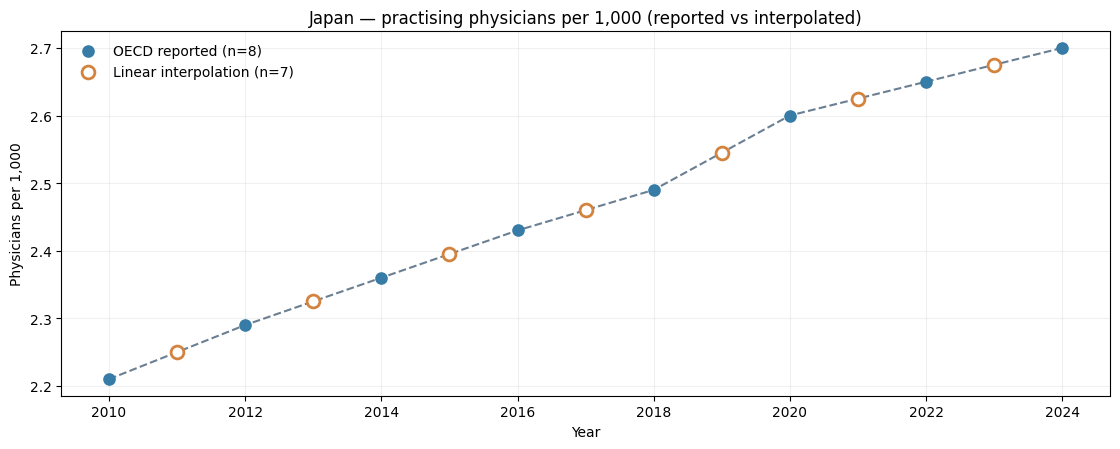

In [7]:
# 2.5.2 — Test interpolation errors on observed years; Japan-specific holdout
cv_summary = holdout_one_year.groupby('indicator').agg(
    holdout_n=('abs_error','size'),
    MAE=('abs_error','mean'),
    median_absolute_error=('abs_error','median'),
    median_absolute_pct_error=('ape_pct','median'),
    pct90_absolute_pct_error=('ape_pct',lambda s: s.quantile(.9)),
).round(3)
print('Leave-one-year-out validation (year t estimated from ORIGINAL t-1 and t+1):')
display(cv_summary)

# Japan reports practising physicians biennially. Validate by hiding an actual
# even-year observation and interpolating between observed even years 4 years apart.
jp = imputed_series.loc[
    imputed_series.indicator.eq('Practising physicians / 1k')
    & imputed_series.country_code.eq('JPN')
    & imputed_series.value_original.notna(),
    ['year','value_original']
].set_index('year')['value_original']
jp_validation = []
for year in sorted(jp.index):
    if year-2 in jp.index and year+2 in jp.index:
        predicted = (jp.loc[year-2]+jp.loc[year+2]) / 2
        actual = jp.loc[year]
        jp_validation.append({'year_held_out':year,'actual':actual, 'estimated':predicted,
                              'abs_error':abs(predicted-actual)})
jp_cv = pd.DataFrame(jp_validation)
print('Japan-specific biennial holdout (wider spacing; informative for trend linearity):')
display(jp_cv.round(3))
print('Japan biennial masked-observation MAE:', round(jp_cv.abs_error.mean(), 4),
      'physicians per 1,000')

# Diagnostic figure — distinguish measured (solid) from interpolated (hollow).
jp_plot = imputed_series.loc[
    imputed_series.indicator.eq('Practising physicians / 1k')
    & imputed_series.country_code.eq('JPN')
].sort_values('year')
fig, ax = plt.subplots(figsize=(11.3,4.6))
ax.plot(jp_plot.year, jp_plot.value_for_sensitivity, linestyle='--', color='#6B7F92', linewidth=1.5)
original_jp = jp_plot.loc[~jp_plot.is_imputed & jp_plot.value_original.notna()]
estimated_jp = jp_plot.loc[jp_plot.is_imputed]
ax.scatter(original_jp.year, original_jp.value_original, s=65,
           color='#377CA6', label=f'OECD reported (n={len(original_jp)})', zorder=5)
ax.scatter(estimated_jp.year, estimated_jp.value_for_sensitivity, s=85,
           facecolors='white', edgecolors='#D3833D', linewidths=2,
           label=f'Linear interpolation (n={len(estimated_jp)})', zorder=6)
ax.set(title='Japan — practising physicians per 1,000 (reported vs interpolated)',
       xlabel='Year', ylabel='Physicians per 1,000', xticks=list(range(2010,2025,2)))
ax.grid(alpha=.18)
ax.legend(frameon=False)
fig.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/oecd_japan_practising_interpolation.png',dpi=170,bbox_inches='tight')
plt.show()


In [8]:
# 2.5.3 — Compare imputed vs original values with each metric's OWN eligible overlap
metrics={'Foreign-trained physicians (%)':'foreign_pct',
         'Medical graduates / 100k':'graduates_100k',
         'Practising physicians / 1k':'practising_1k'}
original=imputed_series.loc[imputed_series.year.eq(2021)].pivot(
    index='country_code',columns='indicator',values='value_original').rename(columns=metrics)
filled=imputed_series.loc[imputed_series.year.eq(2021)].pivot(
    index='country_code',columns='indicator',values='value_for_sensitivity').rename(columns=metrics)

def correlation_rows(frame,version):
    out=[]
    for a,b in [('foreign_pct','graduates_100k'),('foreign_pct','practising_1k'),
                ('graduates_100k','practising_1k')]:
        ss=frame[[a,b]].dropna()
        out.append({'version':version,'metric_pair':f'{a} vs {b}',
                    'countries_n':len(ss),'pearson_r':ss[a].corr(ss[b])})
    out.append({'version':version,'metric_pair':'ALL THREE (sample size only)',
                'countries_n':len(frame.dropna(subset=['foreign_pct','graduates_100k','practising_1k'])),
                'pearson_r':np.nan})
    return out
sensitivity=pd.DataFrame(correlation_rows(original,'original')+correlation_rows(filled,'interpolated'))
print('Sensitivity — use the LARGEST valid sample separately for each pair:')
display(sensitivity.round(4))
print('Japan 2021 practising rate (linear imputation):',round(filled.loc['JPN','practising_1k'],3))
# Only the first two pairwise correlations are invariant in this dataset.
# Interpolating Japan's practising rate adds Japan to the graduates/practising pair (31 -> 32),
# so its correlation changes. Report the difference instead of asserting it away.
check=sensitivity.pivot(index='metric_pair',columns='version',values=['countries_n','pearson_r'])
print('Change caused by eligible imputation (particularly Japan):')
display(check.round(4))
assert sensitivity.loc[(sensitivity.version.eq('original')) &
    (sensitivity.metric_pair.eq('graduates_100k vs practising_1k')),'countries_n'].iloc[0]==31
assert sensitivity.loc[(sensitivity.version.eq('interpolated')) &
    (sensitivity.metric_pair.eq('graduates_100k vs practising_1k')),'countries_n'].iloc[0]==32
sensitivity.to_csv('exports/OECD_2021_Interpolation_Sensitivity.csv',index=False,encoding='utf-8-sig')


Sensitivity — use the LARGEST valid sample separately for each pair:


,version,metric_pair,countries_n,pearson_r
0,original,foreign_pct vs graduates_100k,27,-0.3583
1,original,foreign_pct vs practising_1k,25,-0.1320
2,original,graduates_100k vs practising_1k,31,0.2204
3,original,ALL THREE (sample size only),24,NaN
4,interpolated,foreign_pct vs graduates_100k,27,-0.3583
5,interpolated,foreign_pct vs practising_1k,25,-0.1320
6,interpolated,graduates_100k vs practising_1k,32,0.2704
7,interpolated,ALL THREE (sample size only),24,NaN


Japan 2021 practising rate (linear imputation): 2.625
Change caused by eligible imputation (particularly Japan):


countries_n             pearson_r         
version                         interpolated original interpolated original
metric_pair                                                                
ALL THREE (sample size only)            24.0     24.0          NaN      NaN
foreign_pct vs graduates_100k           27.0     27.0      -0.3583  -0.3583
foreign_pct vs practising_1k            25.0     25.0      -0.1320  -0.1320
graduates_100k vs practising_1k         32.0     31.0       0.2704   0.2204

**מסקנת האינטרפולציה:** את 15 ערכי ה־NULL בסדרת בוגרי הרפואה של לוקסמבורג אי אפשר להשלים — חסרות כל השנים. ביפן אפשר לאמוד כמה שנים בסדרת הרופאים הפעילים מתוך שנים שכנות, ובפרט את 2021. ההשלמה **אינה משנה** את הקשר בין בוגרי רפואה לשיעור ההכשרה בחו״ל (27 מדינות) או את הקשר בין שיעור ההכשרה בחו״ל לרופאים פעילים (25 מדינות), משום שביפן אין לנו מדד הכשרה בחו״ל. **אבל היא כן משנה את הקשר בין בוגרי רפואה לרופאים פעילים:** המדגם גדל מ־31 ל־32 מדינות והמתאם משתנה מכ־0.220 לכ־0.270. לכן נדווח את התוצאה המקורית והרגישות בנפרד, ולא נציג ערך משוער כמדידה רשמית.


## 3. OECD — טבלת מדינה × שנה מאוחדת (FULL OUTER JOIN)

לכל מדד יחידת תצפית מדינה ושנה. ננקה את הגרנולריות ונבחר מדד מתוך הקבצים, ואז נבצע `FULL OUTER JOIN` כדי **לא לאבד מדינות ושנים שקיימות רק באחד המקורות**. אחר כך נבחר למדגם רק מדינות שיש להן את המשתנים של השאלה המסוימת. נוסיף דגל OECD כדי להבחין בין חברים לבין מדינות מדווחות אחרות. NULL שלא דווח נשאר NULL, לא אפס.


In [9]:
# 3.0 — Union of country/year observations, not a migration-anchored LEFT JOIN.
def take_series(df,*,where,name):
    f=df.copy()
    for col,expected in where.items():
        f=f.loc[f[col].eq(expected)]
    f=f[['REF_AREA','TIME_PERIOD','OBS_VALUE']].rename(
        columns={'REF_AREA':'country_code','TIME_PERIOD':'year','OBS_VALUE':name})
    f[name]=pd.to_numeric(f[name],errors='coerce')
    assert not f.duplicated(['country_code','year']).any(),f'Duplicate country-year keys: {name}'
    return f

foreign_pct=take_series(oecd_migration,where={'TRAINING_PLACE':'FOREIGN',
    'UNIT_MEASURE':'PT_WR_PRF_HLTH'},name='foreign_trained_pct')
graduates=take_series(oecd_graduates,where={'UNIT_MEASURE':'10P5HB'},name='graduates_per_100k')
physicians=take_series(oecd_physicians,where={'UNIT_MEASURE':'10P3HB',
    'HEALTH_PROF_ACTIVITY_STATUS':'P'},name='practising_per_1000')

oecd_panel=(foreign_pct.merge(graduates,how='outer',on=['country_code','year'],validate='one_to_one')
           .merge(physicians,how='outer',on=['country_code','year'],validate='one_to_one'))
oecd_panel['oecd_member']=oecd_panel['country_code'].isin(OECD_MEMBERS)
oecd_panel=oecd_panel.sort_values(['country_code','year']).reset_index(drop=True)
assert not oecd_panel.duplicated(['country_code','year']).any()
print('FULL OUTER JOIN: country-year rows =',len(oecd_panel),'countries =',oecd_panel.country_code.nunique())
print('2021 OECD sample sizes (each indicator separately):')
sub=oecd_panel.loc[oecd_panel.year.eq(2021) & oecd_panel.oecd_member]
for k in ['foreign_trained_pct','graduates_per_100k','practising_per_1000']:
    print(k,sub[k].notna().sum())
assert sub['foreign_trained_pct'].notna().sum()==28
assert sub['graduates_per_100k'].notna().sum()==37
assert sub['practising_per_1000'].notna().sum()==32
display(oecd_panel.query("country_code == 'ISR'").sort_values('year'))


FULL OUTER JOIN: country-year rows = 640 countries = 44
2021 OECD sample sizes (each indicator separately):
foreign_trained_pct 28
graduates_per_100k 37
practising_per_1000 32


,country_code,year,foreign_trained_pct,graduates_per_100k,practising_per_1000,oecd_member
331,ISR,2010,59.97,4.12,3.01,True
332,ISR,2011,59.84,4.85,3.00,True
333,ISR,2012,59.48,3.84,2.97,True
334,ISR,2013,59.11,5.06,2.94,True
335,ISR,2014,58.56,6.29,2.98,True
336,ISR,2015,58.48,5.47,3.07,True
337,ISR,2016,58.12,6.76,3.08,True
338,ISR,2017,57.85,6.90,3.14,True
339,ISR,2018,57.93,7.41,3.22,True
340,ISR,2019,57.81,7.22,3.29,True


### 3.1 — קשר דו־ממדי: בוגרי רפואה מול שיעור רופאים שהוכשרו בחו״ל

בהיסטוגרמה נשתמש בחברות OECD שיש להן נתוני שיעור הכשרה בחו״ל בכל השנים. ב־Scatter Plot של 2021 נכלול **כל מדינת OECD שיש לה את שני המדדים**, כלומר 27 מדינות. אין צורך במדד רופאים פעילים כדי להיכלל כאן.


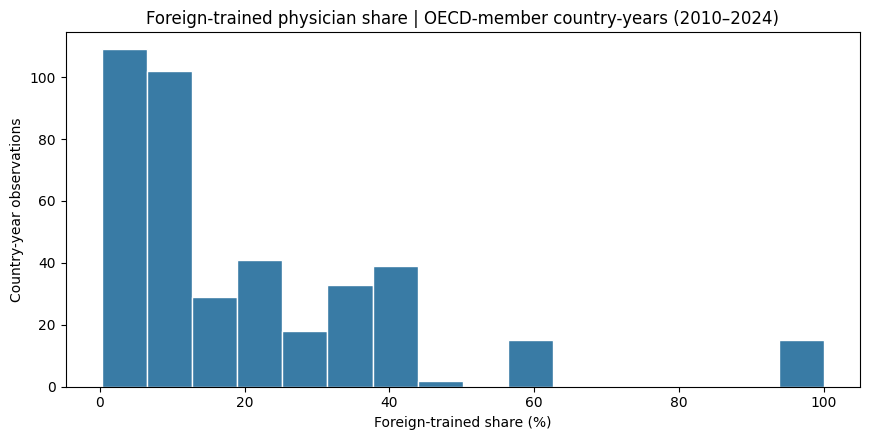

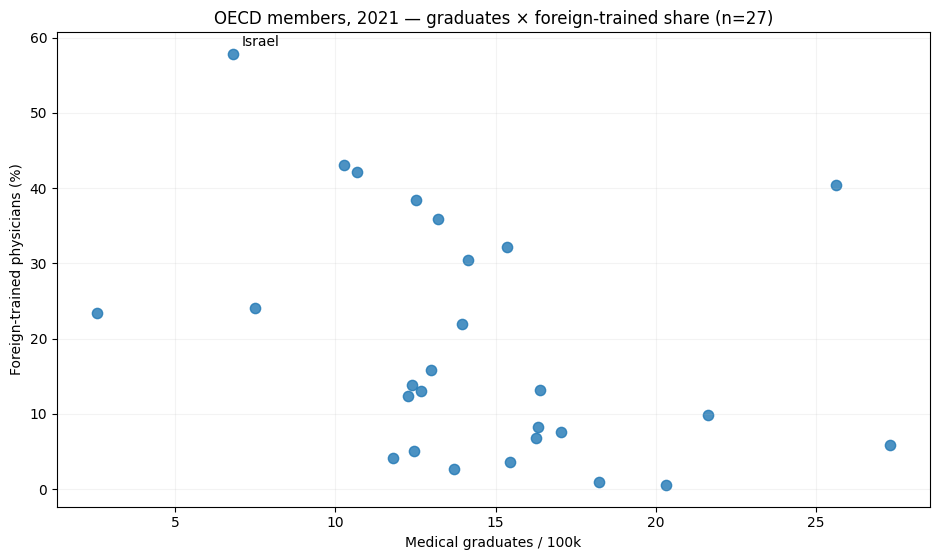

Pearson r (pairwise complete OECD countries): -0.3582693977441985


In [10]:
fig,ax=plt.subplots(figsize=(8.8,4.5))
valid_hist=oecd_panel.loc[oecd_panel.oecd_member,'foreign_trained_pct'].dropna()
ax.hist(valid_hist,bins=16,color='#397BA5',edgecolor='white')
ax.set(title='Foreign-trained physician share | OECD-member country-years (2010–2024)',
       xlabel='Foreign-trained share (%)',ylabel='Country-year observations')
plt.tight_layout();plt.show()

sample=oecd_panel.loc[oecd_panel.year.eq(2021) & oecd_panel.oecd_member].dropna(
    subset=['foreign_trained_pct','graduates_per_100k'])
fig,ax=plt.subplots(figsize=(9.5,5.7))
ax.scatter(sample.graduates_per_100k,sample.foreign_trained_pct,alpha=.8,s=55)
isr=sample.loc[sample.country_code.eq('ISR')].iloc[0]
ax.annotate('Israel',(isr.graduates_per_100k,isr.foreign_trained_pct),xytext=(6,6),textcoords='offset points')
ax.set(title=f'OECD members, 2021 — graduates × foreign-trained share (n={len(sample)})',
       xlabel='Medical graduates / 100k',ylabel='Foreign-trained physicians (%)')
ax.grid(alpha=.15)
plt.tight_layout();plt.show()
print('Pearson r (pairwise complete OECD countries):',sample.graduates_per_100k.corr(sample.foreign_trained_pct))
assert len(sample)==27


### 3.2 חקירת חריגים — ישראל, אירלנד והשפעתן על המתאם

**השאלה:** האם הקשר השלילי בין בוגרי רפואה מקומיים לשיעור הרופאים שהוכשרו בחו״ל נשמר כאשר בוחנים את רגישותו למדינות חריגות?

נשתמש בדיוק ב־27 המדינות עם שני המדדים בשנת 2021. נציג את ישראל ואת המדינות שהתרחקו ביותר מקו המגמה לפי **שארית מוחלטת** (הפרש אנכי בין הנקודה לקו הרגרסיה). המדד הזה הוא כלי תיאורי לזיהוי חריגות, לא מבחן פורמלי לחריגים.

לא נמחק שום מדינה מהנתונים: חישובים ללא ישראל או ללא אירלנד הם **בדיקות רגישות נפרדות בלבד**. הנתון על בוגרים הוא זרם בשנה אחת; שיעור ההכשרה בחו״ל מתאר מלאי רופאים. לכן אין להסיק סיבתיות.

In [11]:
# 2021 — מתאם עם ובלי המדינות החריגות, בלי לשנות את oecd_panel
sample_2021 = oecd_panel.loc[oecd_panel['year'].eq(2021) & oecd_panel['oecd_member']].dropna(
    subset=['graduates_per_100k', 'foreign_trained_pct']).copy()
assert len(sample_2021) == 27, 'Review data selection before comparing with the original chart'

x_col, y_col = 'graduates_per_100k', 'foreign_trained_pct'
scenarios = [
    ('OECD members with both variables', []),
    ('Without Israel', ['ISR']),
    ('Without Ireland', ['IRL']),
    ('Without Israel and Ireland', ['ISR', 'IRL']),
]
results = []
for label, excluded in scenarios:
    ss = sample_2021.loc[~sample_2021['country_code'].isin(excluded)]
    results.append({'sample': label, 'n_countries': len(ss),
                    'pearson_r': ss[[x_col,y_col]].corr().iloc[0,1]})
correlation_sensitivity = pd.DataFrame(results)
display(correlation_sensitivity.round(3))

# Ranking by vertical departure from fitted straight line, not by extreme x or y alone
slope, intercept = np.polyfit(sample_2021[x_col], sample_2021[y_col], deg=1)
sample_2021['line_prediction'] = slope*sample_2021[x_col] + intercept
sample_2021['residual'] = sample_2021[y_col] - sample_2021['line_prediction']
sample_2021['abs_residual'] = sample_2021['residual'].abs()
country_names_en = {'ISR':'Israel', 'IRL':'Ireland', 'NOR':'Norway',
                    'NZL':'New Zealand', 'EST':'Estonia', 'CHE':'Switzerland',
                    'LVA':'Latvia', 'POL':'Poland', 'GBR':'United Kingdom'}
sample_2021['country_name'] = sample_2021['country_code'].map(country_names_en).fillna(sample_2021['country_code'])
print('Largest absolute deviations from the trend line:')
display(sample_2021.nlargest(8, 'abs_residual')[[
    'country_name','country_code', x_col, y_col, 'line_prediction', 'residual']].round(2))


,sample,n_countries,pearson_r
0,OECD members with both variables,27,-0.358
1,Without Israel,26,-0.259
2,Without Ireland,26,-0.543
3,Without Israel and Ireland,25,-0.474


Largest absolute deviations from the trend line:


,country_name,country_code,graduates_per_100k,foreign_trained_pct,line_prediction,residual
312,Ireland,IRL,25.63,40.45,7.00,33.45
342,Israel,ISR,6.80,57.83,27.22,30.61
488,Norway,NOR,10.26,43.12,23.50,19.61
503,New Zealand,NZL,10.68,42.12,23.05,19.07
214,Estonia,EST,11.80,4.18,21.85,-17.67
83,Switzerland,CHE,12.51,38.44,21.09,17.35
518,Poland,POL,13.70,2.69,19.81,-17.12
113,COL,COL,12.46,5.12,21.14,-16.02


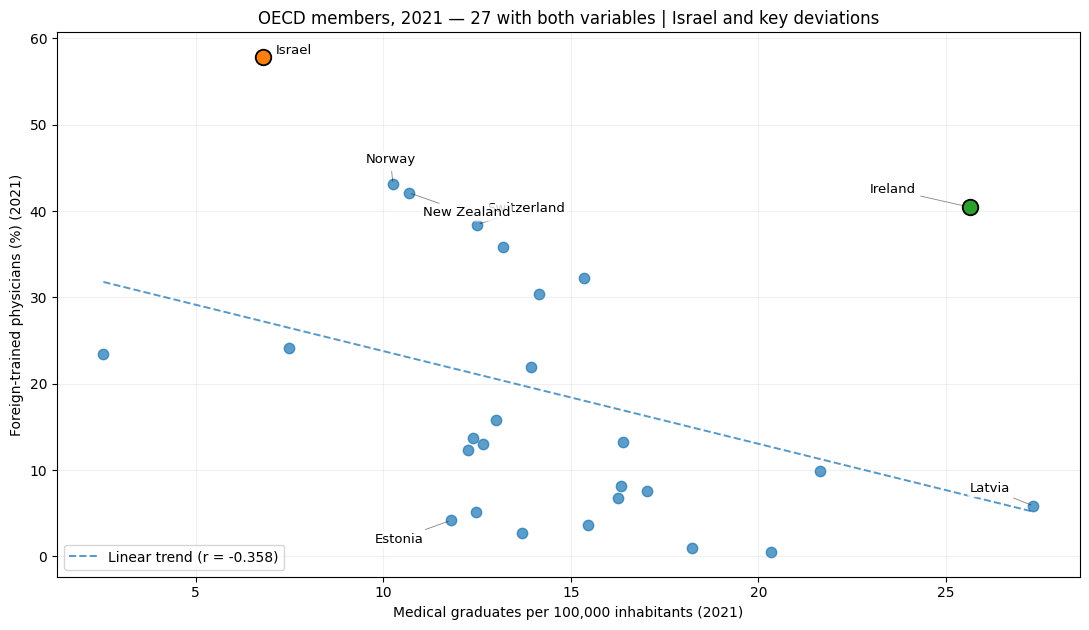

Saved chart: charts/oecd_2021_outliers.png


In [12]:
# Same observations; only annotate selected countries to keep the plot readable.
# The 6 largest absolute residuals + Latvia as an extreme x value.
labels_to_show = set(sample_2021.nlargest(6, 'abs_residual')['country_code']) | {'LVA'}
offsets = {
    'ISR': (9, 2), 'IRL': (-72, 10), 'NOR': (-20, 15),
    'NZL': (10, -17), 'EST': (-55, -16), 'CHE': (7, 9), 'LVA': (-46, 10)
}
fig, ax = plt.subplots(figsize=(11, 6.4))
ax.scatter(sample_2021[x_col], sample_2021[y_col], alpha=.72, s=56)
for cc in ['ISR', 'IRL']:
    ss = sample_2021.loc[sample_2021['country_code'].eq(cc)]
    ax.scatter(ss[x_col], ss[y_col], s=125, edgecolors='black', linewidths=1.3, zorder=5)

xx = np.linspace(sample_2021[x_col].min(), sample_2021[x_col].max(), 100)
ax.plot(xx, slope*xx+intercept, linestyle='--', linewidth=1.4, alpha=.75,
        label=f'Linear trend (r = {correlation_sensitivity.loc[0, "pearson_r"]:.3f})')

for _, row in sample_2021.loc[sample_2021['country_code'].isin(labels_to_show)].iterrows():
    name = country_names_en.get(row['country_code'], row['country_code'])
    ax.annotate(name, (row[x_col], row[y_col]),
                xytext=offsets.get(row['country_code'], (6,6)),
                textcoords='offset points', fontsize=9.5,
                bbox=dict(boxstyle='round,pad=.16', fc='white', alpha=.82, ec='none'),
                arrowprops=dict(arrowstyle='-', alpha=.45, lw=.65))
ax.set(xlabel='Medical graduates per 100,000 inhabitants (2021)',
       ylabel='Foreign-trained physicians (%) (2021)',
       title=f'OECD members, 2021 — {len(sample_2021)} with both variables | Israel and key deviations')
ax.grid(alpha=.18)
ax.legend(loc='lower left')
fig.tight_layout()
from pathlib import Path
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/oecd_2021_outliers.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved chart: charts/oecd_2021_outliers.png')


**תובנת ביניים — המדגם הוא 27 מדינות OECD עם שני המדדים, ולא 24 מדינות עם שלושתם.** מתאם Pearson שלילי של כ־0.358− (27 מדינות) נחלש לכ־0.259− ללא ישראל (26 מדינות). ללא אירלנד הוא מתחזק לכ־0.543− (26 מדינות). כלומר לשתי המדינות יש השפעה בכיוונים מנוגדים על המתאם. זו בדיקת רגישות *תיאורית* בלבד, לא סיבה להשמיט את המדינות מהניתוח המרכזי.

**שאלת המשך:** למה אירלנד משלבת מספר גבוה של בוגרי רפואה מקומיים ושיעור גבוה של רופאים שהוכשרו בחו״ל? ייתכן שיש תנועת רופאים בין מדינות, אך כדי להסביר זאת נצטרך נתונים נוספים; אין להסיק מהגרף בלבד.

### 3.3 — קשרים דו־ממדיים ורב־ממדיים עם רופאים פעילים

כל מתאם דו־ממדי מחושב על **חיתוך המדינות שיש להן את שני משתניו**. רק תרשים הבועות תלת־הממדי דורש שלושה מדדים. בשנת 2021: בוגרים + הכשרה בחו״ל = 27; הכשרה בחו״ל + רופאים פעילים = 25; בוגרים + רופאים פעילים = 31; שלושתם יחד = 24. כל הדגימות מתייחסות לחברות OECD בלבד.


In [13]:
# 3.3 — Pairwise-complete correlations; use a 24-country sample ONLY for the 3-variable plot
metric_cols=['foreign_trained_pct','graduates_per_100k','practising_per_1000']
raw_2021=oecd_panel.loc[oecd_panel.year.eq(2021) & oecd_panel.oecd_member].copy()
result_rows=[]
for a,b in [('graduates_per_100k','foreign_trained_pct'),
            ('foreign_trained_pct','practising_per_1000'),
            ('graduates_per_100k','practising_per_1000')]:
    tt=raw_2021.dropna(subset=[a,b])
    result_rows.append({'pair':f'{a} × {b}','countries_n':len(tt),
                        'pearson_r':tt[a].corr(tt[b])})
pairwise_correlations_2021=pd.DataFrame(result_rows)
print('Correct PAIRWISE OECD samples:')
display(pairwise_correlations_2021.round(3))
assert pairwise_correlations_2021.countries_n.tolist()==[27,25,31]

pair_2021=raw_2021.dropna(subset=['graduates_per_100k','foreign_trained_pct']).copy()
triad_2021=raw_2021.dropna(subset=metric_cols).copy()
assert len(triad_2021)==24
missing_physicians=sorted(set(pair_2021.country_code)-set(triad_2021.country_code))
print(f'Three-indicator plot: {len(triad_2021)} countries; pair-only countries without practising:',missing_physicians)
print('Optional same-sample (24) correlation matrix — not a substitute for pairwise results:')
display(triad_2021[metric_cols].corr().round(3))
median_docs=float(triad_2021.practising_per_1000.median())
selected=triad_2021.loc[triad_2021.country_code.isin(['ISR','IRL']),['country_code']+metric_cols]
print('Median practising among 24 complete cases:',round(median_docs,3))
display(selected.round(2))


Correct PAIRWISE OECD samples:


,pair,countries_n,pearson_r
0,graduates_per_100k × foreign_trained_pct,27,-0.358
1,foreign_trained_pct × practising_per_1000,25,-0.132
2,graduates_per_100k × practising_per_1000,31,0.220


Three-indicator plot: 24 countries; pair-only countries without practising: ['CHL', 'COL', 'GRC']
Optional same-sample (24) correlation matrix — not a substitute for pairwise results:


,foreign_trained_pct,graduates_per_100k,practising_per_1000
foreign_trained_pct,1.000,-0.399,-0.148
graduates_per_100k,-0.399,1.000,0.243
practising_per_1000,-0.148,0.243,1.000


Median practising among 24 complete cases: 3.85


,country_code,foreign_trained_pct,graduates_per_100k,practising_per_1000
312,IRL,40.45,25.63,3.96
342,ISR,57.83,6.80,3.39


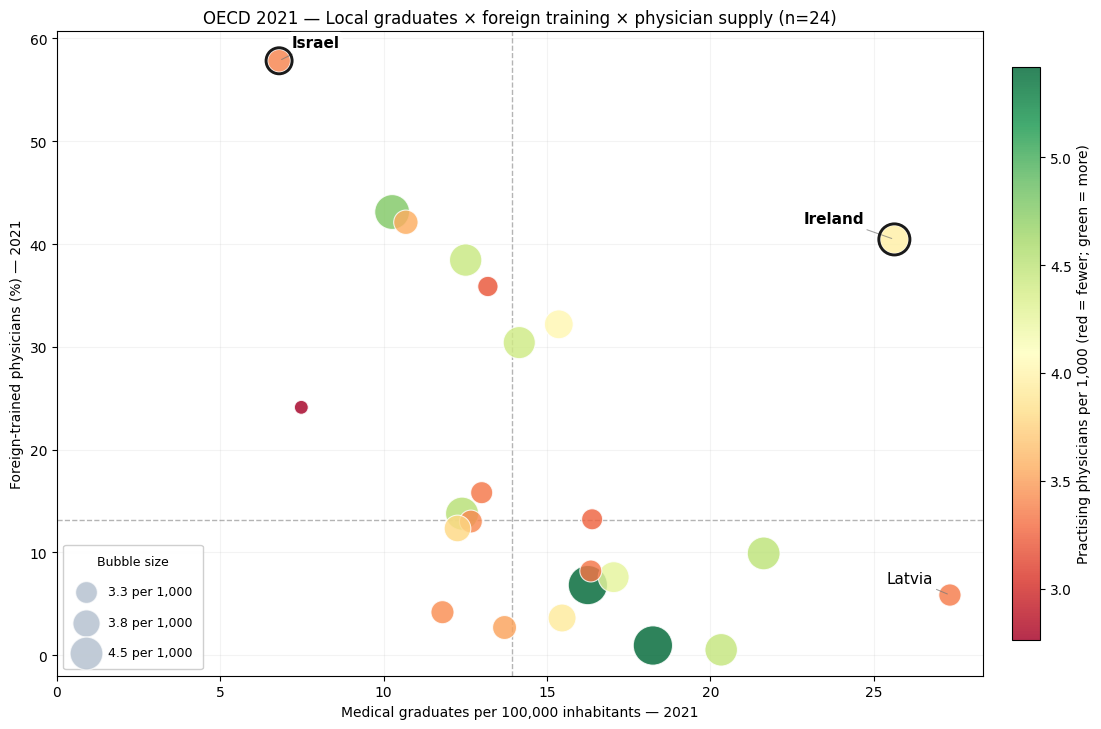

Saved: charts/oecd_2021_bubble_traffic_lights.png


In [14]:
# 3.3 — OECD 2021: Three-dimensional bubble chart
# Larger and greener circles indicate more practising physicians per 1,000.
from matplotlib.colors import Normalize

plot_2021 = triad_2021.copy()
metric = 'practising_per_1000'
minimum = float(plot_2021[metric].min())
maximum = float(plot_2021[metric].max())
range_docs = maximum - minimum

def physician_bubble_size(value):
    if range_docs == 0:
        return 360
    return 100 + 700 * (float(value) - minimum) / range_docs

plot_2021['bubble_area'] = plot_2021[metric].apply(physician_bubble_size)

fig, ax = plt.subplots(figsize=(12, 7.4))
points = ax.scatter(
    plot_2021['graduates_per_100k'],
    plot_2021['foreign_trained_pct'],
    c=plot_2021[metric],
    s=plot_2021['bubble_area'],
    cmap='RdYlGn', norm=Normalize(vmin=minimum, vmax=maximum),
    alpha=.82, edgecolors='#ffffff', linewidth=.8, zorder=3
)
color_bar = fig.colorbar(points, ax=ax, pad=.025, shrink=.89)
color_bar.set_label('Practising physicians per 1,000 (red = fewer; green = more)')

# Dashed lines describe the 24 three-variable OECD countries ONLY.
median_grad = plot_2021['graduates_per_100k'].median()
median_foreign = plot_2021['foreign_trained_pct'].median()
ax.axvline(median_grad, color='#777777', ls='--', lw=1, alpha=.55)
ax.axhline(median_foreign, color='#777777', ls='--', lw=1, alpha=.55)

country_labels = {'ISR':'Israel', 'IRL':'Ireland', 'LVA':'Latvia'}
label_offsets = {'ISR':(9, 10), 'IRL':(-65, 12), 'LVA':(-46, 9)}
for cc, label in country_labels.items():
    rows = plot_2021.loc[plot_2021['country_code'].eq(cc)]
    if rows.empty:
        continue
    row=rows.iloc[0]
    x,y = float(row['graduates_per_100k']), float(row['foreign_trained_pct'])
    if cc in ['ISR','IRL']:
        ax.scatter([x], [y], s=float(row['bubble_area'])+85,
                   facecolors='none', edgecolors='#1a1a1a', linewidth=2.1, zorder=5)
    ax.annotate(label, (x,y), xytext=label_offsets.get(cc,(7,7)),
                textcoords='offset points', fontsize=11,
                fontweight='bold' if cc in ['ISR','IRL'] else 'normal',
                bbox=dict(boxstyle='round,pad=.2', fc='white', ec='none', alpha=.9),
                arrowprops=dict(arrowstyle='-', color='#777777', lw=.75, alpha=.7))

# Separate size guide; the colour bar describes the same third variable.
for v in np.quantile(plot_2021[metric], [0.15,0.50,0.85]):
    ax.scatter([], [], s=physician_bubble_size(v), color='#a7b6c6',
               alpha=.7, edgecolors='white', label=f'{v:.1f} per 1,000')
ax.legend(title='Bubble size', loc='lower left', fontsize=9, title_fontsize=9,
          scatterpoints=1, labelspacing=1.4, borderpad=.8, framealpha=.94)

ax.set(xlabel='Medical graduates per 100,000 inhabitants — 2021',
       ylabel='Foreign-trained physicians (%) — 2021',
       title=f'OECD 2021 — Local graduates × foreign training × physician supply (n={len(plot_2021)})')
ax.set_xlim(left=0)
ax.set_ylim(bottom=-2)
ax.grid(alpha=.14, zorder=0)
fig.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/oecd_2021_bubble_traffic_lights.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: charts/oecd_2021_bubble_traffic_lights.png')


**איך לפרש:** 27 חברות OECD זמינות לקשר בין בוגרי רפואה לשיעור ההכשרה בחו״ל; 25 לקשר בין שיעור הכשרה בחו״ל לרופאים פעילים; 31 לקשר בין בוגרים לרופאים פעילים. תרשים הבועות משתמש ב־**24 מדינות בלבד**, משום שהצבע, הגודל ושני הצירים יחד דורשים שלוש תצפיות תקפות. ישראל: 57.83% הכשרה בחו״ל, 6.80 בוגרים ל־100 אלף ו־3.39 רופאים פעילים לאלף. אירלנד: 40.45%, 25.63 ו־3.96 בהתאמה. אלה מתאמים תיאוריים, לא השפעה סיבתית. חציון וקווי חלוקה בגרף הבועות מחושבים אך ורק על 24 המדינות המוצגות בו.


### 3.4 ארבע קבוצות מדינות — בחינת שילוב בין הכשרה מקומית להכשרה בחו״ל

**השערה לבדיקה:** האם מדינות שבהן גם מספר בוגרי הרפואה המקומיים וגם שיעור הרופאים שהוכשרו בחו״ל גבוהים יחסית מציגות יותר רופאים פעילים לנפש?

נחלק את **24 המדינות שיש עבורן את כל שלושת המדדים בשנת 2021** לארבע קבוצות לפי החציון של כל אחד משני משתני ההכשרה. נשווה ביניהן את **ממוצע וחציון הרופאים הפעילים ל־1,000 תושבים** ונציג גם את מספר המדינות בקבוצה.

הערה: ״שיעור הכשרה בחו״ל״ הוא חלק ממלאי הרופאים הקיים, בעוד שמספר הבוגרים הוא זרם שנתי. זו **השוואה תיאורית**, לא חיבור חשבונאי ולא הוכחת השפעה סיבתית.


Country sample: 24
Median threshold — domestic medical graduates / 100k: 13.93
Median threshold — foreign-trained physician share: 13.11%

Physician density by training-pathway group (per 1,000):


,n_countries,mean_physicians,median_physicians,min_physicians,max_physicians
quadrant,,,,,
Low local / Low foreign,4,3.53,3.47,3.41,3.78
Low local / High foreign,8,3.75,3.47,2.76,4.77
High local / Low foreign,8,4.33,4.36,3.33,5.42
High local / High foreign,4,3.91,3.99,3.25,4.41



Israel and Ireland in the four-group comparison:


,country_code,quadrant,graduates_per_100k,foreign_trained_pct,practising_per_1000
312,IRL,High local / High foreign,25.63,40.45,3.96
342,ISR,Low local / High foreign,6.80,57.83,3.39


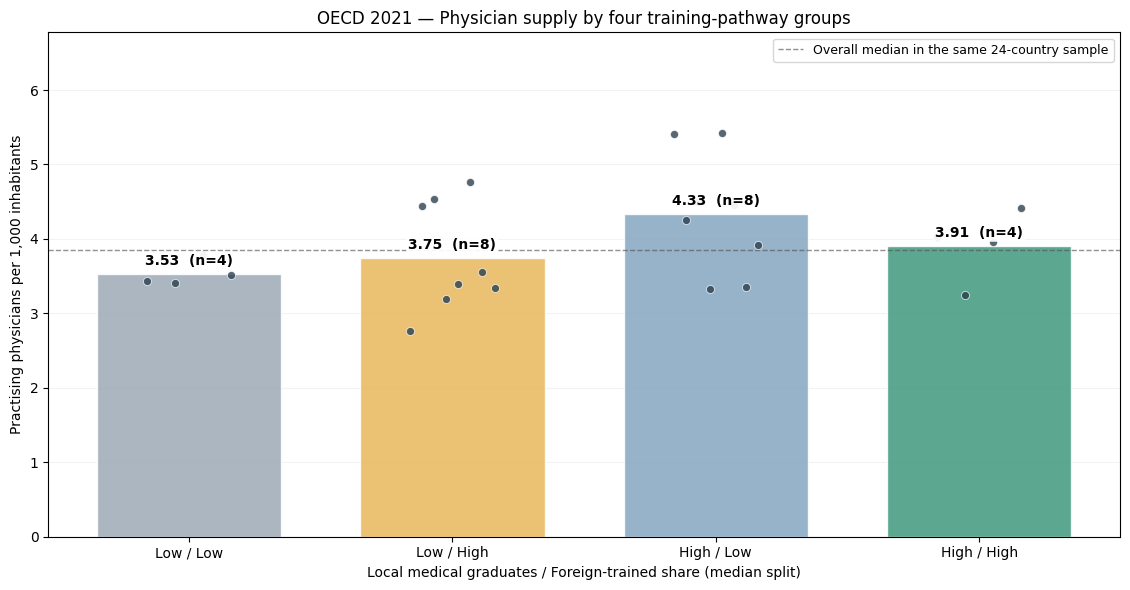

Saved: charts/oecd_2021_training_quadrants.png

Countries within each quadrant (ISO codes):


,countries
quadrant,
Low local / Low foreign,"EST, FIN, FRA, POL"
Low local / High foreign,"CAN, CHE, DEU, GBR, ISR, NOR, NZL, SVN"
High local / Low foreign,"AUT, CZE, DNK, HUN, ITA, LTU, LVA, NLD"
High local / High foreign,"AUS, BEL, IRL, SWE"


In [15]:
# 3.4 — Four groups from two indicators; physician supply is the comparison outcome
quadrants_2021 = triad_2021.copy()
local_cutoff = float(quadrants_2021['graduates_per_100k'].median())
foreign_cutoff = float(quadrants_2021['foreign_trained_pct'].median())

quadrants_2021['local_level'] = np.where(
    quadrants_2021['graduates_per_100k'] >= local_cutoff, 'High local', 'Low local')
quadrants_2021['foreign_level'] = np.where(
    quadrants_2021['foreign_trained_pct'] >= foreign_cutoff, 'High foreign', 'Low foreign')
quadrants_2021['quadrant'] = (
    quadrants_2021['local_level'] + ' / ' + quadrants_2021['foreign_level'])

quadrant_order = [
    'Low local / Low foreign',
    'Low local / High foreign',
    'High local / Low foreign',
    'High local / High foreign',
]
quadrants_2021['quadrant'] = pd.Categorical(
    quadrants_2021['quadrant'], categories=quadrant_order, ordered=True)

quadrant_summary = (
    quadrants_2021.groupby('quadrant', observed=True)['practising_per_1000']
    .agg(n_countries='count', mean_physicians='mean',
         median_physicians='median', min_physicians='min', max_physicians='max')
    .reindex(quadrant_order)
)

print(f'Country sample: {len(quadrants_2021)}')
print(f'Median threshold — domestic medical graduates / 100k: {local_cutoff:.2f}')
print(f'Median threshold — foreign-trained physician share: {foreign_cutoff:.2f}%')
print('\nPhysician density by training-pathway group (per 1,000):')
display(quadrant_summary.round(2))
print('\nIsrael and Ireland in the four-group comparison:')
display(quadrants_2021.loc[
    quadrants_2021['country_code'].isin(['ISR', 'IRL']),
    ['country_code','quadrant','graduates_per_100k','foreign_trained_pct','practising_per_1000']
].sort_values('country_code').round(2))

# Show country counts in every group, including any empty group.
fig, ax = plt.subplots(figsize=(11.4, 6))
bar_colors = ['#9CA9B6','#E8B65C','#84A6C1','#3E987C']
labels = ['Low / Low', 'Low / High', 'High / Low', 'High / High']
positions = np.arange(4)
means = quadrant_summary['mean_physicians'].to_numpy(dtype=float)
bars = ax.bar(positions, means, width=.7, color=bar_colors,
              edgecolor='white', linewidth=1, alpha=.85, zorder=2)

# Individual country dots show variation that group means would hide.
for i, group_name in enumerate(quadrant_order):
    values = quadrants_2021.loc[quadrants_2021['quadrant'].eq(group_name),
                                'practising_per_1000'].to_numpy()
    if len(values):
        offsets = np.linspace(-.16,.16,len(values)) if len(values)>1 else np.array([0.0])
        ax.scatter(np.full(len(values), i)+offsets, values, s=34,
                   facecolors='#263C4C', edgecolors='white', linewidths=.6,
                   alpha=.78, zorder=4)
        ax.text(i, means[i]+.08, f'{means[i]:.2f}  (n={len(values)})',
                ha='center', va='bottom', fontsize=10, fontweight='bold', zorder=7,
                bbox=dict(facecolor='white', edgecolor='none', alpha=.93, boxstyle='round,pad=.15'))
    else:
        ax.text(i, .2, 'No data', ha='center', va='bottom', fontsize=10)
ax.axhline(float(quadrants_2021['practising_per_1000'].median()),
           color='#555555', ls='--', lw=1, alpha=.65,
           label='Overall median in the same 24-country sample')
ax.set_xticks(positions, labels)
ax.set(xlabel='Local medical graduates / Foreign-trained share (median split)',
       ylabel='Practising physicians per 1,000 inhabitants',
       title='OECD 2021 — Physician supply by four training-pathway groups')
ax.set_ylim(0, max(quadrants_2021['practising_per_1000'].max(), np.nanmax(means)) * 1.25)
ax.legend(loc='upper right', fontsize=9)
ax.grid(axis='y', alpha=.15, zorder=0)
fig.tight_layout()
fig.savefig('charts/oecd_2021_training_quadrants.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: charts/oecd_2021_training_quadrants.png')

# A transparent country roster prevents accidental over-interpretation of small groups.
print('\nCountries within each quadrant (ISO codes):')
display(quadrants_2021.groupby('quadrant', observed=True)['country_code']
        .apply(lambda x: ', '.join(sorted(x))).reindex(quadrant_order).to_frame('countries'))


**איך לקרוא את הגרפים?**

1. **בועות:** העמדה נקבעת לפי בוגרי רפואה מקומיים ושיעור הרופאים שהוכשרו בחו״ל; **גודל הבועה וגם צבעה** מייצגים את מספר הרופאים הפעילים לנפש (אדום = נמוך, ירוק = גבוה). הקווים המקווקווים מייצגים חציונים של 24 המדינות שיש להן את שלושת המדדים.
2. **ארבע קבוצות:** כל עמודה מציגה ממוצע של מספר הרופאים לנפש, הנקודות הכהות הן המדינות עצמן, ותווית `n` מציינת את מספר המדינות בקבוצה. הטבלה שמעל הגרף מציגה גם חציון וטווח.
3. **זהירות בפרשנות:** החלוקה בחציון נועדה לגלות דפוסים, לא להגדיר רמות בינלאומיות מוחלטות. קשר בין הקבוצות להיצע רופאים אינו מוכיח קשר סיבתי, והוא עלול להיות מושפע ממדינות חריגות ומהגדרות המדדים.

**שאלה להמשך המחקר:** האם דפוסי 2021 נשמרים כשמסתכלים על שנות מדידה נוספות או על מדינות דומות בגודל, בכלכלה ובהיקף מערכת הבריאות?


### 3.5 נרמול מלאי הרופאים לאוכלוסייה — הכשרה מקומית מול הכשרה בחו״ל

**השאלה החדשה:** במקום להשוות *מספר בוגרים מקומיים בשנה* ל*אחוז הרופאים שהוכשרו בחו״ל*, נבחן שתי קבוצות של **מלאי הרופאים** באותה יחידה ובאותה שנה:

- רופאים שהוכשרו **מקומית** לכל 1,000 תושבים.
- רופאים שהוכשרו **בחו״ל** לכל 1,000 תושבים.

נשתמש בספירות המוחלטות (`Persons`) ששמורות כבר ב־OECD Workforce Migration, ובאוכלוסיית 2021 ממדד הבנק העולמי `SP.POP.TOTL`. הגרפים הבאים משתמשים **ב־2021 בלבד**, כי זו שנת האוכלוסייה שצורפה לחבילה. אין השלמת אוכלוסייה משנים אחרות.

**מקורות:** OECD Workforce Migration (הורדה מקורית של הפרויקט); [World Bank Population, total](https://data.worldbank.org/indicator/SP.POP.TOTL), בקובץ `data/population_2021_world_bank.csv`, הועתק מנתוני הבנק העולמי דרך [datasets/population](https://github.com/datasets/population/blob/main/data/population.csv) בתאריך 24.10.2026.

**הבחנה חיונית:** מדד `Practising physicians / 1000` מגיע מסדרת OECD אחרת. יתכנו הבדלים בהגדרת אוכלוסיית הרופאים בינו לבין Workforce Migration. לכן לא נניח ששני המדדים שווים, ונבדוק את הפער באופן גלוי.

In [16]:
# 3.5.1 — Build comparable doctor-training stocks per 1,000 inhabitants (2021)
import matplotlib.colors as mcolors

population_2021 = pd.read_csv(DATA / 'population_2021_world_bank.csv')
assert population_2021[['country_code', 'year']].duplicated().sum() == 0
assert population_2021['year'].eq(2021).all()
assert population_2021['population'].gt(0).all()

# The SAME OECD series, headcounts instead of percentage (already in our files).
stock_2021 = oecd_migration.loc[
    oecd_migration['TIME_PERIOD'].eq(2021)
    & oecd_migration['UNIT_MEASURE'].eq('PS')
    & oecd_migration['TRAINING_PLACE'].isin(['DOMESTIC', 'FOREIGN', '_T']),
    ['REF_AREA', 'TIME_PERIOD', 'TRAINING_PLACE', 'OBS_VALUE']
].copy()

assert not stock_2021.duplicated(['REF_AREA','TIME_PERIOD','TRAINING_PLACE']).any()
stock_2021 = stock_2021.pivot(
    index=['REF_AREA','TIME_PERIOD'], columns='TRAINING_PLACE', values='OBS_VALUE'
).rename(columns={'DOMESTIC':'domestic_count', 'FOREIGN':'foreign_count', '_T':'total_reported_count'}).reset_index()
stock_2021.columns.name = None
stock_2021 = stock_2021.rename(columns={'REF_AREA':'country_code','TIME_PERIOD':'year'})

stock_2021 = stock_2021.merge(
    population_2021[['country_code','year','population']],
    on=['country_code','year'], how='left', validate='one_to_one')
stock_2021 = stock_2021.merge(
    oecd_panel[['country_code','year','practising_per_1000']],
    on=['country_code','year'], how='left', validate='one_to_one')

for prefix in ['domestic','foreign','total_reported']:
    stock_2021[f'{prefix}_per_1000'] = stock_2021[f'{prefix}_count'] / stock_2021['population'] * 1000
stock_2021['parts_sum_per_1000'] = stock_2021['domestic_per_1000'] + stock_2021['foreign_per_1000']
stock_2021['parts_vs_total_gap_count'] = (
    stock_2021['domestic_count'] + stock_2021['foreign_count'] - stock_2021['total_reported_count'])
stock_2021['reported_vs_practising_gap_per_1000'] = (
    stock_2021['total_reported_per_1000'] - stock_2021['practising_per_1000'])

print('2021 countries with migration headcounts (OECD and additional reporters):',len(stock_2021))
print('Countries with population:',stock_2021['population'].notna().sum())
print('Missing population codes:',stock_2021.loc[stock_2021.population.isna(),'country_code'].tolist())
print('Complete domestic + foreign + population:',stock_2021[['domestic_per_1000','foreign_per_1000']].notna().all(axis=1).sum())
print('Complete training stocks + practising indicator:',stock_2021[['domestic_per_1000','foreign_per_1000','practising_per_1000']].notna().all(axis=1).sum())

case_studies = stock_2021.loc[stock_2021.country_code.isin(['ISR','IRL']),[
    'country_code','population','domestic_count','foreign_count',
    'domestic_per_1000','foreign_per_1000','parts_sum_per_1000',
    'total_reported_per_1000','practising_per_1000','reported_vs_practising_gap_per_1000']]
print('\nISRAEL & IRELAND — based on headcounts divided by population:')
display(case_studies.round(3).sort_values('country_code'))

print('\nSource-comparability check, largest disagreements (different physician definitions may apply):')
display(stock_2021.loc[stock_2021.practising_per_1000.notna(),[
    'country_code','parts_vs_total_gap_count','reported_vs_practising_gap_per_1000'
]].assign(abs_gap=lambda d:d.reported_vs_practising_gap_per_1000.abs())
.sort_values('abs_gap',ascending=False).head(8).round(3))


2021 countries with migration headcounts (OECD and additional reporters): 33
Countries with population: 33
Missing population codes: []
Complete domestic + foreign + population: 33
Complete training stocks + practising indicator: 24

ISRAEL & IRELAND — based on headcounts divided by population:


,country_code,population,domestic_count,foreign_count,domestic_per_1000,foreign_per_1000,parts_sum_per_1000,total_reported_per_1000,practising_per_1000,reported_vs_practising_gap_per_1000
19,IRL,5110585,15459.0,10500.0,3.025,2.055,5.079,5.079,3.96,1.119
20,ISR,9371400,13705.0,18809.0,1.462,2.007,3.469,3.471,3.39,0.081



Source-comparability check, largest disagreements (different physician definitions may apply):


,country_code,parts_vs_total_gap_count,reported_vs_practising_gap_per_1000,abs_gap
3,BEL,0.0,3.021,3.021
12,EST,0.0,1.857,1.857
21,ITA,-2515.0,1.844,1.844
19,IRL,0.0,1.119,1.119
22,LTU,-64.0,0.988,0.988
2,AUT,0.0,-0.891,0.891
15,GBR,0.0,0.697,0.697
14,FRA,-241.0,-0.600,0.600


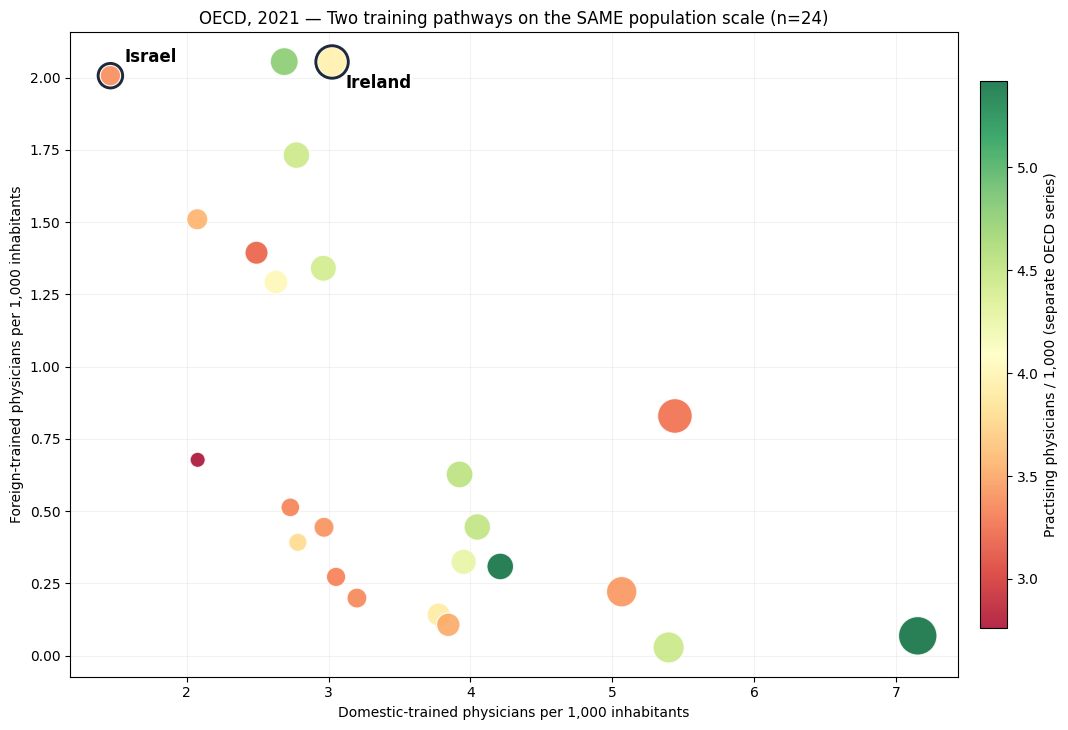

Saved: charts/oecd_2021_domestic_foreign_per1000.png


In [17]:
# 3.5.2 — Domestic-trained vs foreign-trained doctors per 1,000 residents
# Red/yellow/green indicates the SEPARATE practising-physicians series.
# Bubble area represents the migration-report stock, shown only descriptively.
from matplotlib.colors import Normalize

plot_stocks = stock_2021.dropna(subset=[
    'domestic_per_1000','foreign_per_1000','total_reported_per_1000','practising_per_1000']).copy()
assert len(plot_stocks) >= 15

lo=float(plot_stocks['total_reported_per_1000'].min())
hi=float(plot_stocks['total_reported_per_1000'].max())
plot_stocks['bubble_area'] = (
    120 + 650*(plot_stocks['total_reported_per_1000']-lo)/(hi-lo)
    if hi>lo else 380)

fig, ax=plt.subplots(figsize=(11.6,7.4))
scatter=ax.scatter(
    plot_stocks['domestic_per_1000'], plot_stocks['foreign_per_1000'],
    s=plot_stocks['bubble_area'], c=plot_stocks['practising_per_1000'],
    cmap='RdYlGn', norm=Normalize(
        vmin=plot_stocks['practising_per_1000'].min(),
        vmax=plot_stocks['practising_per_1000'].max()),
    edgecolor='white', linewidth=0.9, alpha=.84, zorder=3)
cb=fig.colorbar(scatter,ax=ax,pad=.02,shrink=.85)
cb.set_label('Practising physicians / 1,000 (separate OECD series)')

for code, name, xytext in [('ISR','Israel',(10,10)),('IRL','Ireland',(10,-19))]:
    row=plot_stocks.loc[plot_stocks.country_code.eq(code)]
    if row.empty: continue
    r=row.iloc[0]
    ax.scatter([r.domestic_per_1000],[r.foreign_per_1000],
        facecolors='none',edgecolors='#1e293b',linewidths=2.1,
        s=r.bubble_area+95,zorder=4)
    ax.annotate(name,(r.domestic_per_1000,r.foreign_per_1000),
        xytext=xytext,textcoords='offset points',fontsize=12,fontweight='bold',
        bbox=dict(fc='white',ec='none',alpha=.88,pad=.22))

ax.set(xlabel='Domestic-trained physicians per 1,000 inhabitants',
       ylabel='Foreign-trained physicians per 1,000 inhabitants',
       title=f'OECD, 2021 — Two training pathways on the SAME population scale (n={len(plot_stocks)})')
ax.grid(alpha=.16)
fig.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/oecd_2021_domestic_foreign_per1000.png',dpi=185,bbox_inches='tight')
plt.show()
print('Saved: charts/oecd_2021_domestic_foreign_per1000.png')


Median cut-offs (domestic, foreign): 3.04, 0.48 physicians / 1,000


,countries,practising_mean,practising_median,total_stock_mean
pathway_group,,,,
Low domestic / Low foreign,2,3.595,3.595,3.297
Low domestic / High foreign,10,3.783,3.755,3.977
High domestic / Low foreign,10,4.160,4.090,4.589
High domestic / High foreign,2,3.890,3.890,5.411



Israel and Ireland, stock-based quadrants:


,country_code,pathway_group,domestic_per_1000,foreign_per_1000,practising_per_1000
19,IRL,Low domestic / High foreign,3.025,2.055,3.96
20,ISR,Low domestic / High foreign,1.462,2.007,3.39


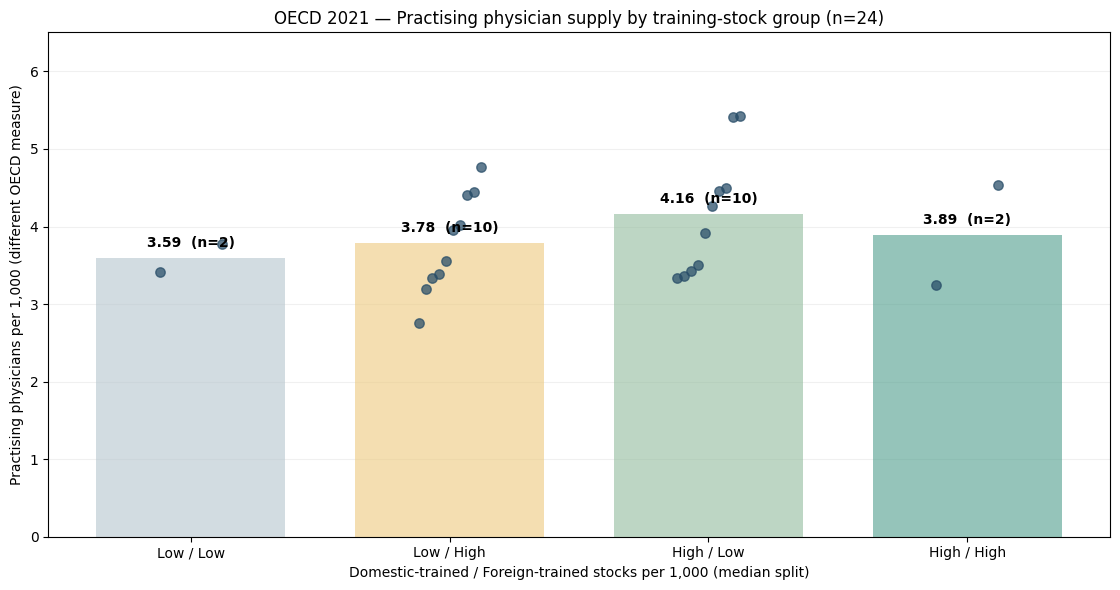

Saved: charts/oecd_2021_training_stock_groups.png


In [18]:
# 3.5.3 — Four-group comparison based on STOCK of physicians per population
# Different from the previous quadrants: both group axes now measure current stocks, not graduate flows.
q=plot_stocks.copy()
d_cut=float(q.domestic_per_1000.median())
f_cut=float(q.foreign_per_1000.median())
q['pathway_group'] = np.where(q.domestic_per_1000 >= d_cut, 'High domestic', 'Low domestic') + ' / ' + np.where(q.foreign_per_1000 >= f_cut, 'High foreign', 'Low foreign')
groups=['Low domestic / Low foreign','Low domestic / High foreign',
        'High domestic / Low foreign','High domestic / High foreign']
summary=(q.groupby('pathway_group').agg(
    countries=('country_code','size'),
    practising_mean=('practising_per_1000','mean'),
    practising_median=('practising_per_1000','median'),
    total_stock_mean=('total_reported_per_1000','mean')
).reindex(groups))
print(f'Median cut-offs (domestic, foreign): {d_cut:.2f}, {f_cut:.2f} physicians / 1,000')
display(summary.round(3))
print('\nIsrael and Ireland, stock-based quadrants:')
display(q.loc[q.country_code.isin(['ISR','IRL']),[
    'country_code','pathway_group','domestic_per_1000',
    'foreign_per_1000','practising_per_1000']].round(3))

fig, ax=plt.subplots(figsize=(11.3,6))
for i, group in enumerate(groups):
    s=q.loc[q.pathway_group.eq(group),'practising_per_1000'].sort_values()
    if len(s):
        ax.scatter(i+np.linspace(-.12,.12,len(s)),s,s=46,color='#274C67',alpha=.73,zorder=3)
bar_colors=['#b5c5cd','#edc97d','#92bc9d','#4e9e8c']
means=summary['practising_mean'].values
ax.bar(range(4),means,color=bar_colors,alpha=.6,zorder=2,width=.73)
for i,(v,n) in enumerate(zip(means,summary['countries'])):
    if pd.notna(v):
        ax.annotate(f'{v:.2f}  (n={int(n)})',(i,v),xytext=(0,8),textcoords='offset points',ha='center',fontsize=10,fontweight='bold')
ax.set_xticks(range(4),['Low / Low','Low / High','High / Low','High / High'])
ax.set(xlabel='Domestic-trained / Foreign-trained stocks per 1,000 (median split)',
       ylabel='Practising physicians per 1,000 (different OECD measure)',
       title=f'OECD 2021 — Practising physician supply by training-stock group (n={len(q)})')
ax.set_ylim(0,max(float(q.practising_per_1000.max()),float(np.nanmax(means)))*1.2)
ax.grid(axis='y',alpha=.18)
fig.tight_layout()
fig.savefig('charts/oecd_2021_training_stock_groups.png',dpi=185,bbox_inches='tight')
plt.show()
print('Saved: charts/oecd_2021_training_stock_groups.png')


**איך מפרשים את שני הגרפים החדשים?**

1. הגרף הראשון מציג את מספר הרופאים שהוכשרו בארץ ובחו״ל **לכל 1,000 תושבים**. זוהי השוואה ישירה בין מלאי שתי קבוצות הכשרה; מדד הבוגרים השנתי נשאר בפרק הקודם, בנפרד.
2. **הסכום של שתי קבוצות הרופאים הוא בקירוב מלאי הרופאים המדווח לפי מקום הכשרה.** לכן הטענה שיותר משני המקורות יחד פירושו מלאי גדול יותר היא כמעט זהות חשבונאית — לא ראיה סיבתית. 
3. מספר **הרופאים העוסקים בפועל** מסדרת OECD Physicians עשוי להיות שונה ממלאי הרופאים המדווח לפי מסלול הכשרה. אין להניח שההפרש הוא בהכרח 'מחסור' או 'אי־תעסוקה': הוא עשוי לשקף הגדרות, שנים ומקורות דיווח שונים. הבדלי המקורות מוצגים בטבלת בקרת האיכות מעל.
4. החלוקה לרבעים היא **תיאורית**, עם מדגם קטן וספי חציון שתלויים במדינות שהן חלק מהמדגם. אין להסיק ממנה שהגדלת מסלול הכשרה מסוים *תגרום* ליותר רופאים פעילים.
5. נתוני האוכלוסייה של הבנק העולמי אינם חלק מקובץ ה־BAK שכבר הוגש; הם קובץ חיצוני עם מקור מתועד, המצורף למחברת לצורך ניתוח בלבד.

### 3.6 חישוב לכל המדינות: מקומיים + חו״ל = מלאי משולב לאלף תושבים

**השלב הזה מחשב מחדש מתוך נתוני המקור** לכל מדינה בעלת ספירות ואוכלוסייה זמינות בשנת 2021:

\[
\text{הוכשרו מקומית ל־1,000} = \frac{\text{מספר רופאים שהוכשרו מקומית}}{\text{אוכלוסיית 2021}} \times 1{,}000
\]

\[
\text{הוכשרו בחו״ל ל־1,000} = \frac{\text{מספר רופאים שהוכשרו בחו״ל}}{\text{אוכלוסיית 2021}} \times 1{,}000
\]

\[
\text{סכום שתי קבוצות ההכשרה} = \text{מקומית ל־1,000} + \text{חו״ל ל־1,000}
\]

לצד סכום שתי הקבוצות מופיע **מדד נפרד** של רופאים פעילים ל־1,000 תושבים (`Practising Physicians`). הוא אינו בהכרח משתמש באותה אוכלוסיית רופאים כמו `Workforce Migration`, ולכן ההפרש ביניהם הוא *בדיקת עקביות בין מקורות*, **לא מדד ישיר למחסור ברופאים**.

הטבלה מציגה את כל המדינות בעלות הנתונים הדרושים לחיבור שתי קבוצות ההכשרה; במדינות ללא נתון של רופאים פעילים נציג ערך חסר, **לא אפס**. סכימת הקבוצות עשויה להיות שונה מסך הרופאים המדווח במאגר המקורי עקב הגדרות/כיסוי/עיגול, ונבדוק זאת ללא תיקון ידני.

In [19]:
# 3.6.1 — A complete, reproducible country table for OECD 2021
# Recalculate from original absolute headcounts and population, rather than reusing a saved CSV.
country_labels = (oecd_migration.loc[
    oecd_migration['TIME_PERIOD'].eq(2021), ['REF_AREA', 'Reference area']]
    .dropna(subset=['REF_AREA'])
    .drop_duplicates(subset='REF_AREA')
    .rename(columns={'REF_AREA':'country_code', 'Reference area':'country_name'})
)

full_country_table = stock_2021.merge(
    country_labels, on='country_code', how='left', validate='many_to_one'
)
full_country_table = full_country_table.dropna(
    subset=['population', 'domestic_count', 'foreign_count']
).copy()

# Recompute all central columns from source quantities; no hardcoded country-specific totals.
full_country_table['local_per_1000'] = (
    full_country_table['domestic_count'] / full_country_table['population'] * 1000
)
full_country_table['abroad_per_1000'] = (
    full_country_table['foreign_count'] / full_country_table['population'] * 1000
)
full_country_table['combined_per_1000'] = (
    full_country_table['local_per_1000'] + full_country_table['abroad_per_1000']
)
full_country_table['gap_vs_practising_per_1000'] = (
    full_country_table['combined_per_1000'] - full_country_table['practising_per_1000']
)
full_country_table['source_total_gap_count'] = (
    full_country_table['domestic_count'] + full_country_table['foreign_count']
    - full_country_table['total_reported_count']
)

# Check we did not inadvertently change the underlying 2021 stock calculations.
assert np.allclose(full_country_table['combined_per_1000'],
    (full_country_table['domestic_count'] + full_country_table['foreign_count'])
    / full_country_table['population'] * 1000)
assert not full_country_table.duplicated(['country_code', 'year']).any()

full_country_table = full_country_table.sort_values(
    ['practising_per_1000', 'country_code'], ascending=[False, True], na_position='last'
).reset_index(drop=True)
full_country_table['calculation'] = full_country_table.apply(
    lambda r: f"{r.local_per_1000:.2f} + {r.abroad_per_1000:.2f} ≈ {r.combined_per_1000:.2f}", axis=1
)

print(f"Countries with both training pathways + population: {len(full_country_table)}")
print(f"Countries with additional practising-physicians data: {full_country_table['practising_per_1000'].notna().sum()}")
print('Units: physicians per 1,000 inhabitants, calendar year 2021')

# This is the country-by-country table for the presentation preparation.
column_labels = {
    'country_name': 'Country',
    'country_code': 'ISO3',
    'local_per_1000': 'Trained locally / 1k',
    'abroad_per_1000': 'Trained abroad / 1k',
    'combined_per_1000': 'Local + abroad / 1k',
    'practising_per_1000': 'Practising / 1k',
    'gap_vs_practising_per_1000': 'Sum − practising / 1k',
    'calculation': 'Calculation (rounded)',
}
country_display = full_country_table[list(column_labels)].rename(columns=column_labels)
with pd.option_context('display.max_rows', 60, 'display.max_columns', 12):
    display(country_display.round(2))

print('\nIsrael and Ireland — directly comparable training-stock quantities:')
display(country_display.loc[
    country_display['ISO3'].isin(['ISR', 'IRL'])
].round(2))

print('\nLargest source-definition differences by magnitude (NOT necessarily data errors):')
display(full_country_table.dropna(subset=['gap_vs_practising_per_1000'])
    .assign(abs_gap=lambda t:t['gap_vs_practising_per_1000'].abs())
    .sort_values('abs_gap',ascending=False)
    [['country_name','local_per_1000','abroad_per_1000',
      'combined_per_1000','practising_per_1000',
      'gap_vs_practising_per_1000','source_total_gap_count']]
    .head(8).round(2))

# Export numeric data with full precision: rounding is for display only.
Path('exports').mkdir(exist_ok=True)
export_path = Path('exports/OECD_2021_Training_Stocks_All_Countries.csv')
export_cols = [
    'country_name', 'country_code', 'year', 'population',
    'domestic_count','foreign_count','total_reported_count',
    'local_per_1000','abroad_per_1000','combined_per_1000',
    'total_reported_per_1000','practising_per_1000',
    'gap_vs_practising_per_1000','source_total_gap_count'
]
full_country_table[export_cols].to_csv(export_path, index=False, encoding='utf-8-sig')
print(f'\nSaved reproducible numeric table: {export_path}')

Countries with both training pathways + population: 33
Countries with additional practising-physicians data: 24
Units: physicians per 1,000 inhabitants, calendar year 2021


,Country,ISO3,Trained locally / 1k,Trained abroad / 1k,Local + abroad / 1k,Practising / 1k,Sum − practising / 1k,Calculation (rounded)
0,איטליה,ITA,7.15,0.07,7.22,5.42,1.80,7.15 + 0.07 ≈ 7.22
1,אוסטרייה,AUT,4.21,0.31,4.52,5.41,-0.89,4.21 + 0.31 ≈ 4.52
2,נורווגיה,NOR,2.69,2.06,4.74,4.77,-0.03,2.69 + 2.06 ≈ 4.74
3,גרמניה,DEU,3.92,0.63,4.55,4.53,0.02,3.92 + 0.63 ≈ 4.55
4,דנמרק,DNK,4.05,0.45,4.49,4.50,-0.01,4.05 + 0.45 ≈ 4.49
5,ליטא,LTU,5.40,0.03,5.43,4.46,0.97,5.40 + 0.03 ≈ 5.43
6,שוויץ,CHE,2.77,1.73,4.51,4.44,0.07,2.77 + 1.73 ≈ 4.51
7,שוודיה,SWE,2.96,1.34,4.30,4.41,-0.11,2.96 + 1.34 ≈ 4.30
8,צ'כיה,CZE,3.95,0.32,4.28,4.26,0.02,3.95 + 0.32 ≈ 4.28
9,אוסטרליה,AUS,2.63,1.29,3.92,4.02,-0.10,2.63 + 1.29 ≈ 3.92



Israel and Ireland — directly comparable training-stock quantities:


,Country,ISO3,Trained locally / 1k,Trained abroad / 1k,Local + abroad / 1k,Practising / 1k,Sum − practising / 1k,Calculation (rounded)
10,אירלנד,IRL,3.02,2.05,5.08,3.96,1.12,3.02 + 2.05 ≈ 5.08
17,ישראל,ISR,1.46,2.01,3.47,3.39,0.08,1.46 + 2.01 ≈ 3.47



Largest source-definition differences by magnitude (NOT necessarily data errors):


,country_name,local_per_1000,abroad_per_1000,combined_per_1000,practising_per_1000,gap_vs_practising_per_1000,source_total_gap_count
21,בלגייה,5.44,0.83,6.27,3.25,3.02,0.0
15,אסטוניה,5.07,0.22,5.29,3.43,1.86,0.0
0,איטליה,7.15,0.07,7.22,5.42,1.80,-2515.0
10,אירלנד,3.02,2.05,5.08,3.96,1.12,0.0
5,ליטא,5.40,0.03,5.43,4.46,0.97,-64.0
1,אוסטרייה,4.21,0.31,4.52,5.41,-0.89,0.0
22,הממלכה המאוחדת,2.49,1.39,3.89,3.19,0.70,0.0
12,צרפת,2.78,0.39,3.18,3.78,-0.60,-241.0



Saved reproducible numeric table: exports/OECD_2021_Training_Stocks_All_Countries.csv


**הגרף המרכזי להשוואת מדינות:** כל 33 המדינות שיש להן **מספרי מלאי רופאים לפי הכשרה ואוכלוסייה** בשנת 2021 מוצגות בעמודות. שש מדינות שאינן חברות OECD מסומנות בכוכבית. על הציר מופיעים שני קווי ממוצע: מלאי הרופאים (לפי **27 מדינות OECD** שיש להן נתוני מלאי ואוכלוסייה), ומדד הרופאים הפעילים (לפי **32 מדינות OECD** שיש להן את המדד). אלה שני מדגמים שונים ולכן יש לסמן כל `n` בנפרד. הסמנים של רופאים פעילים מופיעים רק ב־24 מהמדינות המוצגות שלהן יש גם נתוני מלאי.

ישראל ואירלנד מודגשות והדירוג שלהן מחושב **בנפרד לכל מדד**: דירוג מלאי מתוך 27, ודירוג רופאים פעילים מתוך 32. הדירוג אינו נקבע על פי 24 מדינות החיתוך של שלושת המקורות.


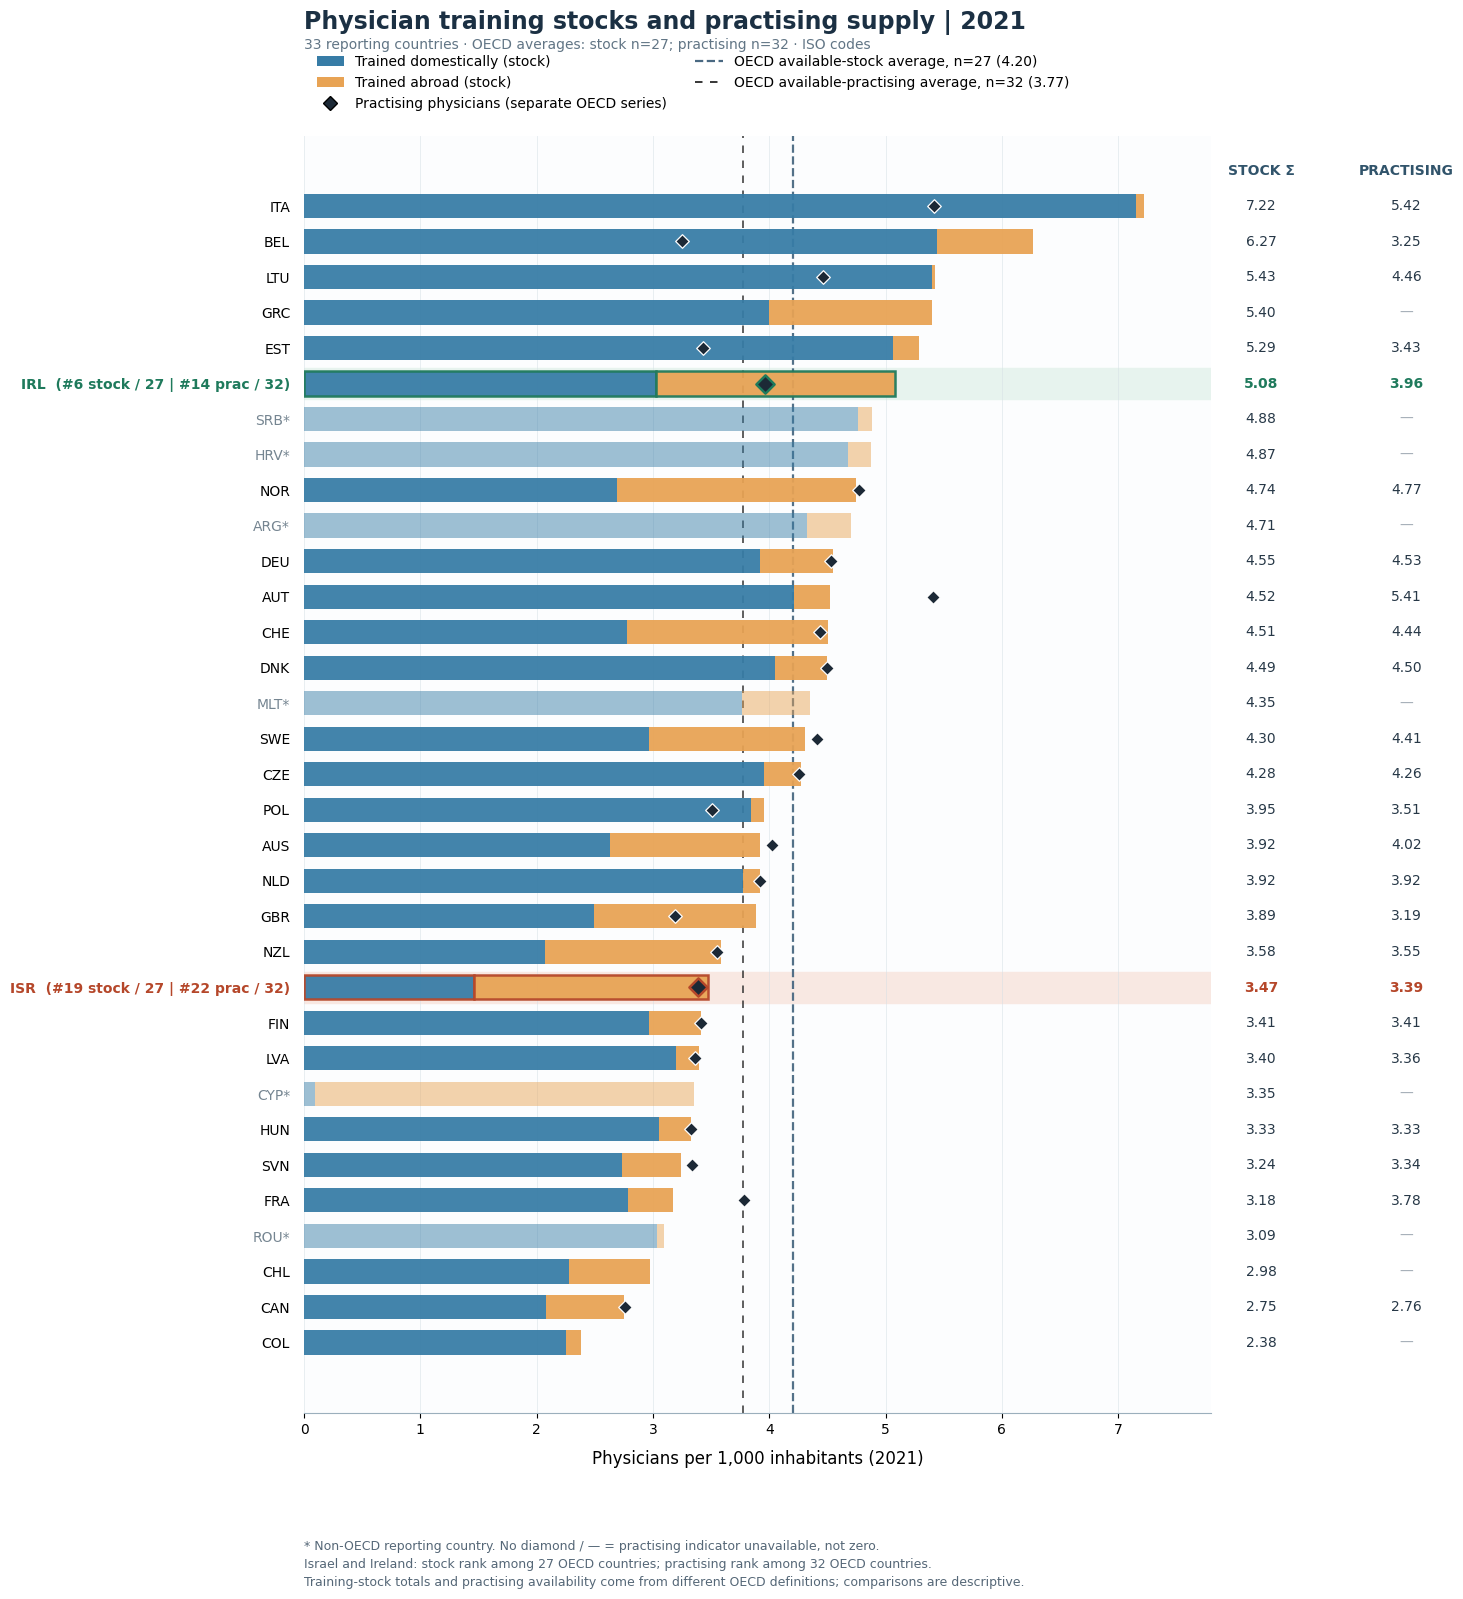

Saved improved chart: charts/oecd_2021_all_countries_with_oecd_avg_lines_highlighted.png
Saved export: exports/OECD_2021_Training_Chart_Highlighted_Ranks.csv


In [20]:
# 3.6.3 — Improved horizontal comparison chart for presentation use (2021)
# Changes: remove OECD median row; replace benchmark row with dashed average lines;
# highlight Israel and Ireland with bold styling and OECD ranks.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

# Reuse the 2021 country-level table created earlier in the notebook.
country_rows = full_country_table.copy()
country_rows = country_rows.sort_values('combined_per_1000', ascending=False).reset_index(drop=True)

# OECD membership list for reference lines and ranking.
oecd_members = {
    'AUS','AUT','BEL','CAN','CHL','COL','CRI','CZE','DNK','EST','FIN',
    'FRA','DEU','GRC','HUN','ISL','IRL','ISR','ITA','JPN','KOR','LVA',
    'LTU','LUX','MEX','NLD','NZL','NOR','POL','PRT','SVK','SVN',
    'ESP','SWE','CHE','TUR','GBR','USA'
}
country_rows['is_oecd_member'] = country_rows['country_code'].isin(oecd_members)

# Two independent OECD benchmarks: each one uses its own AVAILABLE observations.
# Training-stock decomposition needs domestic+foreign counts+population: 27 OECD members.
# Practising series needs only the activity indicator: 32 OECD members.
stock_reference = country_rows.loc[country_rows['is_oecd_member']].copy()
practising_reference = oecd_panel.loc[
    oecd_panel.year.eq(2021) & oecd_panel.oecd_member
    & oecd_panel.practising_per_1000.notna(), ['country_code','practising_per_1000']
].drop_duplicates('country_code')
assert len(stock_reference)==27 and len(practising_reference)==32
stock_mean = stock_reference['combined_per_1000'].mean()
practising_mean = practising_reference['practising_per_1000'].mean()
stock_rank = stock_reference.set_index('country_code')['combined_per_1000'].rank(ascending=False, method='min').astype(int).to_dict()
practising_rank = practising_reference.set_index('country_code')['practising_per_1000'].rank(ascending=False, method='min').astype(int).to_dict()

plot_labels = []
for _, row in country_rows.iterrows():
    code = row['country_code'] + ('' if row['is_oecd_member'] else '*')
    if row['country_code'] in ['ISR', 'IRL']:
        code = f"{code}  (#{stock_rank[row['country_code']]} stock / 27 | #{practising_rank[row['country_code']]} prac / 32)"
    plot_labels.append(code)
country_rows['plot_label'] = plot_labels

fig, ax = plt.subplots(figsize=(16.2, 16.8), facecolor='white')
fig.subplots_adjust(left=.28, right=.84, top=.90, bottom=.14)
ax.set_facecolor('#FCFDFE')

BLUE = '#377CA6'
ORANGE = '#E8A354'
DARK = '#1C2936'
ISRAEL = '#B5472A'
IRELAND = '#1F7A5C'
DEFAULT_ALPHA = .94
NON_OECD_ALPHA = .48

y = np.arange(len(country_rows))
bar_h = .68

for yy, row in zip(y, country_rows.itertuples()):
    if row.country_code == 'ISR':
        ax.axhspan(yy - .44, yy + .44, color='#F8E8E2', zorder=0)
    elif row.country_code == 'IRL':
        ax.axhspan(yy - .44, yy + .44, color='#E7F3EE', zorder=0)

for yy, row in zip(y, country_rows.itertuples()):
    alpha = DEFAULT_ALPHA if row.is_oecd_member else NON_OECD_ALPHA
    edge = 'none'
    lw = 0
    if row.country_code == 'ISR':
        edge = ISRAEL; lw = 1.8
    elif row.country_code == 'IRL':
        edge = IRELAND; lw = 1.8

    ax.barh(yy, row.local_per_1000, height=bar_h, color=BLUE, alpha=alpha,
            edgecolor=edge, linewidth=lw, zorder=2)
    ax.barh(yy, row.abroad_per_1000, left=row.local_per_1000, height=bar_h,
            color=ORANGE, alpha=alpha, edgecolor=edge, linewidth=lw, zorder=2)

    if not np.isnan(row.practising_per_1000):
        marker_size = 86 if row.country_code in ['ISR', 'IRL'] else 48
        marker_edge = ISRAEL if row.country_code == 'ISR' else IRELAND if row.country_code == 'IRL' else 'white'
        marker_lw = 1.8 if row.country_code in ['ISR', 'IRL'] else .9
        ax.scatter(row.practising_per_1000, yy, color=DARK, marker='D', s=marker_size,
                   edgecolors=marker_edge, linewidths=marker_lw, zorder=5)

# OECD average reference lines across the full plotting area.
ax.axvline(stock_mean, color='#4A6982', linestyle='--', linewidth=1.6, alpha=.95, zorder=1)
ax.axvline(practising_mean, color='#2F2F2F', linestyle=(0, (4, 4)), linewidth=1.35, alpha=.8, zorder=1)
# Mean reference values and sample sizes are shown in the legend (not over the bars).

ax.set_yticks(y, country_rows['plot_label'], fontsize=10)
ax.invert_yaxis()
ax.tick_params(axis='y', length=0, pad=10)
ax.tick_params(axis='x', labelsize=10)
for tick, row in zip(ax.get_yticklabels(), country_rows.itertuples()):
    if row.country_code == 'ISR':
        tick.set_fontweight('bold'); tick.set_color(ISRAEL)
    elif row.country_code == 'IRL':
        tick.set_fontweight('bold'); tick.set_color(IRELAND)
    elif not row.is_oecd_member:
        tick.set_color('#758591')

ax.set_xlim(0, 7.8)
ax.set_xlabel('Physicians per 1,000 inhabitants (2021)', fontsize=12, labelpad=10)
ax.grid(axis='x', linestyle='-', color='#D5DFE5', alpha=.55, linewidth=.65, zorder=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#9BAFBC')

text_coords = blended_transform_factory(ax.transAxes, ax.transData)
ax.text(1.055, -1.0, 'STOCK Σ', transform=text_coords, ha='center', va='center',
        weight='bold', color='#31546B', fontsize=10)
ax.text(1.215, -1.0, 'PRACTISING', transform=text_coords, ha='center', va='center',
        weight='bold', color='#31546B', fontsize=10)
for yy, row in zip(y, country_rows.itertuples()):
    color = ISRAEL if row.country_code == 'ISR' else IRELAND if row.country_code == 'IRL' else '#273847'
    weight = 'bold' if row.country_code in ['ISR', 'IRL'] else 'normal'
    ax.text(1.055, yy, f'{row.combined_per_1000:.2f}', transform=text_coords,
            ha='center', va='center', fontsize=10, color=color, fontweight=weight)
    active_label = '—' if np.isnan(row.practising_per_1000) else f'{row.practising_per_1000:.2f}'
    active_color = color if active_label != '—' else '#A4AEB7'
    ax.text(1.215, yy, active_label, transform=text_coords,
            ha='center', va='center', fontsize=10, color=active_color, fontweight=weight)

legend_items = [
    Patch(facecolor=BLUE, label='Trained domestically (stock)'),
    Patch(facecolor=ORANGE, label='Trained abroad (stock)'),
    Line2D([0], [0], marker='D', markersize=7, color='none', markerfacecolor=DARK,
           label='Practising physicians (separate OECD series)'),
    Line2D([0, 1], [0, 0], color='#4A6982', linestyle='--', linewidth=1.6,
           label=f'OECD available-stock average, n=27 ({stock_mean:.2f})'),
    Line2D([0, 1], [0, 0], color='#2F2F2F', linestyle=(0, (4, 4)), linewidth=1.35,
           label=f'OECD available-practising average, n=32 ({practising_mean:.2f})'),
]
ax.legend(handles=legend_items, loc='lower left', bbox_to_anchor=(0, 1.01),
          frameon=False, fontsize=10, ncol=2)
fig.suptitle('Physician training stocks and practising supply | 2021',
             fontsize=17, weight='bold', x=.28, y=.975, ha='left', color='#1B3043')
fig.text(.28, .952,
         '33 reporting countries · OECD averages: stock n=27; practising n=32 · ISO codes',
         ha='left', fontsize=10, color='#617585')
fig.text(.28, .035,
         '* Non-OECD reporting country. No diamond / — = practising indicator unavailable, not zero.\n'
         'Israel and Ireland: stock rank among 27 OECD countries; practising rank among 32 OECD countries.\n'
         'Training-stock totals and practising availability come from different OECD definitions; comparisons are descriptive.',
         ha='left', va='bottom', fontsize=9, color='#556777', linespacing=1.5)

Path('charts').mkdir(exist_ok=True)
presentation_chart_path = Path('charts/oecd_2021_all_countries_with_oecd_avg_lines_highlighted.png')
fig.savefig(presentation_chart_path, dpi=190, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved improved chart:', presentation_chart_path)

highlight_export = country_rows[['country_code','country_name','local_per_1000','abroad_per_1000',
                                 'combined_per_1000','practising_per_1000','is_oecd_member']].copy()
highlight_export['stock_rank_oecd27'] = highlight_export['country_code'].map(stock_rank)
highlight_export['practising_rank_oecd32'] = highlight_export['country_code'].map(practising_rank)
Path('exports').mkdir(exist_ok=True)
highlight_export.to_csv('exports/OECD_2021_Training_Chart_Highlighted_Ranks.csv', index=False, encoding='utf-8-sig')
print('Saved export: exports/OECD_2021_Training_Chart_Highlighted_Ranks.csv')


**איך לקרוא את התרשים המתוקן?** הצבעים בעמודות מחלקים את המלאי להכשרה מקומית ובחו״ל, והיהלום מסמן את מדד הרופאים הפעילים ממקור נפרד. שני הקווים המקווקווים הם ממוצעי **המדינות המדווחות מכל מדד בפני עצמו**, ולא ממוצע של 38 מדינות. אין צורך במדד הבוגרים כדי להציג מלאי רופאים, ולכן לא השמטנו מדינות בשל היעדרו. מדינות ללא יהלום אינן מדינות עם אפס רופאים פעילים — המדד פשוט חסר לנו. דירוגי ישראל ואירלנד מוצגים לפי כלל המדינות הזמינות לכל מדד.


### 3.7 האם מלאי הרופאים לפי מסלול הכשרה קשור לזמינות הרופאים בפועל?

**שאלת המחקר המשנית:** האם במדינות שבהן מלאי הרופאים שהוכשרו מקומית, בחו״ל או בשניהם יחד גדול יותר ביחס לאוכלוסייה — גם שיעור הרופאים הפעילים לאוכלוסייה גבוה יותר?

נבדוק את שנת **2021**, במדינות שלהן קיימים **שני רכיבי מלאי ההכשרה, אוכלוסייה ומדד הרופאים הפעילים** (אין דרישה לנתוני בוגרים), באותה יחידה: **רופאים לכל 1,000 תושבים**.

1. מתאם Pearson בין רופאים שהוכשרו מקומית לבין רופאים פעילים.
2. מתאם Pearson בין רופאים שהוכשרו בחו״ל לבין רופאים פעילים.
3. מתאם Pearson בין סכום שתי קבוצות ההכשרה לבין רופאים פעילים.
4. מודל רגרסיה תיאורי, עם שני מסלולי ההכשרה כשני משתני הסבר נפרדים.
5. Scatter Plot שבו צבע הנקודות מסמן את חלקם של הרופאים שהוכשרו בחו״ל במלאי ההכשרה, וקו מקווקו מייצג שוויון מספרי בין שני מדדי המלאי.

**הסתייגות מרכזית:** הנתונים של `Workforce Migration` ושל `Practising Physicians` אינם בהכרח משתמשים באותה הגדרה ובאותה אוכלוסיית רופאים. לכן המתאמים והרגרסיה מתארים **התאמה בין סדרות מדידה**, לא השפעה סיבתית של הכשרה על זמינות, ולא מנותחים כהשוואה בין זרמים שנתיים של בוגרים.

In [21]:
# 3.7.1 — Pearson correlations and a descriptive two-predictor OLS (OECD 2021)
# All numeric values come from the raw-OECD-derived full_country_table created in 3.6.
cols = ['local_per_1000', 'abroad_per_1000', 'combined_per_1000', 'practising_per_1000']
training_supply = full_country_table.loc[full_country_table.country_code.isin(OECD_MEMBERS)].dropna(subset=cols).copy()
assert training_supply[['country_code','year']].duplicated().sum() == 0
assert len(training_supply) >= 10
assert (training_supply['year'] == 2021).all()

outcome = 'practising_per_1000'
pearson_correlations = pd.DataFrame([
    {'Predictor': 'Domestic-trained physicians / 1k',
     'Pearson r': training_supply['local_per_1000'].corr(training_supply[outcome])},
    {'Predictor': 'Foreign-trained physicians / 1k',
     'Pearson r': training_supply['abroad_per_1000'].corr(training_supply[outcome])},
    {'Predictor': 'Both training stocks / 1k',
     'Pearson r': training_supply['combined_per_1000'].corr(training_supply[outcome])},
])
pearson_correlations['Countries (n)'] = len(training_supply)
print(f'2021 | only training-stock and practising needed: n={len(training_supply)} OECD countries')
display(pearson_correlations.round(3))

# Ordinary Least Squares with two separate predictors, using NumPy only.
# n rows, 3 columns (intercept, domestic stock, foreign stock).
x_ols = np.column_stack([
    np.ones(len(training_supply)),
    training_supply['local_per_1000'].to_numpy(dtype=float),
    training_supply['abroad_per_1000'].to_numpy(dtype=float)
])
y_ols = training_supply[outcome].to_numpy(dtype=float)
coeffs = np.linalg.lstsq(x_ols, y_ols, rcond=None)[0]
y_hat = x_ols @ coeffs
rss = np.square(y_ols - y_hat).sum()
tss = np.square(y_ols - y_ols.mean()).sum()
model_r_squared = 1 - rss / tss
model_coefficients = pd.DataFrame({
    'Coefficient': ['Intercept', 'Domestic trained / 1k', 'Foreign trained / 1k'],
    'Estimate': coeffs
})
print('Descriptive OLS: practising/1k = intercept + b1×domestic/1k + b2×foreign/1k')
display(model_coefficients.round(3))
print(f'R² = {model_r_squared:.3f}')
print('Caution: associations from distinct OECD measures, NOT causal effects.')


2021 | only training-stock and practising needed: n=24 OECD countries


,Predictor,Pearson r,Countries (n)
0,Domestic-trained physicians / 1k,0.479,24
1,Foreign-trained physicians / 1k,-0.035,24
2,Both training stocks / 1k,0.569,24


Descriptive OLS: practising/1k = intercept + b1×domestic/1k + b2×foreign/1k


,Coefficient,Estimate
0,Intercept,2.287
1,Domestic trained / 1k,0.384
2,Foreign trained / 1k,0.388


R² = 0.324
Caution: associations from distinct OECD measures, NOT causal effects.


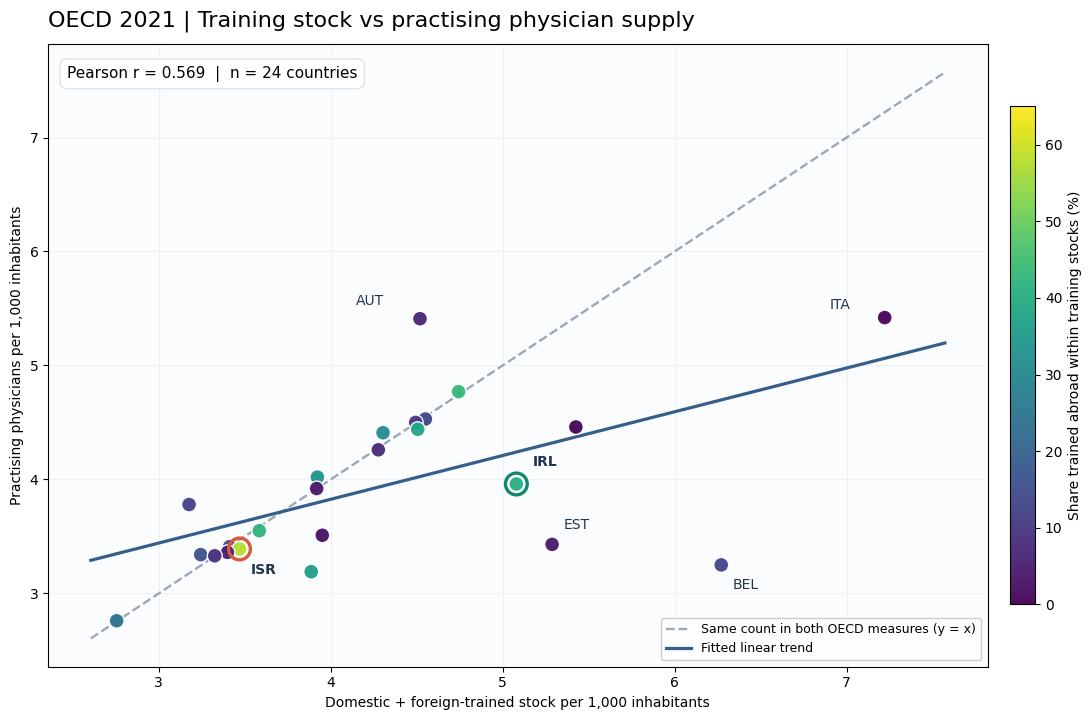

Saved: charts/oecd_2021_training_vs_practising_correlation.png


In [22]:
# 3.7.2 — Reproducible figure: combined training stock vs practising supply
# Color = trained abroad as a share of the two groups; dashed gray = y=x.
import matplotlib.colors as mcolors

plot_supply = training_supply.copy()
plot_supply['foreign_share_of_parts_pct'] = (
    100 * plot_supply['abroad_per_1000'] / plot_supply['combined_per_1000'])
assert plot_supply['foreign_share_of_parts_pct'].between(0, 100).all()

fig, ax = plt.subplots(figsize=(12, 7.3))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fbfcfe')
sc = ax.scatter(
    plot_supply['combined_per_1000'], plot_supply['practising_per_1000'],
    c=plot_supply['foreign_share_of_parts_pct'], s=115,
    cmap='viridis', vmin=0, vmax=65, edgecolors='white', linewidths=1,
    alpha=0.95, zorder=3
)
xs = np.linspace(plot_supply['combined_per_1000'].min() - 0.15,
                 plot_supply['combined_per_1000'].max() + 0.35, 120)
ax.plot(xs, xs, '--', linewidth=1.7, color='#9ba8b5',
        label='Same count in both OECD measures (y = x)')
fit_slope, fit_intercept = np.polyfit(
    plot_supply['combined_per_1000'], plot_supply['practising_per_1000'], deg=1)
ax.plot(xs, fit_intercept + fit_slope*xs, '-', linewidth=2.3, color='#355e88',
        label='Fitted linear trend')

# Label case studies and obvious definition mismatches, not every country.
label_offsets = {'ISR':(8,-18), 'IRL':(12,13), 'BEL':(8,-17),
                 'ITA':(-40,6), 'AUT':(-46,10), 'EST':(8,11)}
for _, row in plot_supply.iterrows():
    if row['country_code'] in label_offsets:
        ax.annotate(row['country_code'],
            xy=(row['combined_per_1000'],row['practising_per_1000']),
            xytext=label_offsets[row['country_code']], textcoords='offset points',
            fontsize=10, fontweight='bold' if row['country_code'] in ('ISR','IRL') else 'normal',
            color='#20364d')
for code, color in [('ISR','#d65a3b'), ('IRL','#14866d')]:
    s=plot_supply[plot_supply['country_code'].eq(code)]
    ax.scatter(s['combined_per_1000'],s['practising_per_1000'],
               s=245,facecolors='none',edgecolors=color,linewidths=2.4,zorder=5)

r_sum = float(pearson_correlations.loc[
    pearson_correlations['Predictor'].eq('Both training stocks / 1k'), 'Pearson r'].iloc[0])
ax.text(0.02,0.965, f'Pearson r = {r_sum:.3f}  |  n = {len(plot_supply)} countries',
        transform=ax.transAxes,va='top',fontsize=11,
        bbox=dict(boxstyle='round,pad=.45',fc='white',ec='#dce4ed'))
ax.set_xlabel('Domestic + foreign-trained stock per 1,000 inhabitants')
ax.set_ylabel('Practising physicians per 1,000 inhabitants')
ax.set_title('OECD 2021 | Training stock vs practising physician supply',loc='left',fontsize=16,pad=13)
ax.grid(alpha=.15)
ax.legend(loc='lower right',fontsize=9,framealpha=.96)
cbar=fig.colorbar(sc,ax=ax,shrink=.8,pad=.02)
cbar.set_label('Share trained abroad within training stocks (%)')
fig.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig_path = Path('charts/oecd_2021_training_vs_practising_correlation.png')
fig.savefig(fig_path,dpi=185,bbox_inches='tight')
plt.show()
print('Saved:',fig_path)


**פענוח התוצאות (נתוני 2021):**

- מתאם מלאי הרופאים שהוכשרו **מקומית** עם מספר הרופאים הפעילים הוא חיובי, אך אינו מעיד שההכשרה המקומית היא הסיבה להיצע.
- מתאם מלאי הרופאים שהוכשרו **בחו״ל** עם מספר הרופאים הפעילים חלש במיוחד כאשר בוחנים אותו בנפרד.
- מתאם **סכום שני סוגי המלאי** עם מספר הרופאים הפעילים חיובי יותר; אך סכום מלאי הרופאים ומספר הרופאים הפעילים הם מדדים קרובים מושגית, ולכן חלק מהקשר אינו מפתיע.
- ברגרסיה משותפת שני המקדמים עשויים להיות חיוביים, אך המודל **תיאורי בלבד**. אין לייחס למקדמים משמעות סיבתית או להניח מובהקות ללא בדיקות מתאימות.
- מדינות שמרוחקות מקו **y = x** מחייבות בדיקת הגדרות, כיסוי ושנות ייחוס לפני הסקת מסקנות על מחסור. ההפרש אינו מייצג אוטומטית "רופאים לא פעילים".

**למצגת:** הגרף העיקרי הוא Scatter Plot של מלאי שתי קבוצות ההכשרה לנפש מול רופאים פעילים לנפש, עם הדגשת ישראל ואירלנד. את טבלת שלושת המתאמים ואת הרגרסיה נשאיר במחברת או נציג רק לפי הצורך. הטענה הנתמכת היא *קשר תיאורי* — לא הוכחה שמסלול הכשרה מסוים מגדיל את הזמינות.

### 3.8 ישראל לאורך זמן, 2010–2024 — האם התמונה משתנה?

נשווה את ישראל ל**חציון כל מדינות OECD המדווחות כל מדד בכל שנה בנפרד**. זהו המדגם הרחב ביותר הזמין למטרת תמונת מצב שנתית, אך מספר המדינות עשוי להשתנות עם הזמן. כדי להימנע מהסקת מגמות רק משום שמדינות נכנסות ויוצאות מהמדגם, נוסיף קו דק שמייצג **חציון מדגם קבוע של מדינות שמדווחות ברציפות בכל 15 השנים**. ליד כל מדד נציג `n` של שתי הגישות. כך נשמור גם כיסוי רחב וגם אפשרות לבדיקת יציבות לאורך זמן.


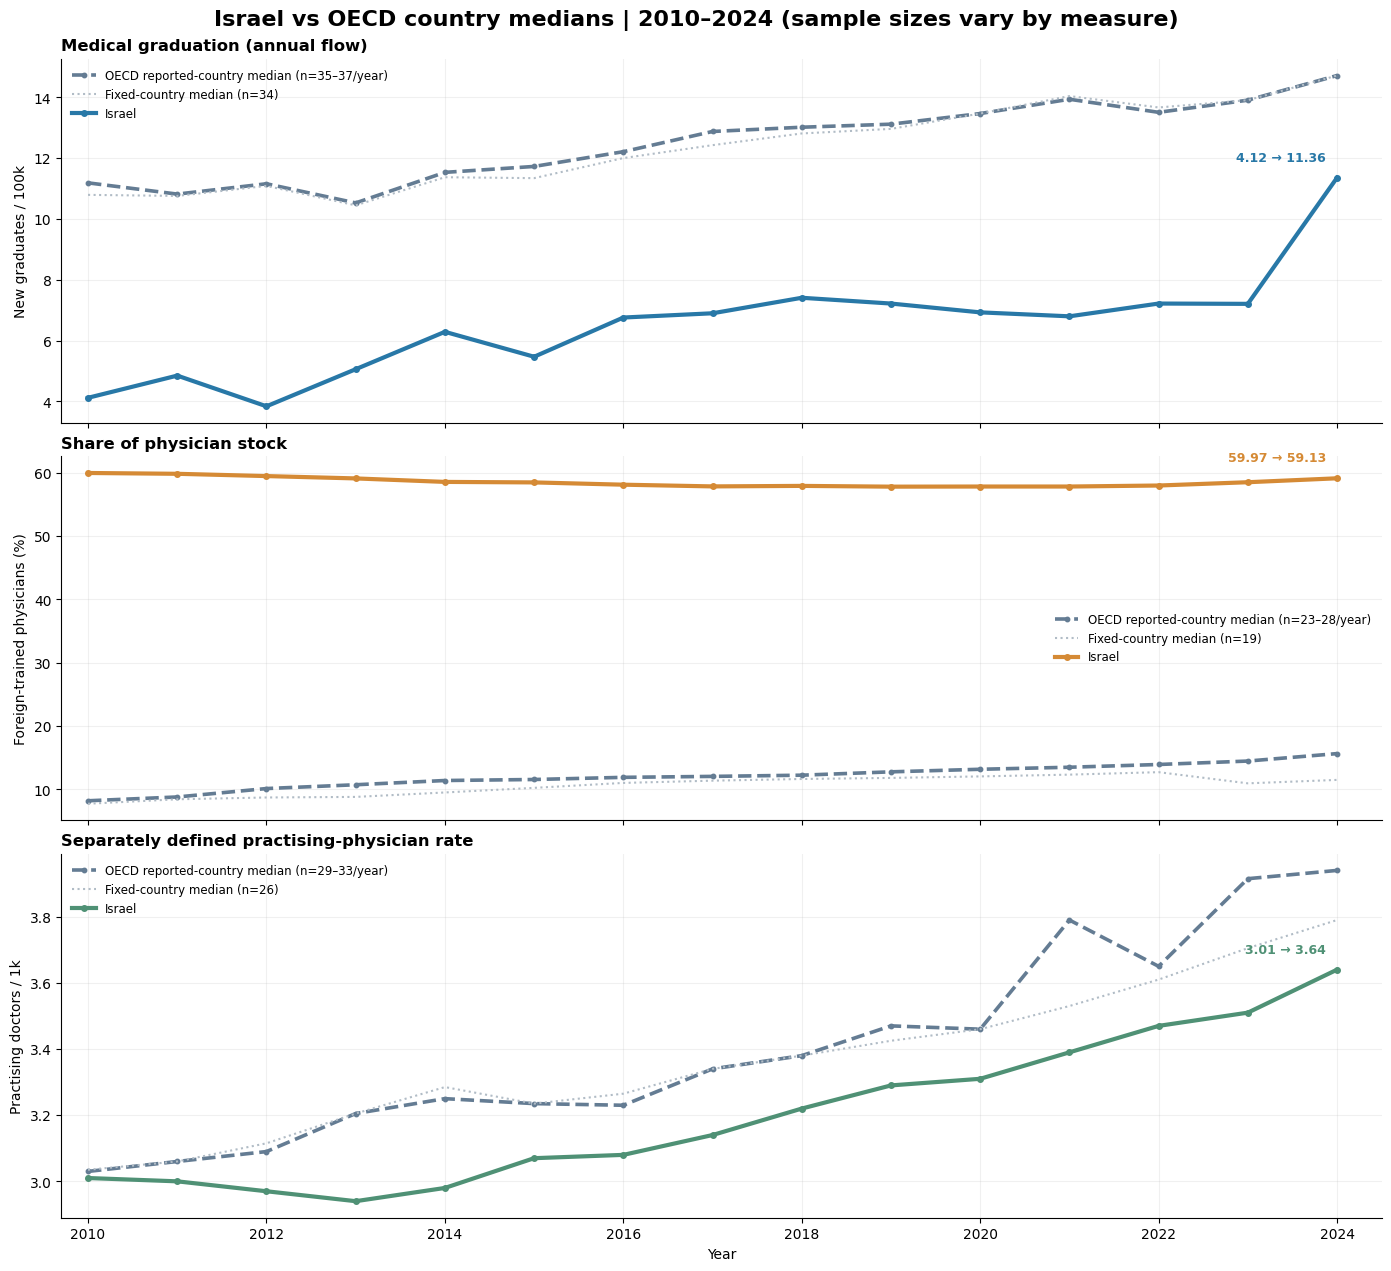

Annual OECD coverage by measure, minimum–maximum n:


OECD_reporting_countries_n     fixed_countries_n    
                                           min max               min max
metric                                                                  
foreign_trained_pct                         23  28                19  19
graduates_per_100k                          35  37                34  34
practising_per_1000                         29  33                26  26

Plot: charts/oecd_israel_vs_fixed_oecd_medians_2010_2024.png


In [23]:
# 3.8 — Israel trends and OECD medians: available-case yearly sample + fixed-cohort sensitivity
from matplotlib.ticker import MaxNLocator
indicator_specs=[
    ('graduates_per_100k','New graduates / 100k','Medical graduation (annual flow)','#2878A7'),
    ('foreign_trained_pct','Foreign-trained physicians (%)','Share of physician stock','#D58A35'),
    ('practising_per_1000','Practising doctors / 1k','Separately defined practising-physician rate','#4F9175')]
period_years=list(range(2010,2025))
period_panel=oecd_panel.loc[oecd_panel.year.isin(period_years) & oecd_panel.oecd_member].copy()
assert not period_panel.duplicated(['country_code','year']).any()
fig,axes=plt.subplots(3,1,figsize=(13.8,12.6),sharex=True,constrained_layout=True)
trends_export=[]
fixed_cohort_sizes={}
for ax,(col,ylabel,title,color) in zip(axes,indicator_specs):
    observations=period_panel[['country_code','year',col]].dropna(subset=[col]).copy()
    yearly=observations.groupby('year')[col].agg(median='median',n='count').reindex(period_years)
    fixed_codes=observations.groupby('country_code')['year'].nunique()
    fixed_codes=set(fixed_codes.loc[fixed_codes.eq(len(period_years))].index)
    fixed=observations.loc[observations.country_code.isin(fixed_codes)]
    fixed_median=fixed.groupby('year')[col].median().reindex(period_years)
    israel=observations.loc[observations.country_code.eq('ISR')].set_index('year')[col].reindex(period_years)
    fixed_cohort_sizes[col]=len(fixed_codes)
    assert israel.notna().all()
    ax.plot(period_years,yearly['median'],color='#647C93',linewidth=2.6,
            linestyle='--',marker='o',markersize=3.2,
            label=f'OECD reported-country median (n={int(yearly.n.min())}–{int(yearly.n.max())}/year)')
    if len(fixed_codes)>=3:
        ax.plot(period_years,fixed_median,color='#B1BCC6',linewidth=1.5,
                linestyle=':',label=f'Fixed-country median (n={len(fixed_codes)})')
    ax.plot(period_years,israel,color=color,linewidth=3,marker='o',markersize=4.0,label='Israel')
    ax.set_title(title,loc='left',fontsize=11.8,weight='bold')
    ax.set_ylabel(ylabel,fontsize=10)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=.18)
    ax.legend(loc='best',frameon=False,fontsize=8.5)
    ax.annotate(f'{israel.loc[2010]:.2f} → {israel.loc[2024]:.2f}',xy=(2024,israel.loc[2024]),
                xytext=(-8,12),textcoords='offset points',ha='right',color=color,weight='bold',fontsize=9)
    for yr in period_years:
        for series,seriesval in [('Israel',israel.loc[yr]),('OECD available-case median',yearly.loc[yr,'median']),
                                 ('OECD fixed-country median',fixed_median.loc[yr])]:
            trends_export.append({'year':yr,'metric':col,'series':series,'value':seriesval,
                                  'OECD_reporting_countries_n':int(yearly.loc[yr,'n']),
                                  'fixed_countries_n':int(len(fixed_codes))})
axes[-1].set_xlim(2009.7,2024.5);axes[-1].set_xticks(period_years[::2]);axes[-1].set_xlabel('Year')
fig.suptitle('Israel vs OECD country medians | 2010–2024 (sample sizes vary by measure)',
             fontsize=16,weight='bold')
Path('charts').mkdir(exist_ok=True)
chart38=Path('charts/oecd_israel_vs_fixed_oecd_medians_2010_2024.png')
fig.savefig(chart38,dpi=180,bbox_inches='tight')
plt.show()
trend_table=pd.DataFrame(trends_export)
Path('exports').mkdir(exist_ok=True)
trend_table.to_csv('exports/OECD_2010_2024_Israel_vs_fixed_medians.csv',index=False,encoding='utf-8-sig')
print('Annual OECD coverage by measure, minimum–maximum n:')
display(trend_table.loc[trend_table.series.eq('OECD available-case median')].groupby('metric')[
    ['OECD_reporting_countries_n','fixed_countries_n']].agg(['min','max']))
print('Plot:',chart38)


**קריאת מגמות:** בישראל עלה מספר בוגרי הרפואה מ־4.12 ל־11.36 ל־100 אלף תושבים בשנים 2010–2024, ומדד הרופאים הפעילים מ־3.01 ל־3.64 לאלף. שיעור הרופאים שהוכשרו בחו״ל השתנה מ־59.97% ל־59.13%. הקו המקווקו של OECD משתמש בכל המדינות המדווחות בכל שנה; הקו המנוקד מאפשר בדיקת רגישות מול מדינות שמדווחות ברצף. אין להניח שחציון OECD מייצג את כל 38 המדינות, או ששינוי בבוגרים גורם ישירות לשינוי בזמינות. הסתייגות נוספת: קפיצה בסדרת הבוגרים ב־2024 מחייבת בדיקת הגדרה לפני פרשנות מדיניות.


### 3.9 מאיפה הגידול במלאי הרופאים בישראל, 2010–2024?

**השאלה:** בכמה גדל *המלאי המדווח* של רופאים שהוכשרו בישראל לעומת רופאים שהוכשרו בחו״ל? נחשב את ההפרש בין נקודת הסיום לנקודת ההתחלה מתוך **ספירות הרופאים המוחלטות** בקובץ Workforce Migration. נוכל גם להשוות את *אחוז הגידול ביחס למלאי בתחילת התקופה* במספר מדינות בעלות שתי נקודות קצה מלאות.

**הסתייגות חשובה:** שינוי במלאי הוא לא מספר הרופאים החדשים שהצטרפו נטו בעקבות הכשרה בשנת נתונה. המלאי מושפע גם מפרישה, הגירה, פעילות מקצועית והגדרות דיווח. סכום שתי קבוצות ההכשרה עשוי להיות שונה במעט מסך הרופאים המדווח; לכן נחשב במפורש את **סכום שתי הקבוצות בלבד**. לצורך השוואת מדינות נשתמש בשינויים *יחסיים למלאי בתחילת התקופה*, ולא במספרים מוחלטים שאינם בני השוואה בין אוכלוסיות גדולות וקטנות.

Countries with both training stocks in both endpoint years: 20
Israel: 2010 domestic/abroad 10306.0 15466.0
Israel: 2024 domestic/abroad 15044.0 21777.0
Israel changes (domestic; abroad; both): 4738.0 6311.0 11049.0
Israel foreign-trained share of change in two stocks: 57.1%


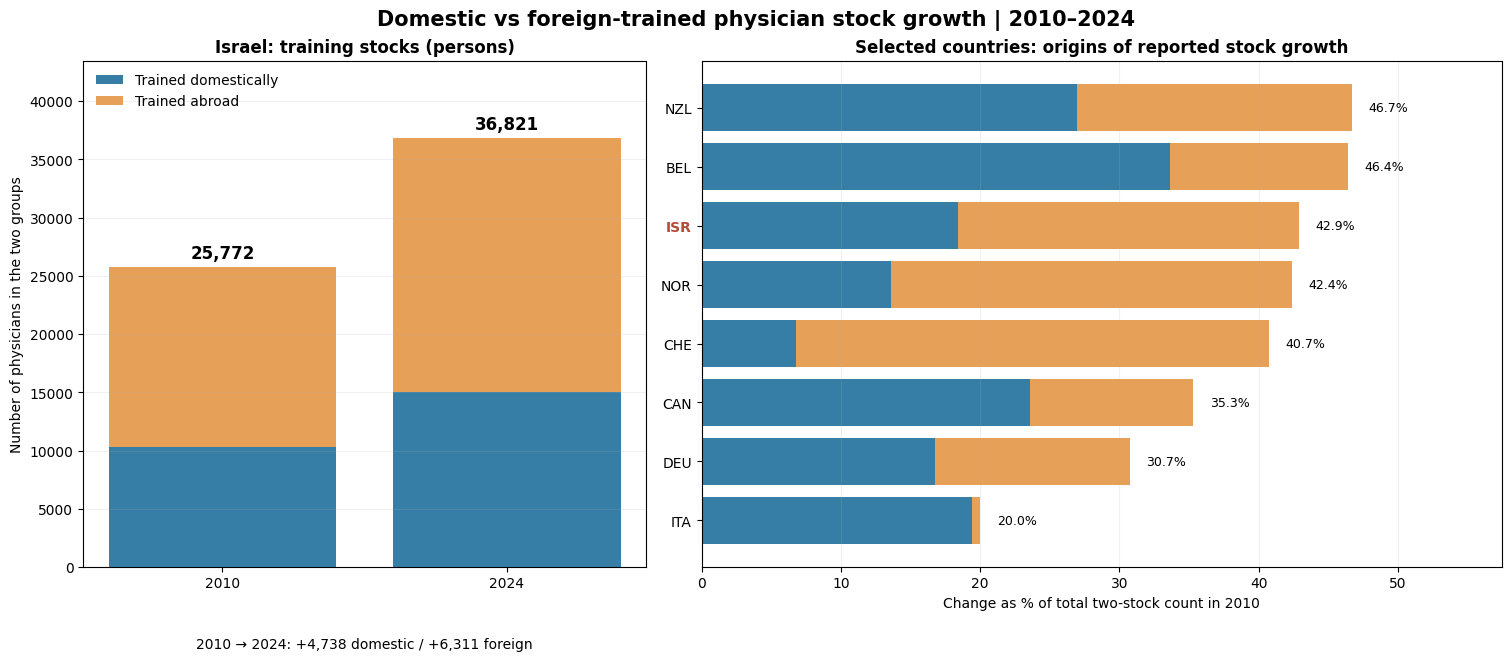

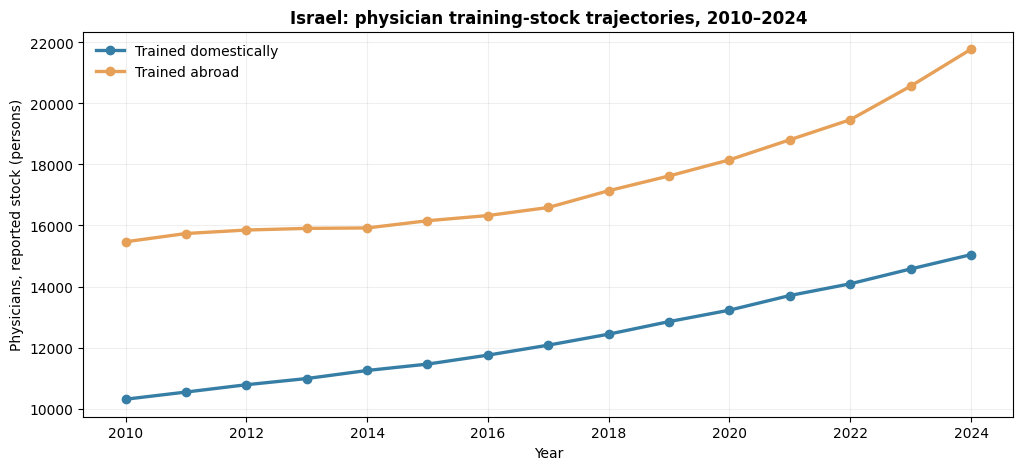

Saved charts: charts/oecd_training_stock_change_2010_2024.png charts/oecd_israel_training_stocks_2010_2024.png
Selected country stock growth (percentage of its own 2010 baseline):


TRAINING_PLACE,delta_domestic,delta_foreign,delta_combined,domestic_change_pct_of_start_total,foreign_change_pct_of_start_total,combined_change_pct_of_start_total,foreign_share_of_change_pct
country_code,,,,,,,
ITA,72289.0,2134.0,74423.0,19.4,0.6,20.0,2.9
DEU,51049.0,42693.0,93742.0,16.7,14.0,30.7,45.5
CAN,19053.0,9474.0,28527.0,23.6,11.7,35.3,33.2
CHE,2053.0,10276.0,12329.0,6.8,33.9,40.7,83.3
NOR,2686.0,5666.0,8352.0,13.6,28.7,42.4,67.8
ISR,4738.0,6311.0,11049.0,18.4,24.5,42.9,57.1
BEL,17984.0,6804.0,24788.0,33.7,12.7,46.4,27.4
NZL,3667.0,2696.0,6363.0,26.9,19.8,46.7,42.4


In [24]:
# 3.9 — Stock growth by training place; report 2010 → 2024 endpoints.
# Do NOT confuse 2010–2024 stock changes with entrants, graduates, or causal effects.
stocks = oecd_migration.loc[
    oecd_migration['UNIT_MEASURE'].eq('PS')
    & oecd_migration['TRAINING_PLACE'].isin(['DOMESTIC','FOREIGN'])
    & oecd_migration['TIME_PERIOD'].isin([2010,2024]),
    ['REF_AREA','TIME_PERIOD','TRAINING_PLACE','OBS_VALUE']
].copy()
assert not stocks.duplicated(['REF_AREA','TIME_PERIOD','TRAINING_PLACE']).any()
endpoints = stocks.pivot(index=['REF_AREA','TIME_PERIOD'],
                           columns='TRAINING_PLACE',values='OBS_VALUE').reset_index()
start = endpoints.loc[endpoints.TIME_PERIOD.eq(2010)].set_index('REF_AREA')
end = endpoints.loc[endpoints.TIME_PERIOD.eq(2024)].set_index('REF_AREA')
common = start[['DOMESTIC','FOREIGN']].join(end[['DOMESTIC','FOREIGN']],
                                            lsuffix='_2010',rsuffix='_2024',how='inner').dropna().copy()
common.index.name = 'country_code'
for cls in ['DOMESTIC','FOREIGN']:
    common[f'delta_{cls.lower()}'] = common[f'{cls}_2024'] - common[f'{cls}_2010']
common['start_combined'] = common['DOMESTIC_2010'] + common['FOREIGN_2010']
common['end_combined'] = common['DOMESTIC_2024'] + common['FOREIGN_2024']
common['delta_combined'] = common['delta_domestic'] + common['delta_foreign']
for kind in ['domestic','foreign','combined']:
    common[f'{kind}_change_pct_of_start_total'] = 100 * common[f'delta_{kind}'] / common['start_combined']
common['foreign_share_of_change_pct'] = 100 * common['delta_foreign'] / common['delta_combined'].replace(0,np.nan)
assert (common['start_combined']>0).all()
assert 'ISR' in common.index
il=common.loc['ISR']
print('Countries with both training stocks in both endpoint years:',len(common))
print('Israel: 2010 domestic/abroad',il['DOMESTIC_2010'],il['FOREIGN_2010'])
print('Israel: 2024 domestic/abroad',il['DOMESTIC_2024'],il['FOREIGN_2024'])
print('Israel changes (domestic; abroad; both):',
      il['delta_domestic'],il['delta_foreign'],il['delta_combined'])
print('Israel foreign-trained share of change in two stocks:',
      f'{il["foreign_share_of_change_pct"]:.1f}%')

# Left panel: absolute stock change in Israel (two bars).
# Right panel: comparable percentage-point contributions to stock growth
# (each segment is change in stock / total stock in 2010).
compare_codes = ['ISR','NOR','CHE','NZL','CAN','DEU','BEL','ITA']
comp = common.reindex(compare_codes).dropna(subset=['start_combined']).copy()
# All selected comparisons have positive changes in both groups; assert before stacking.
assert comp[['delta_domestic','delta_foreign']].ge(0).all().all()
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(15,6.5),
                                gridspec_kw={'width_ratios':[.95,1.35]},
                                constrained_layout=True)
BLUE='#367EA5'; ORANGE='#E6A058'
ax1.bar(['2010','2024'],[il['DOMESTIC_2010'],il['DOMESTIC_2024']],
        color=BLUE,label='Trained domestically')
ax1.bar(['2010','2024'],[il['FOREIGN_2010'],il['FOREIGN_2024']],
        bottom=[il['DOMESTIC_2010'],il['DOMESTIC_2024']],
        color=ORANGE,label='Trained abroad')
for i,year in enumerate([2010,2024]):
    total = il['start_combined'] if year==2010 else il['end_combined']
    ax1.text(i,total+750,f'{total:,.0f}',ha='center',fontsize=12,fontweight='bold')
ax1.set_ylim(0,il['end_combined']*1.18)
ax1.set_title('Israel: training stocks (persons)',fontweight='bold')
ax1.set_ylabel('Number of physicians in the two groups')
ax1.grid(axis='y',alpha=.18)
ax1.legend(loc='upper left',frameon=False)
ax1.text(.5,-.16,
         f'2010 → 2024: +{il["delta_domestic"]:,.0f} domestic / +{il["delta_foreign"]:,.0f} foreign',
         transform=ax1.transAxes,ha='center',fontsize=10)
comp=comp.sort_values('combined_change_pct_of_start_total',ascending=True)
y=np.arange(len(comp))
ax2.barh(y,comp['domestic_change_pct_of_start_total'],color=BLUE,label='Domestic-stock change')
ax2.barh(y,comp['foreign_change_pct_of_start_total'],left=comp['domestic_change_pct_of_start_total'],
         color=ORANGE,label='Foreign-stock change')
for k,(code,row) in enumerate(comp.iterrows()):
    ax2.text(row['combined_change_pct_of_start_total']+1.2,k,
             f'{row["combined_change_pct_of_start_total"]:.1f}%',va='center',fontsize=9)
ax2.set_yticks(y,comp.index)
for t in ax2.get_yticklabels():
    if t.get_text()=='ISR':t.set_color('#B34B39');t.set_weight('bold')
ax2.set_xlim(0,max(comp['combined_change_pct_of_start_total'])*1.23)
ax2.set_xlabel('Change as % of total two-stock count in 2010')
ax2.set_title('Selected countries: origins of reported stock growth',fontweight='bold')
ax2.grid(axis='x',alpha=.18)
fig.suptitle('Domestic vs foreign-trained physician stock growth | 2010–2024',
             fontsize=15,fontweight='bold')
chart39=Path('charts/oecd_training_stock_change_2010_2024.png')
fig.savefig(chart39,dpi=190,bbox_inches='tight')
plt.show()

# Longitudinal Israel trajectory: these are the SOURCE headcounts, not graduates.
israel_stock = oecd_migration.loc[
    oecd_migration['REF_AREA'].eq('ISR')
    & oecd_migration['UNIT_MEASURE'].eq('PS')
    & oecd_migration['TRAINING_PLACE'].isin(['DOMESTIC','FOREIGN']),
    ['TIME_PERIOD','TRAINING_PLACE','OBS_VALUE']
].pivot(index='TIME_PERIOD',columns='TRAINING_PLACE',values='OBS_VALUE').sort_index()
fig2,ax=plt.subplots(figsize=(12,5))
for train,color,label in [('DOMESTIC',BLUE,'Trained domestically'),
                          ('FOREIGN',ORANGE,'Trained abroad')]:
    ax.plot(israel_stock.index,israel_stock[train],marker='o',lw=2.4,
            color=color,label=label)
ax.set_title('Israel: physician training-stock trajectories, 2010–2024',fontweight='bold')
ax.set_ylabel('Physicians, reported stock (persons)')
ax.set_xlabel('Year');ax.legend(frameon=False);ax.grid(alpha=.2)
chart39b=Path('charts/oecd_israel_training_stocks_2010_2024.png')
fig2.savefig(chart39b,dpi=180,bbox_inches='tight')
plt.show()

common.reset_index().to_csv('exports/OECD_2010_2024_stock_growth_by_country.csv',
                             index=False,encoding='utf-8-sig')
israel_stock.to_csv('exports/Israel_2010_2024_training_stock_series.csv',encoding='utf-8-sig')
print('Saved charts:',chart39,chart39b)
print('Selected country stock growth (percentage of its own 2010 baseline):')
display(comp[['delta_domestic','delta_foreign','delta_combined',
              'domestic_change_pct_of_start_total','foreign_change_pct_of_start_total',
              'combined_change_pct_of_start_total','foreign_share_of_change_pct']].round(1))


**קריאת ממצאי ישראל:** מתוך שתי קבוצות ההכשרה, המלאי המדווח גדל מ־25,772 רופאים בשנת 2010 ל־36,821 בשנת 2024 — תוספת של **11,049**. מתוכה **4,738** רופאים שהוכשרו בישראל (כ־42.9% מהגידול) ו־**6,311** שהוכשרו בחו״ל (כ־57.1%). בשנת 2024 חלקם של בוגרי חו״ל עדיין גבוה, אף שבישראל חלה לאורך השנים עלייה במספר בוגרי הרפואה המקומיים ל־100 אלף תושבים.

**זה לא נתון על גיוס בפועל של 6,311 רופאים מחו״ל**: זה שינוי במלאי רופאים שהוכשרו מחוץ לישראל, שיכול לכלול ישראלים שלמדו בחו״ל וכולל את השפעת היציאה ממלאי המדווח. סכומי שתי קבוצות ההכשרה שונים מעט מסך הרופאים המדווח — ולכן לא החלפנו ביניהם.

**מגבלות ההשוואה:** מדינות השוואה נבחרו מראש כמדגם הדגמה מתוך המדינות בעלות שתי נקודות קצה תקינות, ולא כדי לייצג את כל OECD. אירלנד אינה מופיעה בהשוואת השינוי ל־2010 משום שבקובץ שהורד אין לה שתי קבוצות מלאי תקינות בשנת הבסיס; לא משלימים ערכים חסרים בהערכה.

### 3.10 האם הגידול במלאי הרופאים בישראל הדביק את גידול האוכלוסייה?

**שאלת המשך בעקבות סעיף 3.9:** גילינו שגדל מלאי הרופאים שהוכשרו מקומית ובחו״ל, אך מספרים מוחלטים אינם מספיקים כדי לבדוק אם היצע הרופאים **לנפש** השתפר. נשלב את ספירות שתי קבוצות ההכשרה של ישראל מתוך OECD עם נתוני האוכלוסייה השנתיים של הבנק העולמי ונבחן את השנים **2010–2024**.

מקורות: 
- מלאי רופאים לפי מקום הכשרה: קובץ `oecd_migration.csv` שכבר נטען למחברת. מסננים `UNIT_MEASURE = PS`, `TRAINING_PLACE = DOMESTIC / FOREIGN` וישראל (`ISR`).
- אוכלוסייה: הבנק העולמי, האינדיקטור [`SP.POP.TOTL`](https://data.worldbank.org/indicator/SP.POP.TOTL?locations=IL), קובץ `data/israel_population_2010_2024_world_bank.csv` (הערכים השנתיים נשמרו יחד עם המחברת; מקור הערכים: World Development Indicators).
- **בקרה חיצונית נפרדת:** נתוני `Practising Physicians` של OECD, המייצגים מדד אחר של רופאים פעילים ולא בהכרח אותה קבוצת רופאים שיש במלאי ההכשרה.

נחשב: (1) מדדי צמיחה עם שנת בסיס 2010=100, (2) מלאי הרופאים שהוכשרו מקומית ובחו״ל **ל־1,000 תושבים**, (3) שינוי יחסי בין 2010 ל־2024. החישובים נעשים מתוך נתוני המקור, ללא החלקת מגמות או השלמת שנים חסרות.

**חשוב:** עלייה במלאי מנורמל איננה הוכחה לשיפור בזמינות הרופאים המטפלים, משום שספירות Workforce Migration עשויות לכלול רופאים שאינם מספקים טיפול פעיל. נעזר במדד הרופאים הפעילים כדי לבדוק את כיוון השינוי — בנפרד, בלי לסכום בין הסדרות.

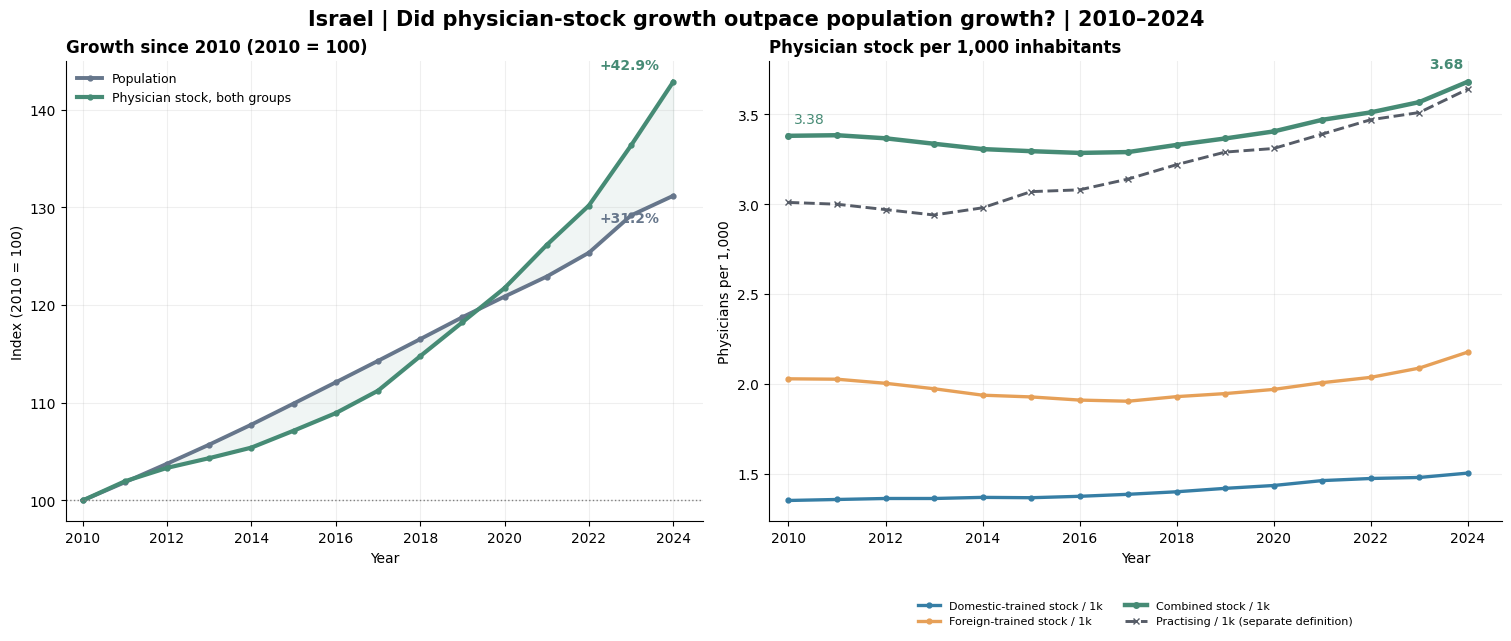

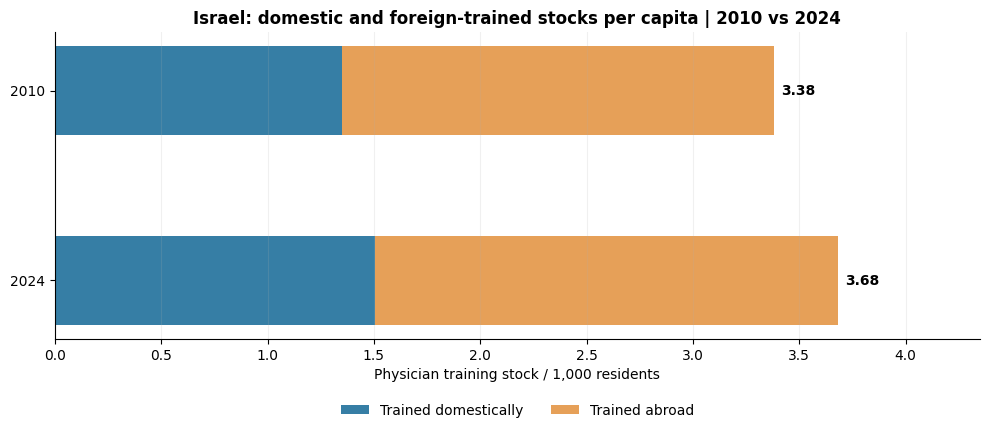

Growth comparison, 2010→2024:


,measure,2010,2024,change_pct
0,Population (persons),7623600.000,1.000220e+07,31.20
1,Domestic-trained physicians (stock),10306.000,1.504400e+04,45.97
2,Foreign-trained physicians (stock),15466.000,2.177700e+04,40.81
3,Combined training stocks (persons),25772.000,3.682100e+04,42.87
4,"Domestic stock / 1,000",1.352,1.504000e+00,11.26
5,"Foreign stock / 1,000",2.029,2.177000e+00,7.32
6,"Combined stock / 1,000",3.381,3.681000e+00,8.90
7,"Practising physicians / 1,000 (separate series)",3.010,3.640000e+00,20.93


Year-by-year normalized data:


,population,domestic_stock,foreign_stock,combined_stock,domestic_per1000,foreign_per1000,combined_per1000,practising_per_1000
year,,,,,,,,
2010,7623600,10306.0,15466.0,25772.0,1.352,2.029,3.381,3.01
2011,7765800,10541.0,15737.0,26278.0,1.357,2.026,3.384,3.00
2012,7910500,10781.0,15851.0,26632.0,1.363,2.004,3.367,2.97
2013,8059500,10984.0,15905.0,26889.0,1.363,1.973,3.336,2.94
2014,8215700,11248.0,15919.0,27167.0,1.369,1.938,3.307,2.98
2015,8380100,11457.0,16156.0,27613.0,1.367,1.928,3.295,3.07
2016,8546000,11751.0,16326.0,28077.0,1.375,1.910,3.285,3.08
2017,8713300,12078.0,16590.0,28668.0,1.386,1.904,3.290,3.14
2018,8882800,12438.0,17140.0,29578.0,1.400,1.930,3.330,3.22


Saved two figures in charts/ and two detailed CSV files in exports/


In [25]:
# 3.10 — Israel population growth vs physician training stocks, 2010–2024
# World Bank SP.POP.TOTL + OECD Workforce Migration.
# Source indicator: https://data.worldbank.org/indicator/SP.POP.TOTL?locations=IL

from matplotlib.ticker import FuncFormatter

pop = pd.read_csv(DATA / 'israel_population_2010_2024_world_bank.csv')
pop['year'] = pd.to_numeric(pop['year'], errors='raise').astype(int)
pop['population'] = pd.to_numeric(pop['population'], errors='raise').astype(int)
assert pop['year'].is_unique and (pop.population > 0).all()
assert set(pop.year) == set(range(2010, 2025)), 'Missing or extra population years'

il_stock = (oecd_migration.loc[
    oecd_migration['REF_AREA'].eq('ISR') &
    oecd_migration['UNIT_MEASURE'].eq('PS') &
    oecd_migration['TRAINING_PLACE'].isin(['DOMESTIC','FOREIGN']) &
    oecd_migration['TIME_PERIOD'].between(2010, 2024),
    ['TIME_PERIOD','TRAINING_PLACE','OBS_VALUE']
].copy())
assert not il_stock.duplicated(['TIME_PERIOD', 'TRAINING_PLACE']).any()
il_stock = il_stock.pivot(index='TIME_PERIOD', columns='TRAINING_PLACE',values='OBS_VALUE')
il_stock.index.name = 'year'
assert il_stock[['DOMESTIC','FOREIGN']].notna().all().all(), 'Incomplete OECD training-stock series'
assert set(il_stock.index) == set(pop['year']), 'Year mismatch between OECD and World Bank'

israel_pop_phys = pop.set_index('year').join(il_stock, how='inner').sort_index()
israel_pop_phys = israel_pop_phys.rename(columns={'DOMESTIC':'domestic_stock','FOREIGN':'foreign_stock'})
israel_pop_phys['combined_stock'] = israel_pop_phys['domestic_stock'] + israel_pop_phys['foreign_stock']
for name in ['domestic','foreign','combined']:
    israel_pop_phys[f'{name}_per1000'] = 1000 * israel_pop_phys[f'{name}_stock'] / israel_pop_phys['population']

# Separate definition — not part of the combined training-stock calculation.
practising_israel = (oecd_panel.loc[
    oecd_panel['country_code'].eq('ISR') & oecd_panel['year'].between(2010,2024),
    ['year','practising_per_1000']
].drop_duplicates(subset=['year']).set_index('year'))
israel_pop_phys = israel_pop_phys.join(practising_israel, how='left')

for col in ['population','domestic_stock','foreign_stock','combined_stock']:
    israel_pop_phys[f'{col}_index_2010'] = 100 * israel_pop_phys[col] / israel_pop_phys.loc[2010, col]

x0, x1 = israel_pop_phys.loc[2010], israel_pop_phys.loc[2024]
changes = pd.DataFrame([
    {'measure':'Population (persons)', '2010':x0.population,'2024':x1.population,
     'change_pct':(x1.population/x0.population-1)*100},
    {'measure':'Domestic-trained physicians (stock)', '2010':x0.domestic_stock,'2024':x1.domestic_stock,
     'change_pct':(x1.domestic_stock/x0.domestic_stock-1)*100},
    {'measure':'Foreign-trained physicians (stock)', '2010':x0.foreign_stock,'2024':x1.foreign_stock,
     'change_pct':(x1.foreign_stock/x0.foreign_stock-1)*100},
    {'measure':'Combined training stocks (persons)', '2010':x0.combined_stock,'2024':x1.combined_stock,
     'change_pct':(x1.combined_stock/x0.combined_stock-1)*100},
    {'measure':'Domestic stock / 1,000', '2010':x0.domestic_per1000,'2024':x1.domestic_per1000,
     'change_pct':(x1.domestic_per1000/x0.domestic_per1000-1)*100},
    {'measure':'Foreign stock / 1,000', '2010':x0.foreign_per1000,'2024':x1.foreign_per1000,
     'change_pct':(x1.foreign_per1000/x0.foreign_per1000-1)*100},
    {'measure':'Combined stock / 1,000', '2010':x0.combined_per1000,'2024':x1.combined_per1000,
     'change_pct':(x1.combined_per1000/x0.combined_per1000-1)*100},
    {'measure':'Practising physicians / 1,000 (separate series)',
     '2010':x0.practising_per_1000,'2024':x1.practising_per_1000,
     'change_pct':(x1.practising_per_1000/x0.practising_per_1000-1)*100},
])
assert x1.combined_per1000 > x0.combined_per1000
assert abs(changes.loc[changes.measure.eq('Combined training stocks (persons)'), 'change_pct'].iloc[0] - 42.8721) < .05

# Figure 1 — population vs total stock (indexed), and normalised stocks over time.
BLUE='#367EA5'; ORANGE='#E6A058'; GREEN='#468B75'; GREY='#66768B'
years = israel_pop_phys.index.to_numpy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.3),
    gridspec_kw={'width_ratios':[1, 1.15]}, constrained_layout=True)

ax1.plot(years, israel_pop_phys.population_index_2010, color=GREY,
         lw=2.8, marker='o', markersize=3.5, label='Population')
ax1.plot(years, israel_pop_phys.combined_stock_index_2010, color=GREEN,
         lw=3, marker='o', markersize=3.5, label='Physician stock, both groups')
ax1.fill_between(years, israel_pop_phys.population_index_2010.to_numpy(float),
                 israel_pop_phys.combined_stock_index_2010.to_numpy(float),
                 color=GREEN, alpha=.08)
ax1.axhline(100, color='grey', ls=':', lw=1)
ax1.set_title('Growth since 2010 (2010 = 100)', loc='left', fontweight='bold')
ax1.set_ylabel('Index (2010 = 100)'); ax1.set_xlabel('Year')
ax1.annotate(f'+{(x1.combined_stock/x0.combined_stock - 1)*100:.1f}%',
    (2024, israel_pop_phys.loc[2024,'combined_stock_index_2010']),
    xytext=(-10, 9), textcoords='offset points', ha='right',color=GREEN,fontweight='bold')
ax1.annotate(f'+{(x1.population/x0.population - 1)*100:.1f}%',
    (2024, israel_pop_phys.loc[2024,'population_index_2010']),
    xytext=(-10, -19), textcoords='offset points', ha='right',color=GREY,fontweight='bold')
ax1.legend(frameon=False,loc='upper left',fontsize=9)

ax2.plot(years, israel_pop_phys.domestic_per1000, color=BLUE,
         lw=2.4, marker='o', markersize=3.5,label='Domestic-trained stock / 1k')
ax2.plot(years, israel_pop_phys.foreign_per1000, color=ORANGE,
         lw=2.4,marker='o',markersize=3.5,label='Foreign-trained stock / 1k')
ax2.plot(years, israel_pop_phys.combined_per1000, color=GREEN,
         lw=3.2, marker='o', markersize=4,label='Combined stock / 1k')
ax2.plot(years, israel_pop_phys.practising_per_1000, color='#565C67',
         lw=2.1, linestyle='--', marker='x', markersize=4,
         label='Practising / 1k (separate definition)')
ax2.set_title('Physician stock per 1,000 inhabitants',loc='left',fontweight='bold')
ax2.set_ylabel('Physicians per 1,000');ax2.set_xlabel('Year')
ax2.annotate(f'{x0.combined_per1000:.2f}',(2010,x0.combined_per1000),
    xytext=(4,9),textcoords='offset points',color=GREEN,fontsize=10)
ax2.annotate(f'{x1.combined_per1000:.2f}',(2024,x1.combined_per1000),
    xytext=(-3,10),textcoords='offset points',ha='right',color=GREEN,fontweight='bold')
ax2.legend(loc='lower center',bbox_to_anchor=(.5,-.25),ncol=2,fontsize=8,frameon=False)
for ax in [ax1,ax2]:
    ax.set_xlim(2009.6, 2024.7)
    ax.set_xticks([2010,2012,2014,2016,2018,2020,2022,2024])
    ax.grid(alpha=.2)
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Israel | Did physician-stock growth outpace population growth? | 2010–2024',
             fontsize=15, fontweight='bold')
fig.savefig('charts/oecd_israel_population_vs_physician_stock_2010_2024.png',
            dpi=180, bbox_inches='tight')
plt.show()

# Figure 2 — simple stacked comparison of same-unit trained stocks per 1,000 (2010 and 2024)
fig2,ax=plt.subplots(figsize=(10,4.5))
for i,yr in enumerate([2010,2024]):
    row=israel_pop_phys.loc[yr]
    ax.barh(i,row.domestic_per1000,height=.47,color=BLUE,label='Trained domestically' if i==0 else None)
    ax.barh(i,row.foreign_per1000,left=row.domestic_per1000,height=.47,
            color=ORANGE,label='Trained abroad' if i==0 else None)
    ax.text(row.combined_per1000+.035,i,f'{row.combined_per1000:.2f}',va='center',fontweight='bold')
ax.set_yticks([0,1],['2010','2024'])
ax.invert_yaxis()
ax.set_xlim(0,4.35)
ax.set_xlabel('Physician training stock / 1,000 residents')
ax.set_title('Israel: domestic and foreign-trained stocks per capita | 2010 vs 2024',fontweight='bold')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.17),ncol=2)
ax.grid(axis='x',alpha=.18)
ax.spines[['top','right']].set_visible(False)
fig2.tight_layout()
fig2.savefig('charts/oecd_israel_training_stock_percapita_2010_vs_2024.png',
             dpi=190,bbox_inches='tight')
plt.show()

print('Growth comparison, 2010→2024:')
display(changes.round({'2010':3,'2024':3,'change_pct':2}))
print('Year-by-year normalized data:')
display(israel_pop_phys[['population','domestic_stock','foreign_stock','combined_stock',
    'domestic_per1000','foreign_per1000','combined_per1000','practising_per_1000']].round(3))
israel_pop_phys.reset_index().to_csv(
    'exports/Israel_2010_2024_population_physician_stocks_per1000.csv',
    index=False,encoding='utf-8-sig')
changes.to_csv('exports/Israel_2010_2024_population_physician_growth_summary.csv',
    index=False,encoding='utf-8-sig')
print('Saved two figures in charts/ and two detailed CSV files in exports/')


**הממצא המרכזי (2010–2024):** אוכלוסיית ישראל גדלה ב־**31.2%**, ואילו מלאי שתי קבוצות ההכשרה המדווח ב־OECD גדל ב־**42.9%**. לכן מלאי זה, לאחר נרמול לאוכלוסייה, עלה מ־**3.38** ל־**3.68** רופאים לאלף תושבים, עלייה של כ־**8.9%**.

בפירוק: מלאי הרופאים שהוכשרו בישראל עלה מכ־**1.35** לכ־**1.50** לאלף תושבים; מלאי הרופאים שהוכשרו בחו״ל עלה מכ־**2.03** לכ־**2.18** לאלף תושבים. שני הרכיבים גדלו גם לאחר נרמול לגודל האוכלוסייה.

**לגבי זמינות בפועל:** בסדרת `Practising Physicians` נרשמה עלייה מ־**3.01** לכ־**3.64** רופאים לאלף תושבים; זהו מדד פעילות מקצועית נפרד, שאינו בהכרח מונה את אותם אנשים. אין לזהות את ההפרש בינו לבין מלאי ההכשרה עם מספר רופאים לא פעילים.

**מסקנת EDA:** הגידול במלאי הרופאים לפי מקום הכשרה *הדביק ואף עלה על גידול האוכלוסייה*, אך שיפור מתון כזה **אינו מוכיח שהמחסור ברופאים נפתר**. כדי לקבוע מהי זמינות מספקת נזדקק גם להשוואה בינלאומית, לפיזור בין אזורים ולמדדים של עומס, נגישות וזמני המתנה. התוצאה היא תיאורית ואינה מעידה על קשר סיבתי בין מדיניות הכשרה לבין הגדלת כוח האדם.

### 3.11 — פער רופאים פעילים בישראל מול מדינות ה־OECD המדווחות (2021)

כאן נשתמש **רק במדד `Practising Physicians`**, ולא במלאי לפי מסלול ההכשרה. נקודת ההשוואה היא כלל מדינות OECD שדיווחו על רופאים פעילים בשנת 2021; מספר המדינות והמדדים מחושבים מן המקור הגולמי. את הפער ל־1,000 תושבים נכפיל באוכלוסיית ישראל ב־2021 כדי לתת סדר גודל אינטואיטיבי.

**אין לפרש את ההפרש כמחסור קליני מוכח או כיעד מדיניות:** חציון, ממוצע ומדינת המקסימום אינם רמות אופטימליות מוכחות; צרכים רפואיים תלויים באוכלוסייה, בגאוגרפיה, בפריון העבודה ובהתפלגות ההתמחויות. גם מספר הרופאים שיש *להכשיר* כדי לצמצם פער אינו זהה להפרש במלאי הרופאים הפעילים.

In [26]:
# 3.11 — Practising physicians benchmarks with the full 2021 OECD reporting sample.
bench = oecd_panel.loc[
    oecd_panel['year'].eq(2021) & oecd_panel['oecd_member']
    & oecd_panel['practising_per_1000'].notna(),
    ['country_code','practising_per_1000']
].drop_duplicates('country_code').copy()
assert len(bench) == 32, 'Unexpected OECD practising-physicians coverage in 2021'
isr_rate = float(bench.loc[bench['country_code'].eq('ISR'),'practising_per_1000'].iloc[0])
wb_pop = pd.read_csv(DATA/'israel_population_2010_2024_world_bank.csv')
isr_pop_2021 = int(wb_pop.loc[wb_pop.year.eq(2021),'population'].iloc[0])
reference = [('OECD median (reporting countries)',float(bench.practising_per_1000.median())),
             ('OECD mean (reporting countries)',float(bench.practising_per_1000.mean())),
             ('Highest reported country (descriptive)',float(bench.practising_per_1000.max()))]
benchmark_comparison = pd.DataFrame([
    {'benchmark':name,'oecd_countries_reporting':len(bench),
     'benchmark_practising_per_1000':value,'israel_practising_per_1000':isr_rate,
     'gap_per_1000':value-isr_rate,
     'equivalent_extra_practising_physicians_israel_population':round((value-isr_rate)*isr_pop_2021/1000)}
    for name,value in reference
])
print('Israel population (World Bank, 2021):',f'{isr_pop_2021:,}')
print('Reference maxima country:',bench.loc[bench.practising_per_1000.idxmax(),'country_code'])
display(benchmark_comparison.round({'benchmark_practising_per_1000':3,'israel_practising_per_1000':3,'gap_per_1000':3}))
benchmark_comparison.to_csv('exports/OECD_2021_Israel_Practising_Physicians_Benchmarks.csv',index=False)


Israel population (World Bank, 2021): 9,371,400
Reference maxima country: ITA


,benchmark,oecd_countries_reporting,benchmark_practising_per_1000,israel_practising_per_1000,gap_per_1000,equivalent_extra_practising_physicians_israel_population
0,OECD median (reporting countries),32,3.790,3.39,0.400,3749
1,OECD mean (reporting countries),32,3.772,3.39,0.382,3579
2,Highest reported country (descriptive),32,5.420,3.39,2.030,19024


**לפרזנטציה:** להשוות שיעור רופאים פעילים ל־1,000 תושבים; לא לקרוא להפרש בין ישראל לחציון "מחסור מוכח". גודל הפער המוצג כאן הוא *המרת השוואה בינלאומית למספר אנשים*, ולא אומדן של תקנים רפואיים שצריכים להיפתח.

## 4. ישראל — הרכב המתמחים בבתי חולים, 2020–2021

**שאלת הפרק:** עד כמה הרכב מסלולי ההכשרה משתנה בין בתי חולים והתמחויות, והאם יש שונות שמצדיקה בדיקה בהמשך מול מדדי איכות הטיפול?

שני מקורות נפרדים עם גרנולריות שונה:

- **2021:** תרשים של 25 בתי חולים. שורה אחת לכל בית חולים; שלוש קבוצות המשלימות בקירוב ל־100%: בוגרי ישראל, מוסדות מאושרים בחו״ל, מוסדות לא מאושרים בחו״ל. **שמות בתי החולים אומתו ידנית על ידי המשתמש מול התרשים**, אך אחוזי המקור שחולצו לא אומתו מחדש אחד־אחד בתרשים — יש לאמת לפני הצגת ממצאים מוסדיים מכריעים.
- **יולי 2020:** 10 בתי חולים × 16 התמחויות. בכל תא שיעור המתמחים בוגרי מוסדות לא מאושרים בחו״ל. סימון חסר במקור נשמר `NaN` ולא `0`.

**מגבלות:** אין מספרי מתמחים המשמשים מכנה לכל מוסד או התמחות. לכן ממוצע של אחוזי בתי חולים **אינו שיעור ארצי**; וממוצע של אחוזי התמחויות **אינו הרכב בית החולים**. אין לערבב את השנים או להסיק קשר לאיכות הטיפול לפני שנבדוק את המדדים הקליניים בנפרד.

מקורות התיעוד: [תרשים בתי חולים 2021](https://img.haarets.co.il/bs/0000017f-f8cd-d460-afff-fbef95090000/90/7a/24918f08db342c982ae99a200fe4/20211110-095600.pdf#page=13) · [טבלת התמחויות 2020, עמוד מודפס 37](https://img.haarets.co.il/bs/00000180-5b9a-d615-a9bf-dfda53c10000/dd/2c/1af11af4974fa3986d8019655512/20220407-111150.pdf#page=37).


### 4.1 — היכרות עם המבנה ובדיקות איכות נתונים

In [27]:
# 4.1 — Resident sources: coverage, grain, missingness and basic validations
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

h21 = residents_2021.copy()
s20 = residents_2020.copy()
cols21 = ['trained_israel_pct', 'trained_abroad_approved_pct', 'trained_abroad_unapproved_pct']

h21['percent_sum'] = h21[cols21].sum(axis=1)
s20['unapproved_residents_pct'] = pd.to_numeric(s20['unapproved_residents_pct'], errors='coerce')

assert len(h21) == 25 and h21['hospital_name_he'].nunique() == 25
assert h21['source_chart_order'].is_unique
assert h21[cols21].notna().all().all()
assert ((h21[cols21] >= 0) & (h21[cols21] <= 100)).all().all()
assert h21['percent_sum'].between(99, 101).all()
assert len(s20) == 160 and s20['hospital_id'].nunique() == 10 and s20['specialty_he'].nunique() == 16
assert not s20.duplicated(['hospital_id', 'specialty_he']).any()
assert (s20['unapproved_residents_pct'].dropna().between(0, 100)).all()

resident_qa = pd.DataFrame([
    {'source': 'Resident mix 2021 — hospital level',
     'rows': len(h21), 'hospitals': h21['hospital_name_he'].nunique(),
     'specialties': 'N/A', 'missing_core_pct': int(h21[cols21].isna().sum().sum()),
     'missing_pct': 0, 'duplicate_grain_keys': int(h21['source_chart_order'].duplicated().sum())},
    {'source': 'Unapproved origin 2020 — hospital × specialty',
     'rows': len(s20), 'hospitals': s20['hospital_id'].nunique(),
     'specialties': s20['specialty_he'].nunique(),
     'missing_core_pct': int(s20['unapproved_residents_pct'].isna().sum()),
     'missing_pct': round(s20['unapproved_residents_pct'].isna().mean()*100, 1),
     'duplicate_grain_keys': int(s20.duplicated(['hospital_id','specialty_he']).sum())}
])
display(resident_qa)

print('2021: sums of three reported percentages (no forced correction):',
      h21['percent_sum'].value_counts().sort_index().to_dict())
print('2020: true measured zeros =', int(s20['unapproved_residents_pct'].eq(0).sum()),
      '; missing (do NOT replace by 0) =', int(s20['unapproved_residents_pct'].isna().sum()))
print('2020: individual specialty cells at 100% =', int(s20['unapproved_residents_pct'].eq(100).sum()))


,source,rows,hospitals,specialties,missing_core_pct,missing_pct,duplicate_grain_keys
0,Resident mix 2021 — hospital level,25,25,N/A,0,0.0,0
1,Unapproved origin 2020 — hospital × specialty,160,10,16,12,7.5,0


2021: sums of three reported percentages (no forced correction): {99: 2, 100: 18, 101: 5}
2020: true measured zeros = 29 ; missing (do NOT replace by 0) = 12
2020: individual specialty cells at 100% = 3


### 4.2 — EDA חד־ממדי: התפלגות מסלולי ההכשרה ב־2021

נבדוק את ההתפלגות של **שיעורי בתי החולים**, ללא שקלול במספר מתמחים (שאינו נמצא במקור). אלה אינם שיעורי המתמחים הארציים. נשמור מדדי מיקום, פיזור ו־Box Plot, נציג חריגים ולא נתקן אחוזים שסכומם 99 או 101 בגלל עיגול.

,count,mean,std,min,25%,50%,75%,max
Trained in Israel,25.0,42.48,21.05,2.0,29.0,46.0,61.0,81.0
Trained abroad / approved,25.0,26.68,9.75,13.0,21.0,25.0,32.0,63.0
Trained abroad / not approved,25.0,30.96,16.21,6.0,19.0,30.0,43.0,67.0


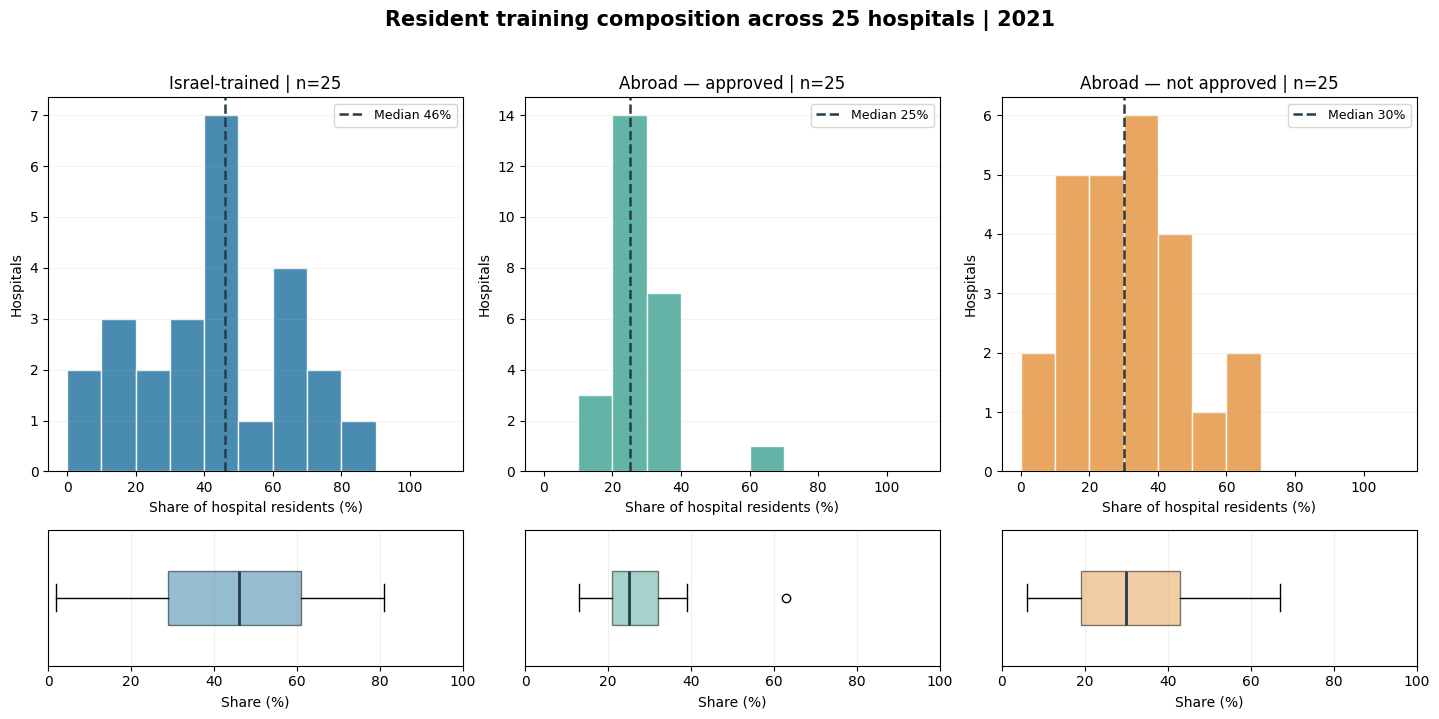

Unapproved-school share: min = 6 median = 30.0 max = 67


In [28]:
# 4.2 — Descriptive statistics and one-variable distributions (2021)
resident_describe_2021 = h21[cols21].describe(percentiles=[.25, .5, .75]).T
resident_describe_2021.index = [
    'Trained in Israel', 'Trained abroad / approved', 'Trained abroad / not approved'
]
display(resident_describe_2021.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.0), gridspec_kw={'height_ratios':[3.3,1.2]})
names = ['Israel-trained', 'Abroad — approved', 'Abroad — not approved']
colors = ['#317CA7', '#4DA99B', '#E59A4A']
for j, (col, name, color) in enumerate(zip(cols21, names, colors)):
    s = h21[col].astype(float)
    axes[0,j].hist(s, bins=np.arange(0, 111, 10), color=color, edgecolor='white', alpha=.88)
    axes[0,j].axvline(s.median(), color='#263C4A', linestyle='--', linewidth=1.8,
                      label=f'Median {s.median():.0f}%')
    axes[0,j].set(title=f'{name} | n={len(s)}', xlabel='Share of hospital residents (%)', ylabel='Hospitals')
    axes[0,j].legend(fontsize=9)
    axes[0,j].grid(axis='y', alpha=.15)
    axes[1,j].boxplot(s, vert=False, widths=.4, patch_artist=True,
                      boxprops={'facecolor':color, 'alpha':.5},
                      medianprops={'color':'#263C4A', 'linewidth':2})
    axes[1,j].set(xlabel='Share (%)', yticks=[], xlim=(0,100))
    axes[1,j].grid(axis='x', alpha=.18)
fig.suptitle('Resident training composition across 25 hospitals | 2021', weight='bold', y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig('charts/residents_2021_univariate_hist_box.png', dpi=190, bbox_inches='tight')
plt.show()

print('Unapproved-school share: min =', int(h21['trained_abroad_unapproved_pct'].min()),
      'median =', float(h21['trained_abroad_unapproved_pct'].median()),
      'max =', int(h21['trained_abroad_unapproved_pct'].max()))


### 4.3 — שונות בין בתי חולים: שלושת מסלולי ההכשרה

בתרשים הבא **כל עמודה מייצגת בית חולים אחד**, ולא מספר המתמחים. הבדלים בין בתי חולים נראים לעין; אין פירושם הבדלים באיכות הרפואה. כדי להימנע מהיפוך כיווני כתיבה בתמונה, משתמשים בתוויות קצרות באנגלית; שמות בתי החולים בעברית שמורים בטבלה שמעל וב־CSV.

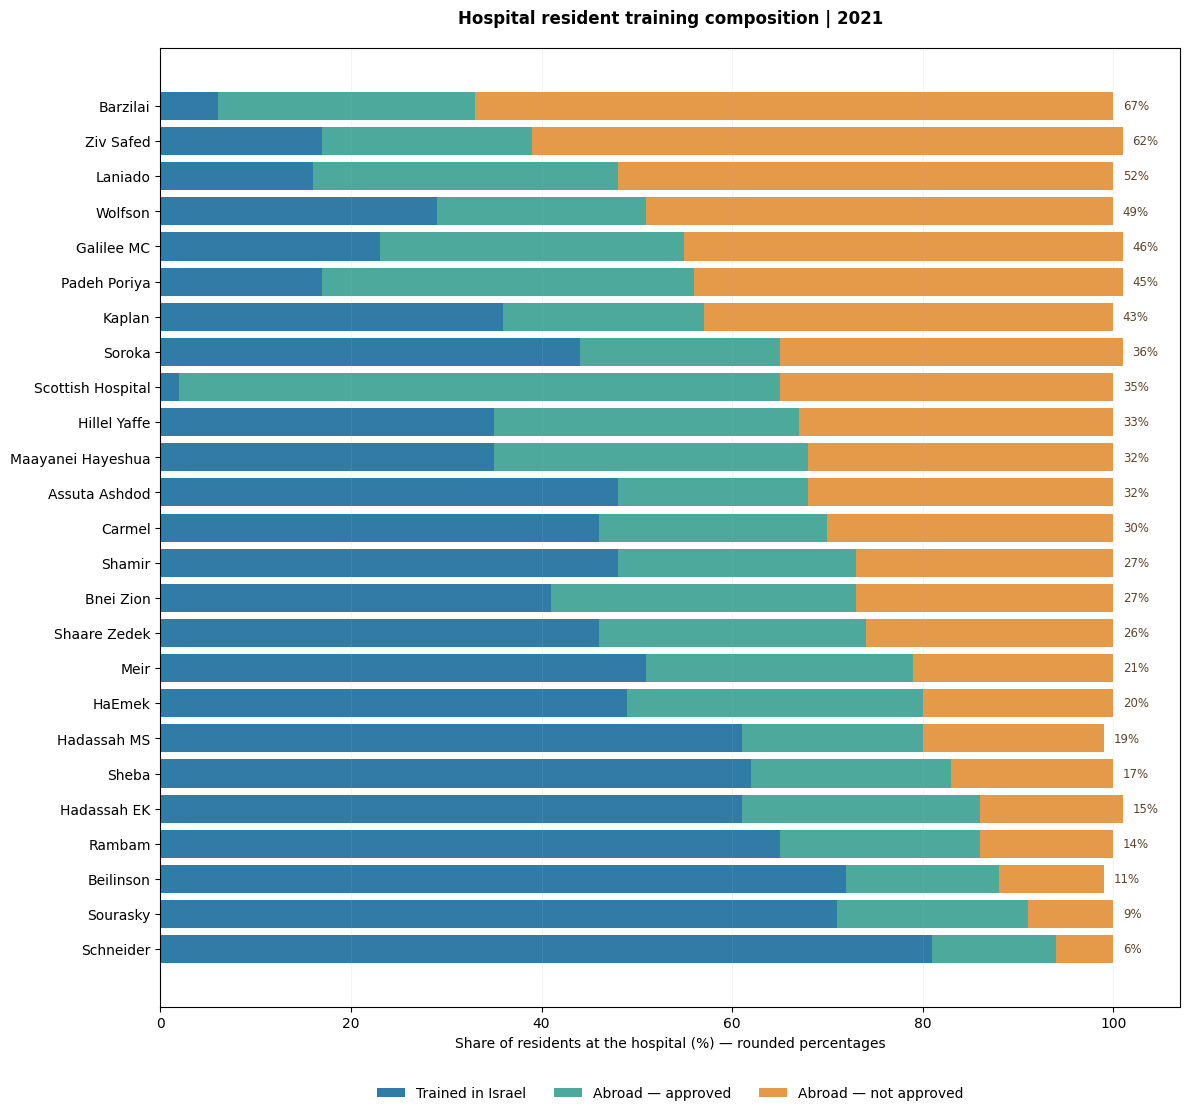

,hospital_name_he,hospital_en,trained_israel_pct,trained_abroad_approved_pct,trained_abroad_unapproved_pct
0,ברזילי,Barzilai,6,27,67
1,זיו צפת,Ziv Safed,17,22,62
2,לניאדו,Laniado,16,32,52
3,וולפסון,Wolfson,29,22,49
4,המרכז הרפואי לגליל,Galilee MC,23,32,46
5,פדה פוריה,Padeh Poriya,17,39,45
6,קפלן,Kaplan,36,21,43
7,סורוקה,Soroka,44,21,36
8,בית החולים הסקוטי,Scottish Hospital,2,63,35
9,הלל יפה,Hillel Yaffe,35,32,33


In [29]:
# 4.3 — Hospital-level composition: ranked stacked bars, 2021
# English short display labels are presentation aliases; the source keeps Hebrew names.
hospital_en = {
    'שניידר':'Schneider', 'איכילוב סוראסקי':'Sourasky',
    'בילינסון':'Beilinson', 'רמב"ם':'Rambam',
    'הדסה עין כרם':'Hadassah EK', 'שיבא':'Sheba',
    'הדסה הר הצופים':'Hadassah MS', 'המרכז הרפואי העמק':'HaEmek',
    'מאיר':'Meir', 'שערי צדק':'Shaare Zedek',
    'בני ציון':'Bnei Zion', 'יצחק שמיר':'Shamir',
    'כרמל':'Carmel', 'אסותא אשדוד':'Assuta Ashdod',
    'מעיני הישועה':'Maayanei Hayeshua', 'הלל יפה':'Hillel Yaffe',
    'בית החולים הסקוטי':'Scottish Hospital', 'סורוקה':'Soroka',
    'קפלן':'Kaplan', 'פדה פוריה':'Padeh Poriya',
    'המרכז הרפואי לגליל':'Galilee MC', 'וולפסון':'Wolfson',
    'לניאדו':'Laniado', 'זיו צפת':'Ziv Safed', 'ברזילי':'Barzilai'
}
assert set(h21['hospital_name_he']) == set(hospital_en), 'Hospital alias map incomplete'
ranked21 = h21.sort_values('trained_abroad_unapproved_pct', ascending=True).copy()
ranked21['hospital_en'] = ranked21['hospital_name_he'].map(hospital_en)
ys = np.arange(len(ranked21))
fig, ax = plt.subplots(figsize=(12, 11.2))
ax.barh(ys, ranked21['trained_israel_pct'], color='#317CA7', label='Trained in Israel')
ax.barh(ys, ranked21['trained_abroad_approved_pct'], left=ranked21['trained_israel_pct'],
        color='#4DA99B', label='Abroad — approved')
ax.barh(ys, ranked21['trained_abroad_unapproved_pct'],
        left=ranked21['trained_israel_pct']+ranked21['trained_abroad_approved_pct'],
        color='#E59A4A', label='Abroad — not approved')
ax.set_yticks(ys, ranked21['hospital_en']); ax.set_xlim(0, 107)
ax.set_xlabel('Share of residents at the hospital (%) — rounded percentages')
ax.set_title('Hospital resident training composition | 2021', weight='bold', pad=18)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False, fontsize=10)
ax.grid(axis='x', alpha=.14)
for y,row in zip(ys, ranked21.itertuples()):
    ax.text(row.trained_israel_pct + row.trained_abroad_approved_pct +
            row.trained_abroad_unapproved_pct + 1.0, y,
            f'{row.trained_abroad_unapproved_pct}%', fontsize=8.5, va='center', color='#5D442B')
fig.tight_layout()
fig.savefig('charts/residents_2021_hospital_composition_stacked.png', dpi=190, bbox_inches='tight')
plt.show()

# Show the exact paired Hebrew name / English plot label / source shares for auditing.
display(ranked21[['hospital_name_he','hospital_en']+cols21].sort_values('trained_abroad_unapproved_pct',ascending=False).reset_index(drop=True))


### 4.4 — EDA ב־2020: חסרים, אפסים ופיזור בין התמחויות

המקור מציג **160 שילובים אפשריים של 10 בתי חולים ו־16 התמחויות**. הערך יכול להיות `0` אמיתי, `100` אמיתי או `NaN` (סימון חסר במקור). **אין להמיר `NaN` לאפס**. נבחן חציון בין בתי החולים המדווחים בכל התמחות, עם מספר בתי חולים ומספר תאים חסרים.

In [30]:
# 4.4 — 2020 hospital × specialty quality checks and summaries
specialty_summary = (
    s20.groupby('specialty_he', dropna=False)
       .agg(hospitals_reported=('unapproved_residents_pct', 'count'),
            possible_hospitals=('hospital_id', 'size'),
            missing=('unapproved_residents_pct', lambda x: x.isna().sum()),
            observed_zero=('unapproved_residents_pct', lambda x: x.eq(0).sum()),
            median_pct=('unapproved_residents_pct', 'median'),
            min_pct=('unapproved_residents_pct', 'min'),
            max_pct=('unapproved_residents_pct', 'max'))
       .sort_values('median_pct', ascending=False)
)
display(specialty_summary.round(1))
print('Valid cells:', int(s20['unapproved_residents_pct'].notna().sum()),
      'of', len(s20), '| Missing cells:', int(s20['unapproved_residents_pct'].isna().sum()))

hospital_missing_2020 = s20.groupby('hospital_name_he').agg(
    missing_cells=('unapproved_residents_pct', lambda x: x.isna().sum()),
    reported_cells=('unapproved_residents_pct', 'count')
).sort_values('missing_cells', ascending=False)
display(hospital_missing_2020)


,hospitals_reported,possible_hospitals,missing,observed_zero,median_pct,min_pct,max_pct
specialty_he,,,,,,,
גריאטריה,7,10,3,0,67.0,38.0,100.0
הרדמה,10,10,0,0,63.5,16.0,92.0
אונקולוגיה,10,10,0,2,45.0,0.0,100.0
רפואה דחופה,10,10,0,0,36.0,10.0,77.0
פסיכיאטריה,6,10,4,1,21.5,0.0,50.0
רדיולוגיה אבחנתית,10,10,0,1,20.5,0.0,70.0
רפואה פנימית,10,10,0,0,18.0,3.0,80.0
כירורגיה אורתופדית,10,10,0,3,16.5,0.0,38.0
נוירולוגיה,10,10,0,0,15.0,6.0,50.0


Valid cells: 148 of 160 | Missing cells: 12


,missing_cells,reported_cells
hospital_name_he,,
"ביה""ח בילינסון",6,10
מרכז רפואי יצחק שמיר,2,14
"ביה""ח הדסה עין כרם",1,15
מרכז רפואי מאיר,1,15
מרכז רפואי שערי צדק,1,15
"מרכז רפואי רמב""ם",1,15
מרכז רפואי קפלן,0,16
מרכז רפואי סורוקה,0,16
מרכז רפואי שיבא,0,16


### 4.5 — Heatmap דו־ממדי: בית חולים × התמחות

כל תא צבוע לפי שיעור בוגרי המוסדות הלא מאושרים **באותו בית חולים ובאותה התמחות** ביולי 2020. אפס מדווח הוא תא תקף; תא אפור פירושו נתון חסר. המפה בוחנת **שונות בתוך התמחות ובין התמחויות**, אבל בלי מכנים אי אפשר להשתמש בה לחישוב משקל ההתמחויות במלאי בית החולים.

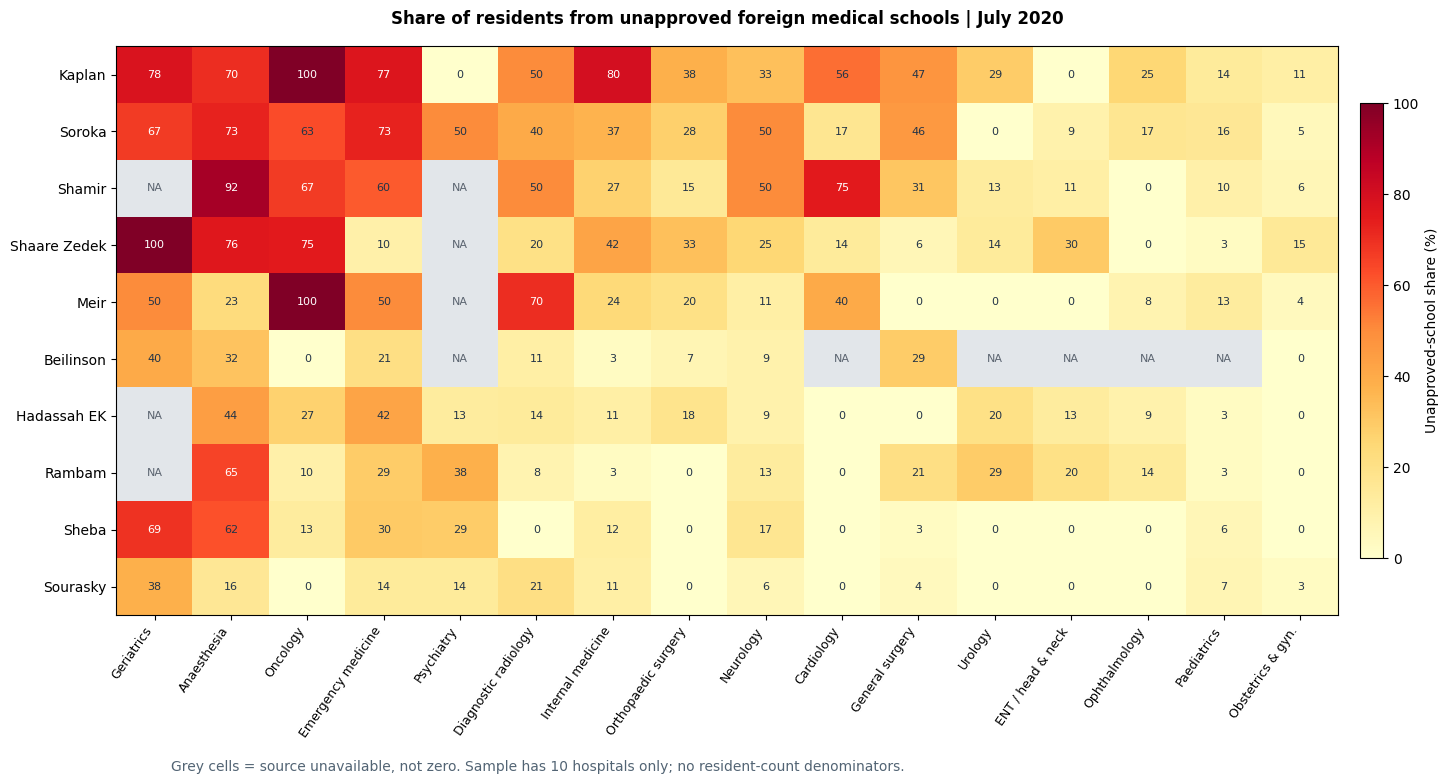

In [31]:
# 4.5 — 2020 heatmap: 10 hospitals × 16 specialties
specialty_en = {
    'רפואה פנימית':'Internal medicine',
    'כירורגיה כללית':'General surgery',
    'הרדמה':'Anaesthesia',
    'רפואה דחופה':'Emergency medicine',
    'גריאטריה':'Geriatrics',
    'פסיכיאטריה':'Psychiatry',
    'אונקולוגיה':'Oncology',
    'רדיולוגיה אבחנתית':'Diagnostic radiology',
    'כירורגיה אורתופדית':'Orthopaedic surgery',
    'נוירולוגיה':'Neurology',
    'קרדיולוגיה':'Cardiology',
    'כירורגיה אורולוגית':'Urology',
    'מחלות א.א.ג וכירורגיה של ראש וצוואר':'ENT / head & neck',
    'מחלות עיניים':'Ophthalmology',
    'רפואת ילדים':'Paediatrics',
    'יילוד וגינקולוגיה':'Obstetrics & gyn.'
}
assert set(s20['specialty_he'].unique()) == set(specialty_en), 'Review specialty map'
specialty_order = specialty_summary.index.tolist()   # descending specialty median
hospital_ids = ['kaplan','soroka','shamir','shaare_zedek','meir','beilinson',
                'hadassah_ein_kerem','rambam','sheba','sourasky']
hosp_english = {'kaplan':'Kaplan','soroka':'Soroka','shamir':'Shamir','shaare_zedek':'Shaare Zedek',
                'meir':'Meir','beilinson':'Beilinson','hadassah_ein_kerem':'Hadassah EK',
                'rambam':'Rambam','sheba':'Sheba','sourasky':'Sourasky'}
heat_pivot = s20.pivot(index='hospital_id',columns='specialty_he', values='unapproved_residents_pct')
heat_pivot = heat_pivot.reindex(index=hospital_ids, columns=specialty_order)
assert heat_pivot.shape == (10,16)
heat_colors = plt.get_cmap('YlOrRd').copy()
heat_colors.set_bad('#E2E6EA')
fig,ax=plt.subplots(figsize=(16,7.8))
mat = np.ma.masked_invalid(heat_pivot.to_numpy(dtype=float))
im=ax.imshow(mat, cmap=heat_colors, vmin=0, vmax=100, aspect='auto', interpolation='nearest')
ax.set_xticks(np.arange(len(specialty_order)), [specialty_en[x] for x in specialty_order], rotation=55, ha='right', fontsize=9)
ax.set_yticks(np.arange(len(hospital_ids)), [hosp_english[x] for x in hospital_ids], fontsize=10)
ax.set_title('Share of residents from unapproved foreign medical schools | July 2020', weight='bold', pad=16)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        if np.ma.is_masked(mat[i,j]):
            label='NA'; color='#5B6470'
        else:
            label=f'{mat[i,j]:.0f}'; color='#FFFFFF' if mat[i,j]>=65 else '#233447'
        ax.text(j,i,label,ha='center',va='center',fontsize=8,color=color)
cb=fig.colorbar(im,ax=ax,shrink=.8,pad=.015)
cb.set_label('Unapproved-school share (%)')
fig.text(.11,.005,'Grey cells = source unavailable, not zero. Sample has 10 hospitals only; no resident-count denominators.',
         fontsize=10,color='#526474')
fig.tight_layout(rect=(0,.025,1,1))
fig.savefig('charts/residents_2020_hospital_specialty_heatmap.png', dpi=190, bbox_inches='tight')
plt.show()


### 4.6 — אילו התמחויות בולטות יותר? (2020)

השוואת **חציון שיעור בוגרי מוסדות לא מאושרים** בין בתי החולים המדווחים בכל התמחות. החציון אינו משוקלל במספר המתמחים, ולכן אינו שיעור ארצי. נציג את מספר התצפיות התקפות כדי לא להשוות 6 בתי חולים ל־10 כאילו היו אותם מדגמים.

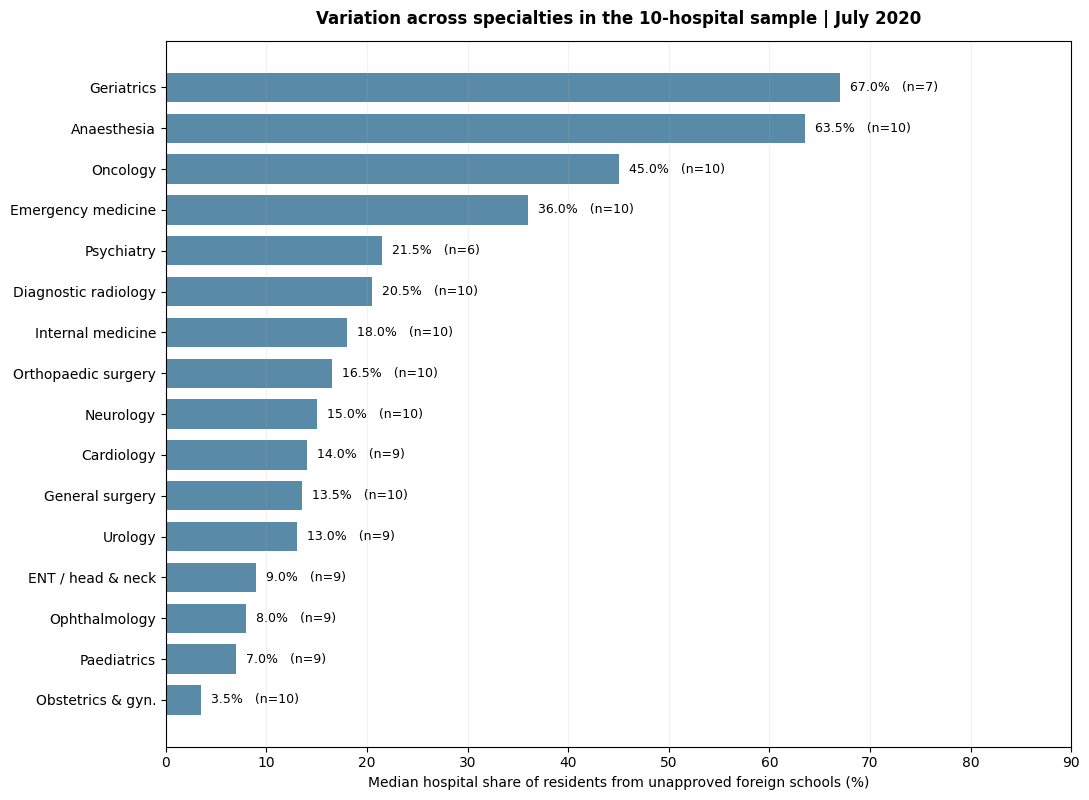

הרדמה : median 63.5 %; valid hospitals 10 ; missing 0
יילוד וגינקולוגיה : median 3.5 %; valid hospitals 10 ; missing 0
גריאטריה : median 67.0 %; valid hospitals 7 ; missing 3


In [32]:
# 4.6 — Specialty-level medians, observed counts and missingness
ordered_sp = specialty_summary.sort_values('median_pct', ascending=True)
ys = np.arange(len(ordered_sp))
fig, ax=plt.subplots(figsize=(11,8.1))
ax.barh(ys, ordered_sp['median_pct'], color='#477F9F', alpha=.9, height=.72)
ax.set_yticks(ys, [specialty_en[s] for s in ordered_sp.index], fontsize=10)
ax.set_xlim(0,90)
ax.set_xlabel('Median hospital share of residents from unapproved foreign schools (%)')
ax.set_title('Variation across specialties in the 10-hospital sample | July 2020', weight='bold', pad=12)
ax.grid(axis='x', alpha=.17)
for yy, (_, r) in zip(ys, ordered_sp.iterrows()):
    ax.text(float(r['median_pct']) + 1, yy, f'{r["median_pct"]:.1f}%   (n={int(r["hospitals_reported"])})',
            va='center', fontsize=9)
fig.tight_layout()
fig.savefig('charts/residents_2020_specialty_medians.png', dpi=190, bbox_inches='tight')
plt.show()

# Explicit contrast: 2020 sample only, no national rates.
for spec in ['הרדמה', 'יילוד וגינקולוגיה','גריאטריה']:
    r=specialty_summary.loc[spec]
    print(spec, ': median', round(r['median_pct'],1),'%; valid hospitals',int(r['hospitals_reported']),
          '; missing',int(r['missing']))


### 4.7 — ממצאי ביניים: אילו גרפים מועמדים למצגת?

1. **2021 — שונות חריפה בין בתי חולים:** שיעור בוגרי מוסדות לא מאושרים נע בין **6% (שניידר)** לבין **67% (ברזילי)**; חציון 25 בתי החולים הוא **30%**. אלה שיעורי בתי חולים, *לא שיעור לאומי של מתמחים*.
2. **2020 — הבדלים בין התמחויות:** במדגם 10 בתי החולים, חציון שיעור בוגרי המוסדות הלא מאושרים בהרדמה הוא **63.5%** (`n=10`), לעומת **3.5%** ביילוד וגינקולוגיה (`n=10`). לגריאטריה חציון **67%** אך רק `n=7`. בשל חילוץ הנתונים ההיסטוריים מטבלה דו־כיוונית, יש **לאמת את שיוך כותרות ההתמחויות מול התרשים המקורי לפני שמשתמשים בזה במצגת**.
3. **איכות הנתונים:** ב־2021 אין ערכי אחוז חסרים בשלוש קבוצות ההכשרה, אך בשבעה מוסדות סכום הקבוצות 99% או 101% (עיגול/חילוץ שצריך אימות). בשנת 2020 יש **12/160 תאים חסרים**, ולעומתם **29 ערכי אפס תקפים**.

**בחירת שקפים מוצעת:** גרף ההרכב המוערם של 25 בתי החולים מתאים במיוחד להצגת המעבר מהשוואה בין־לאומית לבדיקת בתי חולים; Heatmap או חציוני התמחות יכולים לשמש שקף משלים רק אחרי אימות חזותי של חילוץ 2020. את ההיסטוגרמות וטבלאות ה־NULL נשמור בעיקר במחברת. בשלב הבא נבדוק בנפרד את איכות הנתונים הקליניים לפני חיבור סטטיסטי כלשהו.

**הסתייגות מחקרית:** שיעור מתמחים לפי מסלול הכשרה הוא מאפיין מוסדי; הוא אינו מדד לאיכות הרפואה, ורגרסיה או מתאם ברמת מוסד לא יצדיקו מסקנה סיבתית על רופא מסוים.


## 5. משרד הבריאות — EDA של מדדי איכות הטיפול (2020–2024)

**שאלת הביניים:** כיצד משתנה שיעור העמידה במדדי איכות הטיפול בין בתי חולים ושנים, ואילו מגבלות נתונים חייבים להבין לפני השוואה להרכב המתמחים?

שלושת המדדים הם **CHADS** (הערכת סיכון לשבץ), **אנטיביוטיקה סביב ניתוח קולון**, ו**ניתוח שבר בצוואר הירך בתוך 48 שעות**. כל שורה היא קבוצת מקרים מפולחת (בית חולים, חודש, מין, קבוצת גיל ועוד); **זו לא תצפית ברמת בית חולים**. `number_of_cases` הוא מכנה, ו־`number_of_cases_approved` מונה המקרים שעמדו במדד.

**הנחת עבודה שדורשת אימות:** כאשר המונה ריק אבל המכנה חיובי, ייתכן שהמקור משתמש בתא ריק ל־0 הצלחות. בדיקת שעת הניתוח במאגר השבר תומכת בפירוש הזה (זמן מעל 48 שעות → מונה חסר), אבל **אין במסמך הסכמה הממשלתי הגדרה מפורשת ל־NULL כמונה 0**. לכן נדווח שיעור *מותנה בהנחת אפס*, לצד תרחיש רגישות שבו שורות המונה החסר מושמטות. השוואה רשמית של שיעורי הצלחה מחייבת אישור ממקור הנתונים.

מקור: [מאגר מדדי איכות — אשפוז כללי, משרד הבריאות](https://data.gov.il/he/datasets/ministry-health/health-quality-measurement-general-hospitalization).

### 5.1 — יחידת תצפית, כיסוי, NULL ובדיקות תקינות

נשמר את כל השורות הגולמיות. נבדוק ספירות ושנים, חוסרים במונה/מכנה, ערכי מונה גבוהים מהמכנה, ושכפולים מלאים. היעדר ערך ב־`actual_time` פירושו לעיתים **"לא רלוונטי"**, ולכן אין להתייחס אליו כתקלה רפואית. נבדוק גם האם שדות קבוצות הגיל הם פילוחים היררכיים ולא שני סיכומים נפרדים.

In [33]:
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

clinical = moh.copy()
for c in ['number_of_cases', 'number_of_cases_approved', 'target']:
    clinical[c] = pd.to_numeric(clinical[c], errors='coerce')
clinical['actual_time_numeric'] = pd.to_numeric(clinical['actual_time'], errors='coerce')
clinical['approved_missing'] = clinical['number_of_cases_approved'].isna()
clinical['approved_if_blank_zero'] = clinical['number_of_cases_approved'].fillna(0)
clinical['denominator_missing'] = clinical['number_of_cases'].isna()
clinical['bad_numerator'] = clinical['approved_if_blank_zero'] > clinical['number_of_cases']

qa = (clinical.groupby('metric_short', as_index=False)
      .agg(rows=('metric_short', 'size'),
           first_year=('measurement_year','min'),last_year=('measurement_year','max'),
           years=('measurement_year','nunique'),
           source_hospitals=('provider','nunique'),
           missing_denominator=('denominator_missing','sum'),
           missing_numerator=('approved_missing','sum'),
           invalid_greater_than_denominator=('bad_numerator','sum')))
qa['missing_numerator_pct'] = (100*qa.missing_numerator/qa.rows).round(2)
print('Quality-source diagnostics:')
display(qa)
print('Exact duplicate raw rows across three files:', int(clinical.duplicated().sum()))
print('Examples of raw dimensions:', ['provider','measurement_year','month','gender','age_range',
                                     'detailed_age_range_groups','shift','day_range','method'])
assert clinical['denominator_missing'].sum() == 0
assert clinical['bad_numerator'].sum() == 0
assert clinical['number_of_cases'].gt(0).all()

# Coverage: only actual years in each source, not the year a measure was first defined.
display((clinical.groupby(['metric_short','measurement_year'], as_index=False)
         .agg(rows=('provider','size'), hospitals=('provider','nunique'),
              missing_numerators=('approved_missing','sum'))))


Quality-source diagnostics:


,metric_short,rows,first_year,last_year,years,source_hospitals,missing_denominator,missing_numerator,invalid_greater_than_denominator,missing_numerator_pct
0,CHADS,19403,2020,2024,5,26,0,872,0,4.49
1,Colon antibiotics,12891,2020,2024,5,34,0,600,0,4.65
2,Hip fracture 48h,12690,2020,2021,2,26,0,1470,0,11.58


Exact duplicate raw rows across three files: 0
Examples of raw dimensions: ['provider', 'measurement_year', 'month', 'gender', 'age_range', 'detailed_age_range_groups', 'shift', 'day_range', 'method']


,metric_short,measurement_year,rows,hospitals,missing_numerators
0,CHADS,2020,4062,24,185
1,CHADS,2021,4018,24,177
2,CHADS,2022,3851,24,169
3,CHADS,2023,3600,23,166
4,CHADS,2024,3872,24,175
5,Colon antibiotics,2020,2598,32,139
6,Colon antibiotics,2021,2549,33,139
7,Colon antibiotics,2022,2438,32,86
8,Colon antibiotics,2023,2601,33,109
9,Colon antibiotics,2024,2705,34,127


### 5.1.1 — כיסוי תצפיות לאורך השנים (לא תוצאה קלינית)

נשמור גם את גרף **מספר שורות המקור** שבחרנו כגרף מתודולוגי למצגת. מספר שורות אינו מספר מטופלים, אינו שיעור הצלחה, ואינו מדד איכות בפני עצמו. הקווים משקפים היקף נתונים בלבד; מדד ניתוח השבר מסתיים בקובץ שלנו ב־2021.

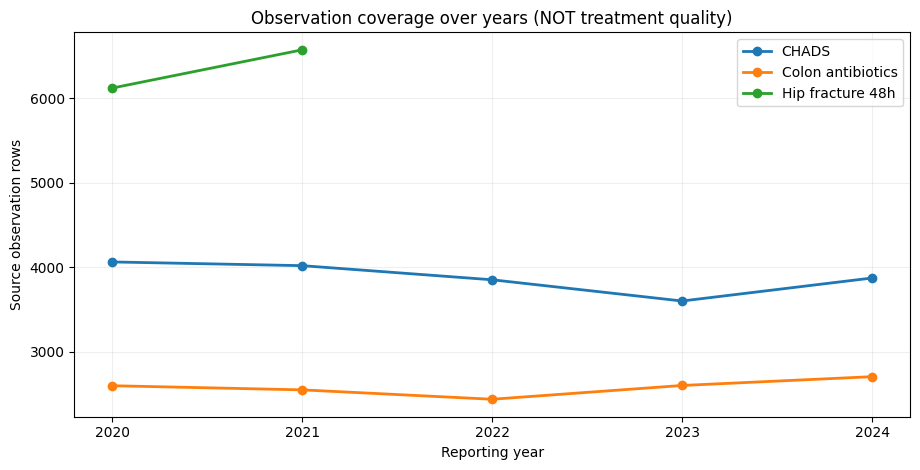

Year-by-year target values (do not confuse target with actual performance):


,metric_short,measurement_year,reported_target_values
0,CHADS,2020,[0.8]
1,CHADS,2021,[0.8]
2,CHADS,2022,[0.9]
3,CHADS,2023,[0.9]
4,CHADS,2024,[0.9]
5,Colon antibiotics,2020,[0.9]
6,Colon antibiotics,2021,[0.9]
7,Colon antibiotics,2022,[0.95]
8,Colon antibiotics,2023,[0.95]
9,Colon antibiotics,2024,[0.0]


In [34]:
# Source record coverage over time — NOT a quality/compliance chart.
coverage = (clinical.groupby(['metric_short','measurement_year'],as_index=False)
             .agg(observation_rows=('provider','size'),
                  distinct_hospitals=('provider','nunique')))
fig,ax=plt.subplots(figsize=(9.3,4.8))
for m,g in coverage.groupby('metric_short'):
    ax.plot(g.measurement_year,g.observation_rows,marker='o',linewidth=2,label=m)
ax.set(title='Observation coverage over years (NOT treatment quality)',
       xlabel='Reporting year',ylabel='Source observation rows')
ax.set_xticks([2020,2021,2022,2023,2024]);ax.grid(alpha=.2)
ax.legend();plt.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/quality_observation_coverage_over_years.png',dpi=180,bbox_inches='tight')
plt.show()

# Target/definition audit: avoid comparing 'target met' across years if thresholds change.
target_check=(clinical.groupby(['metric_short','measurement_year'])['target']
              .agg(lambda s:sorted(set(round(float(v),4) for v in s.dropna())))
              .rename('reported_target_values').reset_index())
print('Year-by-year target values (do not confuse target with actual performance):')
display(target_check)


### 5.2 — בדיקת מהות המונים החסרים וניתוח רגישות

בדיקת המדד של ניתוח שבר: נצליב את משך הזמן המדווח עם היעדר המונה. אם שורות מעל 48 שעות מופיעות בלי מקרים מאושרים, זו עדות חזקה לכך שבייצוא זה תא ריק עשוי לייצג 0. נחשב **שתי גרסאות** לתוצאה השנתית:

- *Blank → 0*: סכום המקרים המאושרים, כאשר מונה חסר מטופל כ־0, חלקי כל המקרים.
- *Complete rows only*: סכום המקרים המאושרים חלקי המקרים בשורות שבהן המונה לא חסר — תרחיש רגישות שמוטה כלפי מעלה אם החוסרים הם אפסים.

לא נקבע ש־"Complete rows" טוב יותר; הצגת הפער ביניהם היא **בדיקת איכות נתונים**.

Hip-fracture reported time vs blank approved numerator:


,time_band,n_rows,missing_numerator
0,<48h,11214,0
1,=48h,121,115
2,>48h,1355,1355


Caution: time exactly 48h is mixed, possibly due to rounding; do not recode by time alone.
Sensitivity: annual percentage meeting measure under different missing-numerator assumptions


,metric_short,measurement_year,all_cases,reported_approved,rows,blank_numerator_rows,observed_cases,pct_if_blank_zero,pct_complete_rows,difference_pp
0,CHADS,2020,10828.0,9855.0,4062,185,10586.0,91.01,93.09,2.08
1,CHADS,2021,11899.0,10732.0,4018,177,11672.0,90.19,91.95,1.75
2,CHADS,2022,10589.0,9613.0,3851,169,10370.0,90.78,92.70,1.92
3,CHADS,2023,9071.0,8357.0,3600,166,8859.0,92.13,94.33,2.20
4,CHADS,2024,9751.0,9134.0,3872,175,9557.0,93.67,95.57,1.90
5,Colon antibiotics,2020,3110.0,2942.0,2598,139,2965.0,94.60,99.22,4.63
6,Colon antibiotics,2021,3095.0,2926.0,2549,139,2948.0,94.54,99.25,4.71
7,Colon antibiotics,2022,2936.0,2835.0,2438,86,2843.0,96.56,99.72,3.16
8,Colon antibiotics,2023,3151.0,3036.0,2601,109,3042.0,96.35,99.80,3.45
9,Colon antibiotics,2024,3289.0,3149.0,2705,127,3159.0,95.74,99.68,3.94


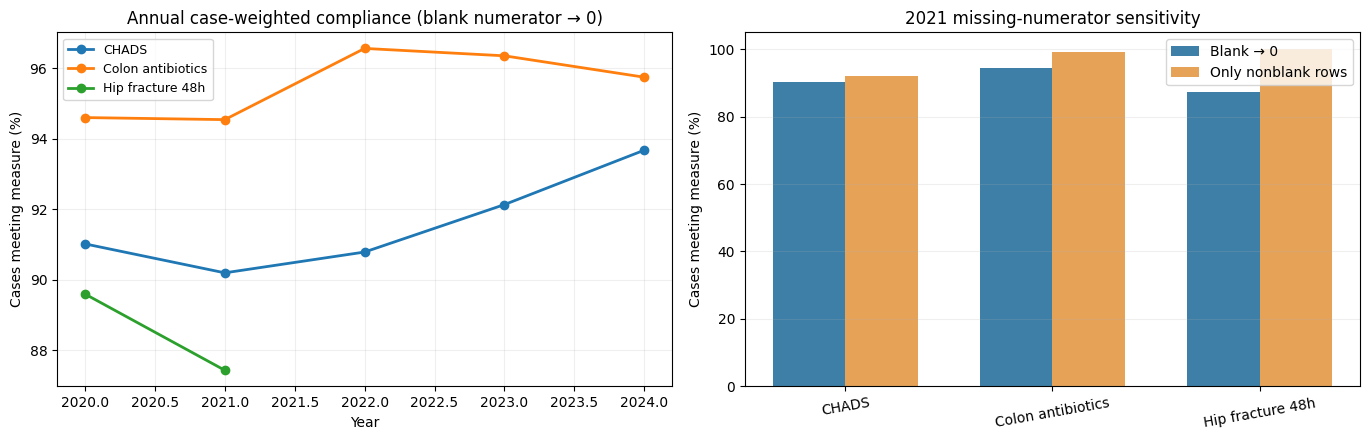

In [35]:
hip = clinical.loc[clinical['metric_short'].eq('Hip fracture 48h')].copy()
hip_duration_audit = pd.DataFrame([
    {'time_band':'<48h', 'n_rows':int(hip['actual_time_numeric'].lt(48).sum()),
     'missing_numerator':int((hip['actual_time_numeric'].lt(48)&hip['approved_missing']).sum())},
    {'time_band':'=48h', 'n_rows':int(hip['actual_time_numeric'].eq(48).sum()),
     'missing_numerator':int((hip['actual_time_numeric'].eq(48)&hip['approved_missing']).sum())},
    {'time_band':'>48h', 'n_rows':int(hip['actual_time_numeric'].gt(48).sum()),
     'missing_numerator':int((hip['actual_time_numeric'].gt(48)&hip['approved_missing']).sum())},
])
print('Hip-fracture reported time vs blank approved numerator:')
display(hip_duration_audit)
print('Caution: time exactly 48h is mixed, possibly due to rounding; do not recode by time alone.')

# Annual overall rates are CASE-WEIGHTED, not a mean over rows or hospitals.
annual_quality = (clinical.groupby(['metric_short','measurement_year'],as_index=False)
                  .agg(all_cases=('number_of_cases','sum'),
                       reported_approved=('approved_if_blank_zero','sum'),
                       rows=('metric_short','size'),
                       blank_numerator_rows=('approved_missing','sum')))
observed_cases = (clinical.loc[~clinical['approved_missing']]
                  .groupby(['metric_short','measurement_year'])['number_of_cases']
                  .sum().rename('observed_cases').reset_index())
annual_quality = annual_quality.merge(observed_cases,on=['metric_short','measurement_year'],how='left',validate='one_to_one')
annual_quality['pct_if_blank_zero'] = 100*annual_quality.reported_approved/annual_quality.all_cases
annual_quality['pct_complete_rows'] = 100*annual_quality.reported_approved/annual_quality.observed_cases
annual_quality['difference_pp'] = annual_quality.pct_complete_rows-annual_quality.pct_if_blank_zero
print('Sensitivity: annual percentage meeting measure under different missing-numerator assumptions')
display(annual_quality.round(2))

fig,axs=plt.subplots(1,2,figsize=(13.8,4.5))
for name,g in annual_quality.groupby('metric_short'):
    axs[0].plot(g.measurement_year,g.pct_if_blank_zero,marker='o',lw=2,label=name)
axs[0].set(title='Annual case-weighted compliance (blank numerator → 0)',xlabel='Year',ylabel='Cases meeting measure (%)')
axs[0].legend(loc='best',fontsize=9); axs[0].grid(alpha=.2)
a2021=annual_quality.loc[annual_quality.measurement_year.eq(2021)].sort_values('metric_short')
xx=np.arange(len(a2021)); w=.35
axs[1].bar(xx-w/2,a2021.pct_if_blank_zero,width=w,label='Blank → 0',color='#3D7FA7')
axs[1].bar(xx+w/2,a2021.pct_complete_rows,width=w,label='Only nonblank rows',color='#E6A358')
axs[1].set_xticks(xx,a2021.metric_short,rotation=10)
axs[1].set(title='2021 missing-numerator sensitivity',ylabel='Cases meeting measure (%)',ylim=(0,105))
axs[1].legend(); axs[1].grid(axis='y',alpha=.2)
plt.tight_layout()
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/quality_annual_rates_and_missing_numerator_sensitivity.png',dpi=180,bbox_inches='tight')
plt.show()


### 5.2.1 — אימות מונה ריק לפי זמן הניתוח: גרף לשקף 17

**מה בודקים?** את הקשר בין מונה ריק (`number_of_cases_approved`) לבין חריגה מחלון הזמן של 48 שעות. זו הצלבה עם שדה זמן נפרד, ולא הגדרה מעגלית של כל ריק כאי־עמידה.

הגרף משווה בין **כל הרשומות בעלות מונה ריק** לבין **הרשומות מתוכן שזמן הניתוח בהן גדול מ־48 שעות**. יחידת הספירה היא רשומת מקור מפולחת, ולא מספר מטופלים. מספרי המקרים המשוקללים נשמרים בנפרד בקובץ הייצוא.

התא עצמאי וקורא את קובץ המקור מחדש. להרצה יש לבחור את `analysis/` כתיקיית העבודה ולהתקין את `requirements.txt`. הוא שומר PNG, SVG וטבלת ספירות; הפלט להלן נוצר מהרצת תא זה בלבד, ולא מהרצה מחודשת של כל המחברת.


Hip fracture | 2020–2021 | source RECORDS, not patient counts
Blank numerators: 1,470
Among blanks, recorded time >48h: 1,355 (92.2%)
Among blanks, recorded time =48h: 115; time <48h: 0
All >48h records: 1,355; blank numerator: 1,355
All <48h records: 11,214; every numerator equals its denominator.
Exactly 48h also has 6 records with a reported positive numerator.


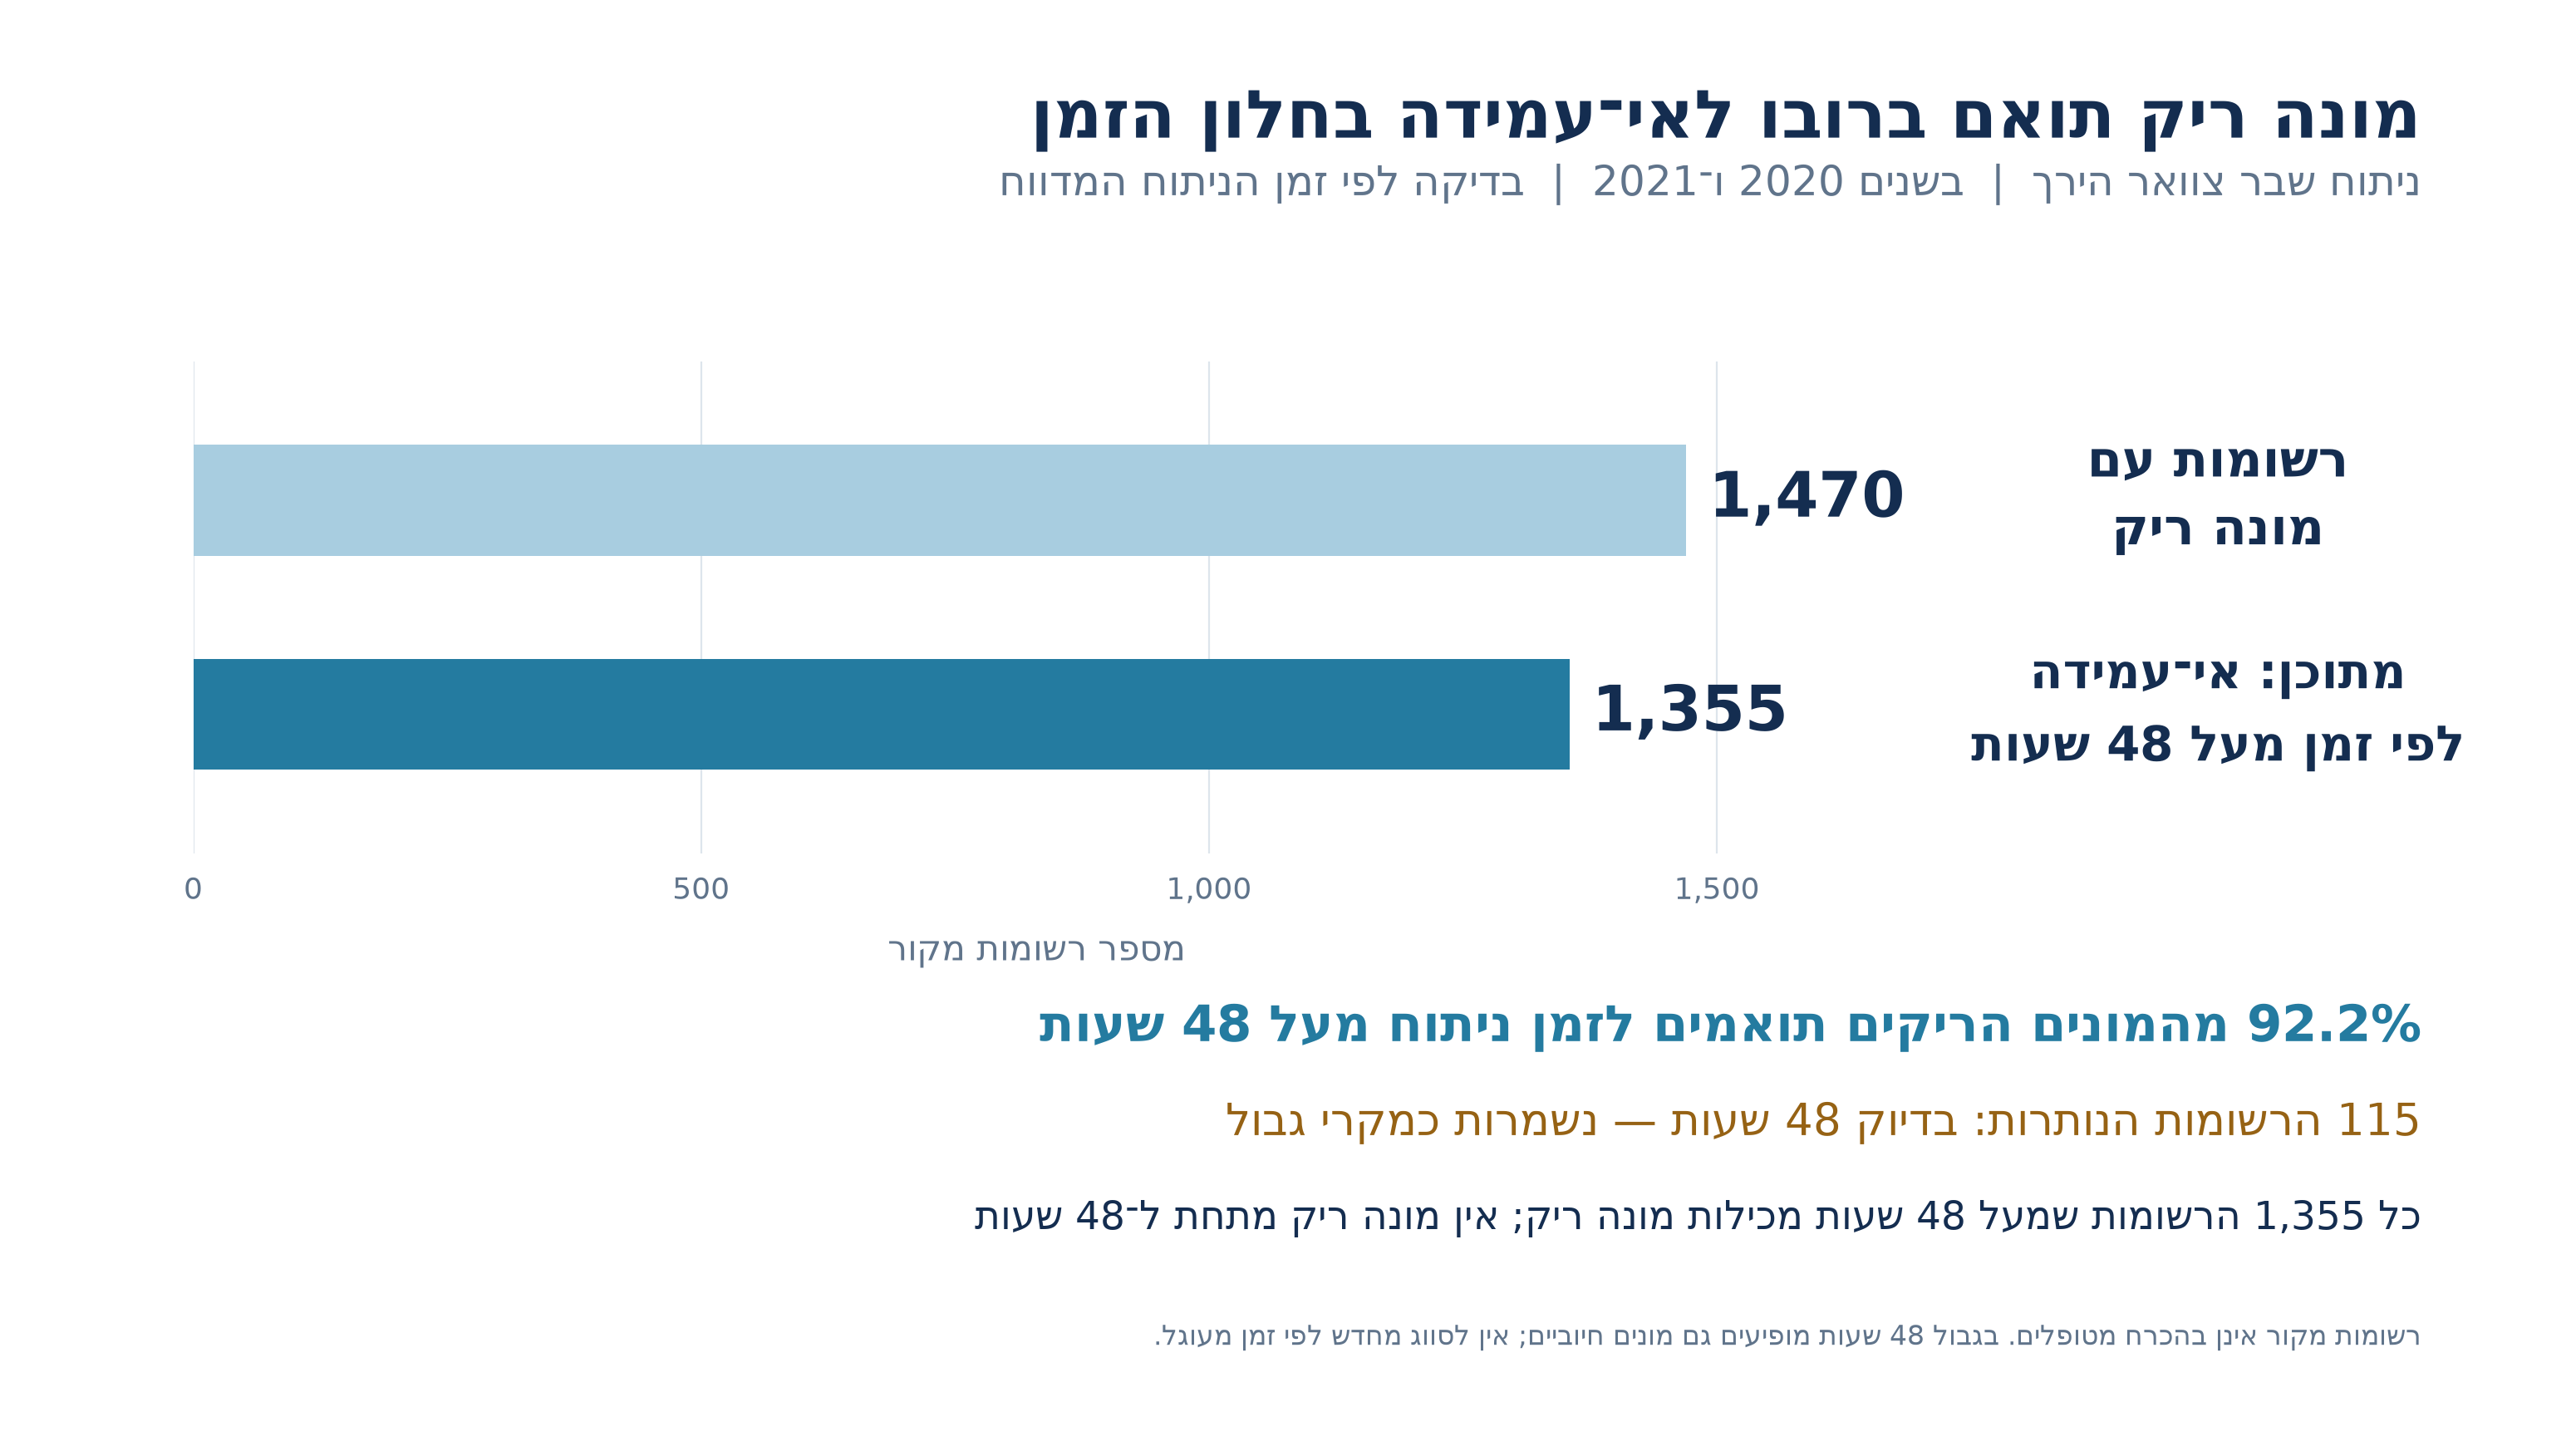

In [ ]:
# 5.2.1 — Audit blank approved-case counts against independently recorded time.
# Standalone cell: run from analysis/ (the notebook's working directory).
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib
from bidi.algorithm import get_display

def he(text):
    # Matplotlib 3.11+ shapes bidirectional text itself; older versions need bidi.
    version = tuple(int(part) for part in matplotlib.__version__.split('.')[:2])
    return text if version >= (3, 11) else get_display(text)

with (Path('data') / 'moh_hip_fracture.csv').open(encoding='cp1255', newline='') as source:
    hip_audit_rows = list(csv.DictReader(source))

# Preserve real blanks. Non-numeric nonblank values must not silently become zero.
def optional_number(value):
    value = value.strip()
    return None if not value else float(value)

hip_audit = [
    {'year': int(float(row['measurement_year'])),
     'time': optional_number(row['actual_time']),
     'cases': float(row['number_of_cases']),
     'approved': optional_number(row['number_of_cases_approved'])}
    for row in hip_audit_rows
]
blank_rows = [row for row in hip_audit if row['approved'] is None]
late_rows = [row for row in hip_audit if row['time'] is not None and row['time'] > 48]
blank_late = [row for row in blank_rows if row['time'] is not None and row['time'] > 48]
blank_boundary = [row for row in blank_rows if row['time'] == 48]
blank_early = [row for row in blank_rows if row['time'] is not None and row['time'] < 48]
early_rows = [row for row in hip_audit if row['time'] is not None and row['time'] < 48]
boundary_approved = [row for row in hip_audit if row['time'] == 48 and row['approved'] is not None]
assert all(row['time'] is not None for row in hip_audit)
assert len(blank_late) + len(blank_boundary) + len(blank_early) == len(blank_rows)
assert len(blank_late) == len(late_rows), 'Some late rows have a reported numerator; investigate.'
assert not blank_early, 'Blank numerators below 48h require review.'
assert all(row['approved'] == row['cases'] for row in early_rows)

print('Hip fracture | 2020–2021 | source RECORDS, not patient counts')
print(f'Blank numerators: {len(blank_rows):,}')
print(f'Among blanks, recorded time >48h: {len(blank_late):,} ({len(blank_late)/len(blank_rows):.1%})')
print(f'Among blanks, recorded time =48h: {len(blank_boundary):,}; time <48h: {len(blank_early):,}')
print(f'All >48h records: {len(late_rows):,}; blank numerator: {len(blank_late):,}')
print(f'All <48h records: {len(early_rows):,}; every numerator equals its denominator.')
print(f'Exactly 48h also has {len(boundary_approved)} records with a reported positive numerator.')

# Export the actual counts behind the figure, including weighted case counts.
chart_export_rows = []
for label, subset in [('all_blank_numerators', blank_rows),
                      ('blank_and_time_gt48', blank_late),
                      ('blank_and_time_eq48', blank_boundary),
                      ('blank_and_time_lt48', blank_early),
                      ('all_time_gt48', late_rows),
                      ('all_time_lt48', early_rows),
                      ('time_eq48_with_reported_numerator', boundary_approved)]:
    chart_export_rows.append({'category': label, 'source_records': len(subset),
                              'cases_in_records': sum(row['cases'] for row in subset)})
Path('exports').mkdir(exist_ok=True)
with Path('exports/MOH_Hip_Blank_Numerator_Time_Audit.csv').open('w', encoding='utf-8-sig', newline='') as target:
    writer = csv.DictWriter(target, fieldnames=['category', 'source_records', 'cases_in_records'])
    writer.writeheader()
    writer.writerows(chart_export_rows)

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 17,
                     'axes.unicode_minus': False, 'svg.fonttype': 'path'}):
    fig, ax = plt.subplots(figsize=(15.5, 8.7), facecolor='white')
    fig.subplots_adjust(left=.075, right=.73, top=.75, bottom=.41)
    navy, blue, amber = '#142D50', '#247BA0', '#E5A33B'
    n_blank, n_late, n_boundary = len(blank_rows), len(blank_late), len(blank_boundary)
    ax.barh([1.0, 0.0], [n_blank, n_late], color=['#A8CDE0', blue], height=.52, zorder=3)
    for y, value in [(1.0, n_blank), (0.0, n_late)]:
        ax.text(value+22, y, f'{value:,}', va='center', ha='left', fontsize=27, weight='bold', color=navy)
    ax.text(1.20, 1.0, he('רשומות עם\nמונה ריק'), transform=ax.get_yaxis_transform(),
            va='center', ha='center', color=navy, fontsize=22, weight='bold', linespacing=1.4)
    ax.text(1.20, 0.0, he('מתוכן: אי־עמידה\nלפי זמן מעל 48 שעות'), transform=ax.get_yaxis_transform(),
            va='center', ha='center', color=navy, fontsize=21, weight='bold', linespacing=1.4)
    ax.set_xlim(0, max(n_blank*1.13,1))
    ax.set_ylim(-.65,1.65)
    ax.set_yticks([])
    ax.set_xticks([0,500,1000,1500])
    ax.set_xticklabels(['0','500','1,000','1,500'], color='#60748B', fontsize=13)
    ax.grid(axis='x', color='#DDE5EC', linewidth=.8, zorder=0)
    for spine in ax.spines.values(): spine.set_visible(False)
    ax.tick_params(axis='both',length=0,pad=10)
    ax.set_xlabel(he('מספר רשומות מקור'), fontsize=15, labelpad=12, color='#60748B')
    fig.text(.94,.94,he('מונה ריק תואם ברובו לאי־עמידה בחלון הזמן'),
             ha='right', va='top', fontsize=29, weight='bold', color=navy)
    fig.text(.94,.865,he('ניתוח שבר צוואר הירך  |  בשנים 2020 ו־2021  |  בדיקה לפי זמן הניתוח המדווח'),
             ha='right', fontsize=18, color='#60748B')
    fig.text(.94,.28,he(f'{n_late/n_blank:.1%} מהמונים הריקים תואמים לזמן ניתוח מעל 48 שעות'),
             ha='right', fontsize=22, weight='bold', color=blue)
    fig.text(.94,.215,he(f'{n_boundary:,} הרשומות הנותרות: בדיוק 48 שעות — נשמרות כמקרי גבול'),
             ha='right', fontsize=19, color='#966214')
    fig.text(.94,.15,he(f'כל {len(late_rows):,} הרשומות שמעל 48 שעות מכילות מונה ריק; אין מונה ריק מתחת ל־48 שעות'),
             ha='right', fontsize=17, color=navy)
    fig.text(.94,.07,he('רשומות מקור אינן בהכרח מטופלים. בגבול 48 שעות מופיעים גם מונים חיוביים; אין לסווג מחדש לפי זמן מעוגל.'),
             ha='right', fontsize=12, color='#60748B')
    Path('charts').mkdir(exist_ok=True)
    fig.savefig('charts/quality_hip_missing_numerator_vs_time.png', dpi=200, facecolor='white')
    fig.savefig('charts/quality_hip_missing_numerator_vs_time.svg', facecolor='white')
    plt.show()


**תוצאת הבדיקה והחלטת החישוב:** מתוך 1,470 רשומות בעלות מונה ריק, 1,355 (92.2%) מתארות זמן ניתוח מעל 48 שעות; 115 הנותרות נמצאות בדיוק בגבול 48 שעות. כל 1,355 הרשומות שמעל 48 שעות מכילות מונה ריק, ואילו בכל 11,214 הרשומות שמתחת ל־48 שעות המונה שווה למכנה. בגבול 48 שעות קיימות גם 6 רשומות בעלות מונה חיובי, ולכן אין לסווג מחדש את הגבול לפי זמן שעשוי להיות מעוגל.

**בחרנו לכלול את כל המקרים במכנה, ולחשב מונה ריק כאפס מקרים שתועדו כעומדים במדד.** ההצלבה לפי זמן מחזקת את הפרשנות הזו במדד השבר. היא אינה מוכיחה לבדה את משמעות כל החוסרים בכל המדדים או היעדר טעויות טיפול אחרות.

**בדיקת אימות חיצונית שבוצעה ב־25.10.2026:** חישוב השבר עם ריק כאפס נותן 89.59% ב־2020 ו־87.43% ב־2021, מול 90% ו־87% בפרסום הרשמי. השמטת הרשומות הריקות נותנת 100% בשתי השנים. ב־CHADS מתקבלים 91.01%, 90.19% ו־90.78% בשנים 2020–2022, בהתאמה ל־91%, 90% ו־91% שפורסמו; מספרי המקרים תואמים בדיוק: 10,828, 11,899, 10,589. בקולון קיימת התאמה בקירוב, אך ב־2021 מתקבלים 94.54% מול 94% בפרסום; אין לטעון להתאמה מלאה בכל שנה.

מקורות: [רשומות השבר באתר הנתונים הממשלתי](https://data.gov.il/he/datasets/ministry-health/health-quality-measurement-general-hospitalization/8c34c959-427f-4923-8b8e-7c7c55420355), [טבלת התוכנית הלאומית לשנים 2013–2024](https://www.gov.il/BlobFolder/reports/quality-national-prog-2013-2024/he/files_publications_quality_indicators_quality-national-prog-2013-2024s.pdf), [סיכום 2022 — כולל מספרי המקרים ב־CHADS](https://www.gov.il/BlobFolder/reports/11th-annual-conference-quality-safety-care-health-system-2023-2023/he/files_publications_quality_indicators_Quality-Indicators%E2%80%932022-summary-The-National-Program.pdf).

לא נמצא מילון נתונים מפורש הקובע ש־NULL=0. לכן מדובר בהחלטה אנליטית הנתמכת בעדות חזקה, ולא באישור מפורש של הספק. אי־עמידה מתועדת עשויה לשקף גם תיעוד חסר, ואינה מוכיחה טיפול רפואי לקוי. בדיקת בלעדיות פילוחי המקור ואימות שיוך ההתמחויות נותרו משימות נפרדות. הטיפול אינו חל על חוסרים במכנים, בזמני ניתוח או בנתוני ההכשרה.


### 5.3 — בניית טבלת בית חולים × שנה × מדד

נבצע מיפוי מזהי בתי החולים באמצעות טבלת הכינויים `ref.HospitalProviderAliases`. **לפני האגרגציה** נוודא שמיפוי השמות מלא ושאין כפילות שמות לאותו מזהה ושנה. נחשב שיעור משוקלל לפי מספר המקרים, ולא ממוצע פשוט של שיעורי קבוצות גיל או חודשים.

**מגבלת גרנולריות:** בעמודות המקור אין `PatientID`, ולכן אי אפשר להוכיח שכל מקרה רפואי מופיע בדיוק בשורה אחת. שורות המקור נראות מפולחות לפי חודש, גיל, מין ותכונות נוספות, אבל **יש לאמת שהפילוחים בלעדיים** מול הגדרת הספק לפני שנייחס לשיעורים מעמד רשמי. חלק מהבדיקות כאן הן QA ולא תיקוף פרטני.

In [36]:
clinical = clinical.merge(aliases,left_on='provider',right_on='provider_name_raw',how='left',validate='many_to_one')
unmapped = clinical.loc[clinical['hospital_id'].isna(),'provider'].drop_duplicates().tolist()
print('Unmapped hospital/provider names:',unmapped)
assert len(unmapped)==0,'Investigate unrecognized providers before aggregating'

clinical_hy = (clinical.groupby(['metric_short','measurement_year','hospital_id'],as_index=False)
 .agg(cases=('number_of_cases','sum'),
      approved_if_blank_zero=('approved_if_blank_zero','sum'),
      blank_numerator_rows=('approved_missing','sum'),
      source_rows=('provider','size'),
      centrality=('provider_centrality',lambda s:s.mode().iloc[0] if len(s.mode()) else np.nan),
      hospital_size=('provider_size',lambda s:s.mode().iloc[0] if len(s.mode()) else np.nan)))
clinical_hy['rate_if_blank_zero_pct'] = 100*clinical_hy['approved_if_blank_zero']/clinical_hy['cases']
clinical_hy=clinical_hy.merge(hospitals[['hospital_id','hospital_name']],on='hospital_id',how='left',validate='many_to_one')

assert not clinical_hy.duplicated(['metric_short','measurement_year','hospital_id']).any()
assert clinical_hy['rate_if_blank_zero_pct'].between(0,100).all()
# Verify group sums reconcile with raw source rows.
assert abs(clinical_hy['cases'].sum()-clinical['number_of_cases'].sum())<1e-8
assert abs(clinical_hy['approved_if_blank_zero'].sum()-clinical['approved_if_blank_zero'].sum())<1e-8
print('Hospital-year quality table:',clinical_hy.shape)
print('2021 coverage:')
display(clinical_hy.loc[clinical_hy.measurement_year.eq(2021)]
        .groupby('metric_short').agg(hospitals=('hospital_id','nunique'),
                                     cases=('cases','sum'),
                                     smallest_hospital_cases=('cases','min'),
                                     largest_hospital_cases=('cases','max')))
Path('exports').mkdir(exist_ok=True)
clinical_hy.to_csv('exports/MOH_hospital_year_quality_PROVISIONAL.csv',index=False,encoding='utf-8-sig')
print('Saved: exports/MOH_hospital_year_quality_PROVISIONAL.csv')


Unmapped hospital/provider names: []
Hospital-year quality table: (335, 11)
2021 coverage:


,hospitals,cases,smallest_hospital_cases,largest_hospital_cases
metric_short,,,,
CHADS,24,11899.0,34.0,930.0
Colon antibiotics,33,3095.0,4.0,432.0
Hip fracture 48h,26,6745.0,21.0,549.0


Saved: exports/MOH_hospital_year_quality_PROVISIONAL.csv


### 5.4 — EDA חד־ממדי ודו־ממדי של שונות בבתי חולים (2021)

אחרי האגרגציה, **יחידת התצפית היא בית חולים**, ולא קבוצת גיל. נציג התפלגות שיעורי העמידה לכל מדד, ונוסיף גרף פיזור של מספר המקרים לעומת שיעור העמידה. מדד שמבוסס על 5 מקרים אינו יציב כמו מדד עם מאות מקרים. נציג גם את הבדלי המרכז והפריפריה בלי לפרשם כהשפעה סיבתית.

2021 hospital-level descriptive EDA (unweighted hospital-level distribution):


,hospitals,mean_hospital_rate,median_hospital_rate,min_hospital_rate,max_hospital_rate,cases
metric_short,,,,,,
CHADS,24,88.93,90.71,53.12,100.0,11899.0
Colon antibiotics,33,92.72,96.30,47.37,100.0,3095.0
Hip fracture 48h,26,87.71,87.36,70.62,96.1,6745.0


/tmp/ipykernel_17294/932474110.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(box_series,labels=metric_order,patch_artist=True,boxprops=dict(facecolor='#B9D8E2'))


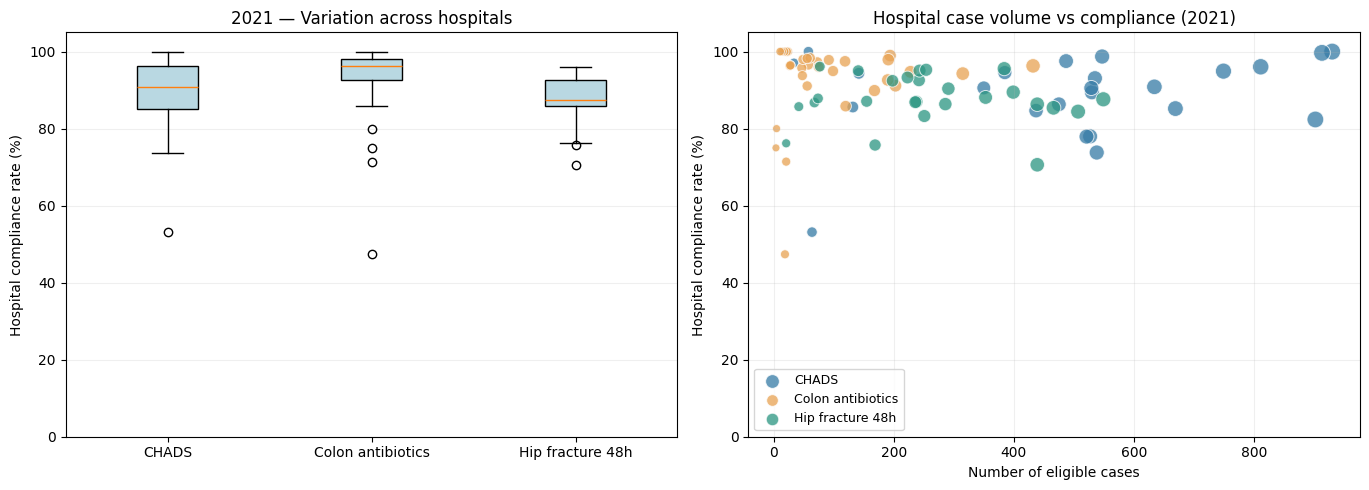

hospitals  avg_hospital_rate   cases
metric_short      centrality                                      
CHADS             מרכז               16              88.33  7865.0
                  פריפריה             8              90.14  4034.0
Colon antibiotics מרכז               23              92.72  2604.0
                  פריפריה            10              92.72   491.0
Hip fracture 48h  מרכז               17              88.03  5155.0
                  פריפריה             9              87.10  1590.0

In [37]:
q21 = clinical_hy.loc[clinical_hy.measurement_year.eq(2021)].copy()
summary_hospitals = q21.groupby('metric_short').agg(
    hospitals=('hospital_id','nunique'),
    mean_hospital_rate=('rate_if_blank_zero_pct','mean'),
    median_hospital_rate=('rate_if_blank_zero_pct','median'),
    min_hospital_rate=('rate_if_blank_zero_pct','min'),
    max_hospital_rate=('rate_if_blank_zero_pct','max'),
    cases=('cases','sum')).round(2)
print('2021 hospital-level descriptive EDA (unweighted hospital-level distribution):')
display(summary_hospitals)

metric_order=['CHADS','Colon antibiotics','Hip fracture 48h']
fig,axs=plt.subplots(1,2,figsize=(13.8,5))
box_series=[q21.loc[q21.metric_short.eq(m),'rate_if_blank_zero_pct'].to_numpy() for m in metric_order]
axs[0].boxplot(box_series,labels=metric_order,patch_artist=True,boxprops=dict(facecolor='#B9D8E2'))
axs[0].set(title='2021 — Variation across hospitals',ylabel='Hospital compliance rate (%)',ylim=(0,105));axs[0].grid(axis='y',alpha=.2)
colors={'CHADS':'#377CA6','Colon antibiotics':'#E8A354','Hip fracture 48h':'#2D9682'}
for m in metric_order:
    s=q21.loc[q21.metric_short.eq(m)]
    axs[1].scatter(s['cases'],s['rate_if_blank_zero_pct'],s=25+np.sqrt(s['cases'])*4,
                   alpha=.76,c=colors[m],label=m,edgecolors='white',linewidth=.7)
axs[1].set(title='Hospital case volume vs compliance (2021)',xlabel='Number of eligible cases',ylabel='Hospital compliance rate (%)',ylim=(0,105))
axs[1].legend(fontsize=9);axs[1].grid(alpha=.2)
plt.tight_layout();fig.savefig('charts/quality_2021_hospital_distributions_and_case_volume.png',dpi=180,bbox_inches='tight');plt.show()

display((q21.groupby(['metric_short','centrality']).agg(hospitals=('hospital_id','nunique'),
              avg_hospital_rate=('rate_if_blank_zero_pct','mean'),
              cases=('cases','sum')).round(2)))


## 6. חיבור הרכב המתמחים 2021 למדדי האיכות 2021 — חקירה אקולוגית

**יחידת ההשוואה: בית חולים אחד = נקודה אחת.** נשווה את שיעור המתמחים בוגרי מוסדות שלא היו מאושרים במקור משנת 2021 עם שיעור העמידה המדווח במדדי איכות באותה שנה. לא נפרש את התוצאה כהשפעה של רופא יחיד: הנתונים על המתמחים ועל כלל המטופלים אינם מקושרים זה לזה פרטנית, ושיעור המתמחים אינו משוקלל במספר המתמחים הכולל. כמו כן איכות המדד תלויה בגודל ובאופי בית החולים ובמטופלים.

בניתוח הראשי נחבר דרך **HospitalID** ולא לפי השם הטקסטואלי. המתאמים הם **תיאוריים ואקספלורטיביים בלבד**; במיוחד אין בסיס להצהיר שמסלול לימודים גרם להבדל באיכות טיפול.

In [38]:
res21 = (residents_2021[['source_chart_order','hospital_name_he',
          'trained_israel_pct','trained_abroad_approved_pct','trained_abroad_unapproved_pct']]
         .rename(columns={'source_chart_order':'hospital_id'}).copy())
matched_quality = q21.merge(res21,on='hospital_id',how='inner',validate='many_to_one')
match_cover = pd.DataFrame([
    {'measure':m,'all_hospitals_2021':int(q21.loc[q21.metric_short.eq(m),'hospital_id'].nunique()),
     'matched_with_training':int(matched_quality.loc[matched_quality.metric_short.eq(m),'hospital_id'].nunique()),
     'eligible_cases_in_matched_hospitals':int(matched_quality.loc[matched_quality.metric_short.eq(m),'cases'].sum())}
    for m in metric_order
])
print('Matched hospital coverage — exact 2021 cross-section:')
display(match_cover)

correlations=[]
for metric,g in matched_quality.groupby('metric_short'):
    x=g['trained_abroad_unapproved_pct'].to_numpy()
    y=g['rate_if_blank_zero_pct'].to_numpy()
    pr=pearsonr(x,y)
    sr=spearmanr(x,y)
    eligible=g.loc[g.cases.ge(50)]
    pr_large = pearsonr(eligible['trained_abroad_unapproved_pct'],eligible['rate_if_blank_zero_pct']) if len(eligible)>=5 else None
    correlations.append({'metric':metric,'n_hospitals':len(g),'pearson_r':pr.statistic,
                         'exploratory_p':pr.pvalue,'spearman_rho':sr.statistic,
                         'n_hospitals_50plus_cases':len(eligible),
                         'pearson_r_50plus':(pr_large.statistic if pr_large else np.nan)})
correlations=pd.DataFrame(correlations).sort_values('metric')
print('Exploratory hospital-level correlations; ZERO ASSUMPTION in missing numerators:')
display(correlations.round(3))
correlations.to_csv('exports/MOH_2021_training_quality_correlations_PROVISIONAL.csv',index=False,encoding='utf-8-sig')
print('No causal conclusions, and these are not patient-level correlations.')


Matched hospital coverage — exact 2021 cross-section:


,measure,all_hospitals_2021,matched_with_training,eligible_cases_in_matched_hospitals
0,CHADS,24,21,11591
1,Colon antibiotics,33,24,2654
2,Hip fracture 48h,26,23,6605


Exploratory hospital-level correlations; ZERO ASSUMPTION in missing numerators:


,metric,n_hospitals,pearson_r,exploratory_p,spearman_rho,n_hospitals_50plus_cases,pearson_r_50plus
0,CHADS,21,-0.128,0.581,-0.311,21,-0.128
1,Colon antibiotics,24,-0.174,0.415,-0.092,15,-0.244
2,Hip fracture 48h,23,0.295,0.172,0.339,23,0.295


No causal conclusions, and these are not patient-level correlations.


### 6.1 — שלושה גרפי Scatter: קשר אפשרי בין הרכב המתמחים לעמידה במדדים

הנקודות צבועות לפי מרכזיות (מרכז/פריפריה), ו**שטח הנקודה מציין בקירוב את מספר המקרים** ששימשו לחישוב המדד. כך אפשר לזהות אם הקשר נראה רק בקבוצת בתי חולים קטנים או רק באזור גיאוגרפי מסוים.

כאן **לא מציירים קו רגרסיה כמסקנה קלינית**. מציינים מתאם Pearson ו־n בלבד. זאת בדיקת קשר תיאורית, כשקיים חשש לקונפאונדינג והטיית מדידה.

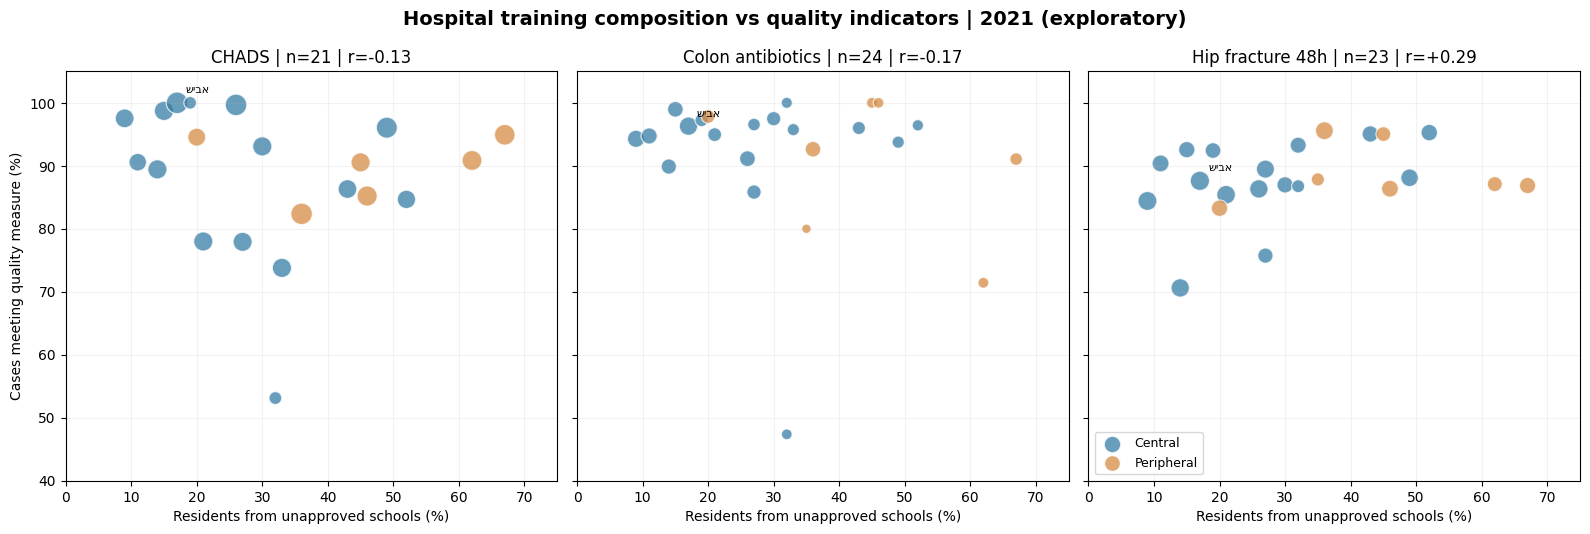

In [39]:
fig,axs=plt.subplots(1,3,figsize=(16,5.4),sharey=True)
for ax,m in zip(axs,metric_order):
    s=matched_quality.loc[matched_quality.metric_short.eq(m)].copy()
    for cent,color in [('מרכז','#377CA6'),('פריפריה','#D68B43')]:
        z=s.loc[s.centrality.eq(cent)]
        ax.scatter(z.trained_abroad_unapproved_pct,z.rate_if_blank_zero_pct,
                   s=30+np.sqrt(z.cases)*7,c=color,alpha=.75,edgecolors='white',linewidth=.9,
                   label='Central' if cent=='מרכז' else 'Peripheral')
    r_value=correlations.set_index('metric').loc[m,'pearson_r']
    ax.set(title=f'{m} | n={len(s)} | r={r_value:+.2f}',
           xlabel='Residents from unapproved schools (%)',xlim=(0,75),ylim=(40,105))
    ax.grid(alpha=.16)
    if m=='CHADS': ax.set_ylabel('Cases meeting quality measure (%)')
    for k in s.sort_values('cases',ascending=False).head(1).itertuples():
        ax.annotate(k.hospital_name_he, (k.trained_abroad_unapproved_pct,k.rate_if_blank_zero_pct),
                    xytext=(6,7),textcoords='offset points',fontsize=8)
axs[2].legend(loc='lower left',fontsize=9)
fig.suptitle('Hospital training composition vs quality indicators | 2021 (exploratory)',fontsize=14,weight='bold')
plt.tight_layout();fig.savefig('charts/quality_2021_training_vs_three_quality_measures.png',dpi=180,bbox_inches='tight');plt.show()


### 6.2 — מה משנות הנחות הניקוי ומאפייני בית החולים?

נבחן רגישות לבתי חולים עם מעט מקרים: חישוב חוזר כאשר יש לכל בית חולים לפחות **50 מקרים** במדד. בנוסף נבחן האם בתי חולים בפריפריה נוטים לדווח שיעור גבוה יותר של מתמחים ממוסדות לא מאושרים, שכן זה משתנה רקע שעשוי לשבש את הפרשנות. **הסף 50 הוא סף בדיקת רגישות שרירותי, לא תקן קליני.**

כדי לא להעמיס מתאמים מרובים על המדגם הקטן, נציג רק שלוש בדיקות ראשיות (אחת לכל מדד) ונציין שה־p הוא תיאורי ולא מסקנה לאחר תיקון לריבוי בדיקות.

In [40]:
print('Sensitivity summary: with and without small-case hospitals (>=50):')
display(correlations[['metric','n_hospitals','pearson_r','n_hospitals_50plus_cases','pearson_r_50plus']].round(3))

confounder = (matched_quality.groupby(['metric_short','centrality'])
              .agg(hospitals=('hospital_id','nunique'),
                   unapproved_share_mean=('trained_abroad_unapproved_pct','mean'),
                   clinical_rate_mean=('rate_if_blank_zero_pct','mean'),
                   eligible_cases=('cases','sum'))).round(2)
print('Potential confounding: centre/periphery differences:')
display(confounder)

# Examine naively excluding blank numerator rows as a sensitivity check.
observed = clinical.loc[~clinical['approved_missing']].groupby(
    ['metric_short','measurement_year','hospital_id'],as_index=False).agg(
        observed_cases=('number_of_cases','sum'), approved=('number_of_cases_approved','sum'))
observed['rate_complete_only_pct']=100*observed.approved/observed.observed_cases
complete_matched = (matched_quality.merge(
    observed.loc[observed.measurement_year.eq(2021), ['metric_short','hospital_id','rate_complete_only_pct']],
    on=['metric_short','hospital_id'],how='left',validate='one_to_one'))
comparison=[]
for metric,z in complete_matched.groupby('metric_short'):
    complete=z.dropna(subset=['rate_complete_only_pct'])
    r_complete=pearsonr(complete.trained_abroad_unapproved_pct,complete.rate_complete_only_pct).statistic if complete.rate_complete_only_pct.nunique()>1 else np.nan
    comparison.append({'metric':metric,'pearson_blank_zero':pearsonr(z.trained_abroad_unapproved_pct,z.rate_if_blank_zero_pct).statistic,
                       'pearson_exclude_missing_rows':r_complete,
                       'median_absolute_quality_rate_difference_pp':(z.rate_if_blank_zero_pct-z.rate_complete_only_pct).abs().median()})
print('Sensitivity to numerator encoding (excluding missing is not an official alternative):')
display(pd.DataFrame(comparison).round(3))


Sensitivity summary: with and without small-case hospitals (>=50):


,metric,n_hospitals,pearson_r,n_hospitals_50plus_cases,pearson_r_50plus
0,CHADS,21,-0.128,21,-0.128
1,Colon antibiotics,24,-0.174,15,-0.244
2,Hip fracture 48h,23,0.295,23,0.295


Potential confounding: centre/periphery differences:


hospitals  unapproved_share_mean  clinical_rate_mean  eligible_cases
metric_short      centrality                                                                      
CHADS             מרכז               15                  26.53               87.93          7723.0
                  פריפריה             6                  46.00               89.74          3868.0
Colon antibiotics מרכז               17                  26.88               92.16          2250.0
                  פריפריה             7                  44.43               90.42           404.0
Hip fracture 48h  מרכז               16                  26.50               87.53          5078.0
                  פריפריה             7                  44.43               88.86          1527.0

Sensitivity to numerator encoding (excluding missing is not an official alternative):


,metric,pearson_blank_zero,pearson_exclude_missing_rows,median_absolute_quality_rate_difference_pp
0,CHADS,-0.128,-0.224,1.579
1,Colon antibiotics,-0.174,-0.207,4.653
2,Hip fracture 48h,0.295,NaN,12.386



### 6.3 — Bubble scatter לכל בתי החולים: עמידה ביעד מול הרכב המתמחים

בתרשים הבא כל נקודה היא **בית חולים–מדד** בשנת 2021.

- ציר X: אחוז המתמחים מבוגרי מוסדות לא מאושרים בחו"ל.
- ציר Y: שיעור העמידה ביעד האיכות.
- צבע הבועה: סוג המדד (`CHADS` / `Colon antibiotics` / `Hip fracture 48h`).
- גודל הבועה: קבוצת גודל בית החולים.
- נקודה שחורה במרכז: בית חולים בפריפריה.
- שם בית החולים מופיע באנגלית, בכתב קטן, פעם אחת ליד המיקום הממוצע של שלוש הנקודות שלו.

זהו תרשים מעבר חשוב **לפני ההעמקה בשני הזוגות**: הוא מראה את כל המערכת, עוזר לזהות חריגים, ורק אחר כך אנחנו בוחרים זוגות להשוואה פרטנית.


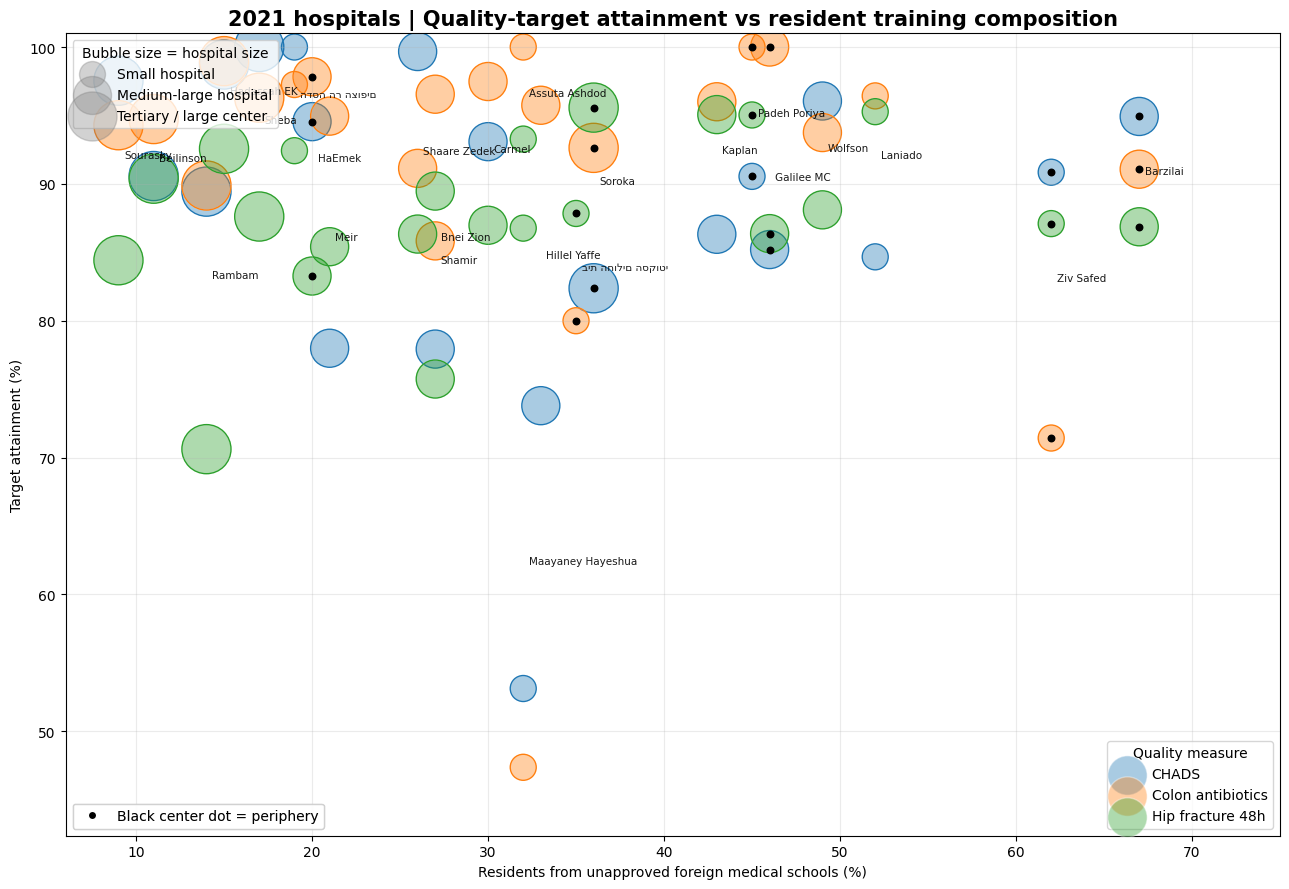

,hospital_name,hospital_label_en,centrality,hospital_size,metric_label,x_unapproved_pct,y_target_pct,cases
0,איכילוב סוראסקי,Sourasky,מרכז,מרכז על,CHADS,9,97.535934,487.0
1,בילינסון,Beilinson,מרכז,מרכז על,CHADS,11,90.571429,350.0
20,ברזילי,Barzilai,פריפריה,בינוניים - גדולים,CHADS,67,94.926569,749.0
5,הדסה הר הצופים,הדסה הר הצופים,מרכז,קטנים,CHADS,19,100.000000,58.0
3,הדסה עין כרם,Hadassah EK,מרכז,מרכז על,CHADS,15,98.720293,547.0
12,הלל יפה,Hillel Yaffe,מרכז,בינוניים - גדולים,CHADS,33,73.791822,538.0
6,המרכז הרפואי העמק,HaEmek,פריפריה,בינוניים - גדולים,CHADS,20,94.545455,385.0
16,המרכז הרפואי לגליל,Galilee MC,פריפריה,בינוניים - גדולים,CHADS,46,85.201794,669.0
17,וולפסון,Wolfson,מרכז,בינוניים - גדולים,CHADS,49,96.054254,811.0
19,זיו צפת,Ziv Safed,פריפריה,קטנים,CHADS,62,90.851735,634.0


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

quality = pd.read_csv('exports/MOH_hospital_year_quality_PROVISIONAL.csv')
residents = pd.read_csv('data/residents_2021.csv')
hospitals = pd.read_csv('data/hospitals.csv')

name_map = {
    'שניידר': 'Schneider',
    'איכילוב סוראסקי': 'Sourasky',
    'בילינסון': 'Beilinson',
    'רמב"ם': 'Rambam',
    'הדסה עין כרם': 'Hadassah EK',
    'שיבא': 'Sheba',
    'הדסה הר צופים': 'Hadassah MS',
    'המרכז הרפואי העמק': 'HaEmek',
    'מאיר': 'Meir',
    'שערי צדק': 'Shaare Zedek',
    'בני ציון': 'Bnei Zion',
    'יצחק שמיר': 'Shamir',
    'כרמל': 'Carmel',
    'אסותא אשדוד': 'Assuta Ashdod',
    'מעיני הישועה': 'Maayaney Hayeshua',
    'הלל יפה': 'Hillel Yaffe',
    'הסקוטי': 'Scottish Hosp.',
    'סורוקה': 'Soroka',
    'קפלן': 'Kaplan',
    'פדה פוריה': 'Padeh Poriya',
    'המרכז הרפואי לגליל': 'Galilee MC',
    'וולפסון': 'Wolfson',
    'לניאדו': 'Laniado',
    'זיו צפת': 'Ziv Safed',
    'ברזילי': 'Barzilai'
}

residents_plot = residents.merge(
    hospitals[['hospital_id', 'hospital_name']],
    left_on='hospital_name_he',
    right_on='hospital_name',
    how='left'
)
residents_plot = residents_plot[[
    'hospital_id', 'hospital_name_he',
    'trained_israel_pct', 'trained_abroad_approved_pct', 'trained_abroad_unapproved_pct'
]]

plot_df = quality[quality['measurement_year'] == 2021].merge(
    residents_plot, on='hospital_id', how='inner'
)
plot_df['metric_label'] = 'Hip fracture 48h'
plot_df.loc[plot_df['metric_short'].str.contains('chads', case=False, na=False), 'metric_label'] = 'CHADS'
plot_df.loc[plot_df['metric_short'].str.contains('colon|antibi', case=False, na=False), 'metric_label'] = 'Colon antibiotics'
plot_df['x_unapproved_pct'] = plot_df['trained_abroad_unapproved_pct']
plot_df['y_target_pct'] = plot_df['rate_if_blank_zero_pct']
plot_df['bubble_size'] = plot_df['hospital_size'].map({
    'קטנים': 350,
    'בינוניים - גדולים': 750,
    'מרכז על': 1250
}).fillna(500)
plot_df['hospital_label_en'] = plot_df['hospital_name'].map(name_map).fillna(plot_df['hospital_name'])

metric_colors = {
    'CHADS': 'tab:blue',
    'Colon antibiotics': 'tab:orange',
    'Hip fracture 48h': 'tab:green'
}

fig, ax = plt.subplots(figsize=(13, 9))
for metric, sub in plot_df.groupby('metric_label'):
    color = metric_colors.get(metric, 'tab:gray')
    ax.scatter(sub['x_unapproved_pct'], sub['y_target_pct'], s=sub['bubble_size'], c=color, alpha=0.38,
               edgecolor='white', linewidth=1.0, label=metric)
    ax.scatter(sub['x_unapproved_pct'], sub['y_target_pct'], s=sub['bubble_size'], facecolors='none', edgecolors=color, linewidth=1.0)

periphery = plot_df[plot_df['centrality'] == 'פריפריה']
ax.scatter(periphery['x_unapproved_pct'], periphery['y_target_pct'], s=22, c='black', zorder=5)

label_df = plot_df.groupby(['hospital_id', 'hospital_name', 'hospital_label_en'], as_index=False).agg(
    x_unapproved_pct=('x_unapproved_pct', 'first'),
    y_mid=('y_target_pct', 'mean')
)
for _, row in label_df.iterrows():
    ax.annotate(row['hospital_label_en'], (row['x_unapproved_pct'], row['y_mid']), textcoords='offset points',
                xytext=(4, 0), fontsize=7.5, color='black', alpha=0.9, va='center')

ax.set_title('2021 hospitals | Quality-target attainment vs resident training composition', fontsize=15, weight='bold')
ax.set_xlabel('Residents from unapproved foreign medical schools (%)')
ax.set_ylabel('Target attainment (%)')
ax.grid(True, alpha=0.25)
ax.set_xlim(max(0, plot_df['x_unapproved_pct'].min() - 3), plot_df['x_unapproved_pct'].max() + 8)
ax.set_ylim(max(0, plot_df['y_target_pct'].min() - 5), min(101, plot_df['y_target_pct'].max() + 3))

legend1 = ax.legend(title='Quality measure', loc='lower right', frameon=True)
ax.add_artist(legend1)
size_handles = [plt.scatter([], [], s=s, color='gray', alpha=0.35, edgecolor='gray') for s in [350, 750, 1250]]
legend2 = ax.legend(size_handles, ['Small hospital', 'Medium-large hospital', 'Tertiary / large center'],
                    title='Bubble size = hospital size', loc='upper left', frameon=True)
ax.add_artist(legend2)
legend3 = ax.legend([Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=6)],
                    ['Black center dot = periphery'], loc='lower left', frameon=True)
ax.add_artist(legend3)

plt.tight_layout()
plt.show()

plot_df[['hospital_name', 'hospital_label_en', 'centrality', 'hospital_size', 'metric_label',
         'x_unapproved_pct', 'y_target_pct', 'cases']].sort_values(['metric_label', 'hospital_name']).head(20)


### הערה פרשנית קצרה

אם נראה ענן נקודות ללא שיפוע ברור, זה מחזק את מה שכבר ראינו: **אין קשר פשוט ואחיד** בין שיעור המתמחים מבוגרי מוסדות לא מאושרים לבין עמידה ביעדי האיכות. אם יופיעו חריגים או קבוצות משנה, הם יכולים לעזור לנו להבין **אילו בתי חולים שווה לבדוק פרטנית בשלב הבא**.


### 6.4 — השוואה ממוקדת באותה שנה: התמחות רלוונטית מול מדד קליני (2020)

**השאלה:** האם המתאם שנבדק ברמת הרכב *כל* המתמחים משתנה כשמשווים לכל מדד את **ההתמחות הרלוונטית ביותר**, וכששני המקורות הם מאותה שנה?

גרף ה־Scatter משלב שלושה מדדי איכות, בצבעים שונים:

- **כחול:** שיעור המתמחים בוגרי מוסדות לא מאושרים בקרדיולוגיה (יולי 2020) מול שיעור העמידה ב־CHADS (**2020**).
- **כתום:** השיעור בכירורגיה כללית (יולי 2020) מול מדד האנטיביוטיקה בניתוחי קולון (**2020**).
- **ירקרק:** השיעור באורתופדיה (יולי 2020) מול שיעור ניתוחי שבר שבוצעו תוך 48 שעות (**2020**).

**כל נקודה מייצגת בית חולים × מדד.** שמות בתי החולים באנגלית; גודל הבועה מייצג קטגוריית גודל, ונקודה שחורה מסמנת פריפריה. קווי מגמה מקווקווים הם תיאוריים בלבד. קיימות 29 תצפיות מתוך 30 אפשריות; אין נתון קרדיולוגיה לבילינסון, והוא אינו מוחלף באפס.

**מגבלות:** זוהי השוואה אקולוגית, *לא* מדידת איכות רופא. המתמחים והמקרים המטופלים לא קושרו זה לזה; בחירת התמחות אחת לכל מדד היא קירוב קליני בלבד; שיעורי האיכות עדיין *ראשוניים*: הטיפול במונה ריק נתמך בבדיקת סעיף 5.2.1, אך לא נמצא אישור מפורש של הספק, ובלעדיות פילוחי המקור עדיין דורשת אימות. ההתאמה לשנת 2020 מצמצמת בעיה של אי־התאמה בזמן, אך אינה מוכיחה קשר סיבתי.


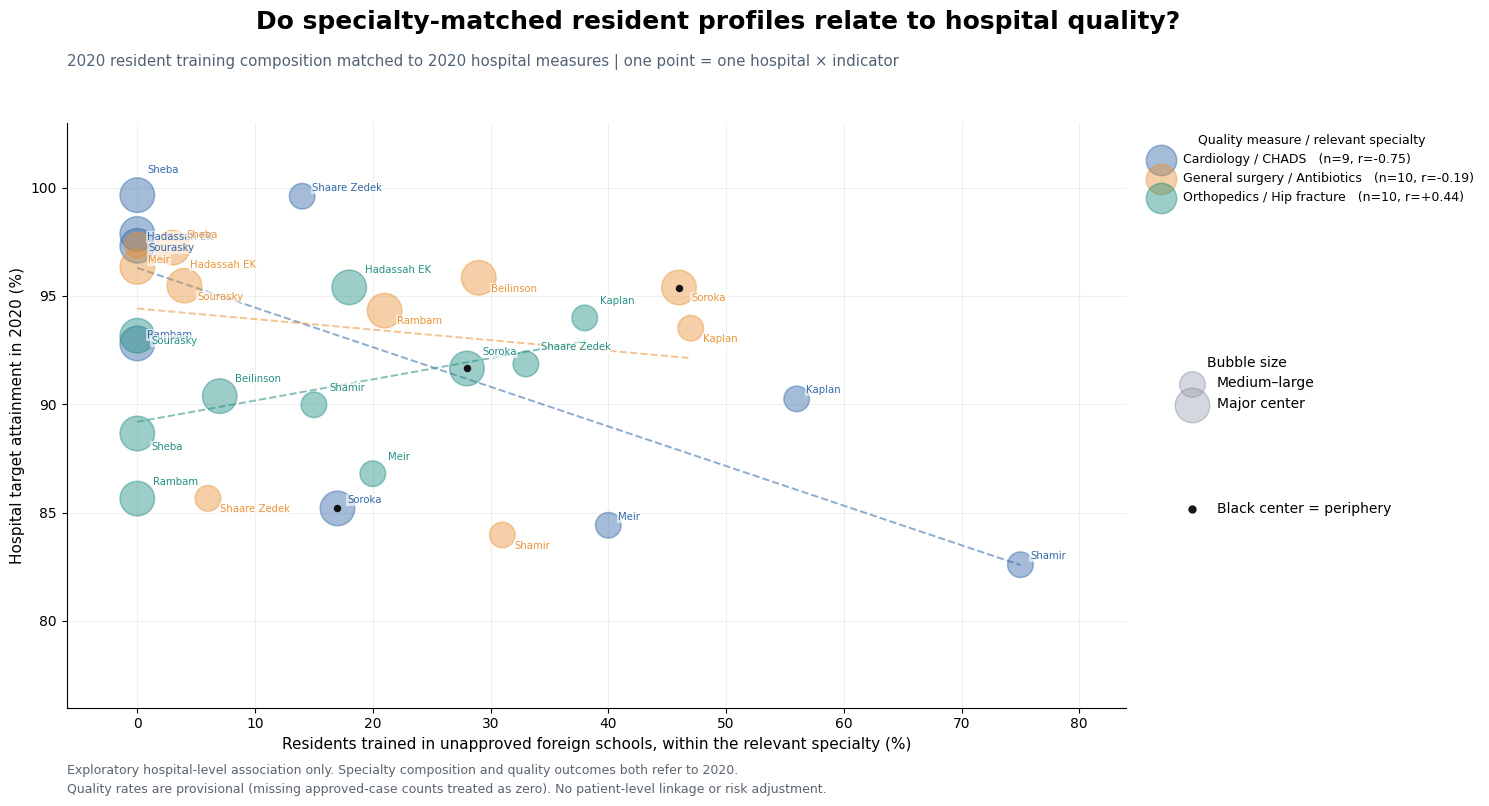

      specialty_he      metric_short  n_hospitals  pearson_r  pearson_p_value
        קרדיולוגיה             CHADS            9    -0.7504           0.0198
    כירורגיה כללית Colon antibiotics           10    -0.1913           0.5966
כירורגיה אורתופדית  Hip fracture 48h           10     0.4448           0.1977


In [42]:
# 6.4 — Specialty-matched 2020 resident composition versus 2020 hospital quality
# One combined figure, colored by clinical quality indicator. Both datasets represent 2020.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

specialty_to_hospital = {
    'kaplan': 19, 'meir': 9, 'beilinson': 3, 'shaare_zedek': 10,
    'shamir': 12, 'hadassah_ein_kerem': 5, 'soroka': 18,
    'rambam': 4, 'sheba': 6, 'sourasky': 2
}
hospital_names_en = {
    2: 'Sourasky', 3: 'Beilinson', 4: 'Rambam',
    5: 'Hadassah EK', 6: 'Sheba', 9: 'Meir',
    10: 'Shaare Zedek', 12: 'Shamir', 18: 'Soroka', 19: 'Kaplan'
}
# X is specialty-specific: not an overall hospital training share.
metric_specs = [
    ('קרדיולוגיה', 'CHADS', 'Cardiology / CHADS', '#3067A8'),
    ('כירורגיה כללית', 'Colon antibiotics', 'General surgery / Antibiotics', '#EA9338'),
    ('כירורגיה אורתופדית', 'Hip fracture 48h', 'Orthopedics / Hip fracture', '#218E82')
]

train20 = pd.read_csv('data/residents_2020_specialties.csv')
quality20 = pd.read_csv('exports/MOH_hospital_year_quality_PROVISIONAL.csv')
train20 = train20[train20['specialty_he'].isin([s[0] for s in metric_specs])].copy()
train20['hospital_id_numeric'] = train20['hospital_id'].map(specialty_to_hospital)
train20['metric_short'] = train20['specialty_he'].map({s[0]: s[1] for s in metric_specs})
assert train20['hospital_id_numeric'].notna().all(), '2020 hospital_id mapping has missing matches'
train20 = train20.merge(
    quality20[quality20['measurement_year'] == 2020],
    left_on=['hospital_id_numeric', 'metric_short'],
    right_on=['hospital_id', 'metric_short'],
    how='left', validate='one_to_one', indicator=True
)
assert train20['_merge'].eq('both').all(), 'There are unmatched hospital+measure pairs'
train20 = train20.dropna(subset=['unapproved_residents_pct', 'rate_if_blank_zero_pct']).copy()
train20['hospital_en'] = train20['hospital_id_numeric'].map(hospital_names_en)
train20['point_area'] = train20['hospital_size'].map({
    'קטנים': 180, 'בינוניים - גדולים': 340, 'מרכז על': 620
})
assert train20['point_area'].notna().all()

fig, ax = plt.subplots(figsize=(15.7, 9.0))
fig.subplots_adjust(left=0.085, right=0.76, top=0.84, bottom=0.19)
series_data = []
correlations = []
for idx, (specialty, metric, english_metric, color) in enumerate(metric_specs):
    segment = train20[train20['metric_short'] == metric].copy()
    x = segment['unapproved_residents_pct'].to_numpy()
    y = segment['rate_if_blank_zero_pct'].to_numpy()
    r, p = pearsonr(x, y)
    correlations.append({'specialty': specialty, 'metric': metric, 'n': len(segment), 'pearson_r': r, 'p_value': p})
    label = f'{english_metric}   (n={len(segment)}, r={r:+.2f})'
    ax.scatter(x, y, s=segment['point_area'], color=color, alpha=0.44,
               edgecolor=color, lw=1.1, label=label, zorder=3)
    black = segment['centrality'].eq('פריפריה')
    if black.any():
        ax.scatter(x[black], y[black], color='#121212', s=19, zorder=5)
    # Add a faint series-specific linear fit (descriptive only).
    z = np.polyfit(x, y, 1)
    fit_x = np.linspace(x.min(), x.max(), 80)
    ax.plot(fit_x, np.polyval(z, fit_x), color=color, alpha=0.55, lw=1.4, ls='--', zorder=2)
    label_offsets = {
        ('CHADS', 'Sheba'): (7, 16),
        ('CHADS', 'Hadassah EK'): (7, 4),
        ('CHADS', 'Sourasky'): (8, -12),
        ('Colon antibiotics', 'Hadassah EK'): (38, -1),
        ('Colon antibiotics', 'Meir'): (8, -13),
        ('Colon antibiotics', 'Sheba'): (10, 7),
        ('Hip fracture 48h', 'Sheba'): (10, -12),
        ('Hip fracture 48h', 'Sourasky'): (10, -6)
    }
    for _, row in segment.iterrows():
        xx, yy = row['unapproved_residents_pct'], row['rate_if_blank_zero_pct']
        # English labels, subtle series-specific color, with extra spacing in dense clusters at x=0.
        default_offset = (7 + idx * 2, [4, -10, 10][idx])
        label_offset = label_offsets.get((metric, row['hospital_en']), default_offset)
        ax.annotate(row['hospital_en'], (xx, yy),
                    xytext=label_offset, textcoords='offset points',
                    fontsize=7.3, color=color, fontweight='medium', alpha=0.99,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.60, pad=0.7), zorder=6)

ax.set_xlim(-6, 84)
ax.set_ylim(76, 103)
ax.set_xticks(np.arange(0, 81, 10))
ax.set_yticks(np.arange(80, 101, 5))
ax.set_xlabel('Residents trained in unapproved foreign schools, within the relevant specialty (%)', fontsize=11)
ax.set_ylabel('Hospital target attainment in 2020 (%)', fontsize=11)
ax.grid(alpha=0.18, zorder=0)
ax.spines[['top','right']].set_visible(False)
fig.suptitle('Do specialty-matched resident profiles relate to hospital quality?',
             fontsize=18, fontweight='bold', y=0.965)
fig.text(0.085,0.903,'2020 resident training composition matched to 2020 hospital measures | one point = one hospital × indicator',
         fontsize=10.8,color='#526275')

# Legends outside the axes to minimize overlap with hospital names
ax.legend(title='Quality measure / relevant specialty', loc='upper left',
          bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=9, title_fontsize=9)
size_handles=[ax.scatter([],[],s=s,color='#8E9AA9',alpha=0.38,edgecolor='#738093') for s in (340,620)]
fig.legend(size_handles,['Medium–large','Major center'],loc='center left',
           bbox_to_anchor=(0.785,0.55),frameon=False,title='Bubble size')
black_symbol = Line2D([], [], marker='o', ls='', color='#161616', markersize=5)
fig.legend([black_symbol], ['Black center = periphery'],loc='center left',
           bbox_to_anchor=(0.785,0.41),frameon=False)
fig.text(0.085,0.095,
         'Exploratory hospital-level association only. Specialty composition and quality outcomes both refer to 2020.\n'
         'Quality rates are provisional (missing approved-case counts treated as zero). No patient-level linkage or risk adjustment.',
         fontsize=9,color='#5B6470',linespacing=1.6)

# Save an editable/reproducible chart and matching data exports.
fig.savefig('charts/quality_specialty_2020_vs_quality_2020_combined_en.png', dpi=220, bbox_inches='tight')
matched_export = train20.rename(columns={
    'unapproved_residents_pct': 'training_pct_2020',
    'rate_if_blank_zero_pct': 'quality_pct_2020_provisional',
    'hospital_id_x': 'original_hospital_id'
})
matched_export[[
    'hospital_id_numeric','hospital_en','hospital_name_he','specialty_he',
    'metric_short','training_pct_2020','quality_pct_2020_provisional',
    'cases','hospital_size','centrality','blank_numerator_rows'
]].sort_values(['metric_short','hospital_en']).to_csv(
    'exports/MOH_2020_specialty_vs_2020_quality_matched_PROVISIONAL.csv', index=False)
corr_export = pd.DataFrame(correlations).rename(columns={
    'specialty':'specialty_he','metric':'metric_short',
    'n':'n_hospitals','p_value':'pearson_p_value'
})
corr_export.to_csv('exports/MOH_2020_specialty_vs_2020_quality_pearson_PROVISIONAL.csv', index=False)
plt.show()
print(corr_export.round(4).to_string(index=False))

**ממצאים ראשוניים, נתוני התמחות ואיכות מאותה שנת 2020 (Pearson):** קרדיולוגיה–CHADS: `r≈−0.750`, 9 בתי חולים (`p≈0.020`); כירורגיה כללית–אנטיביוטיקה: `r≈−0.191`, 10 בתי חולים (`p≈0.597`); אורתופדיה–שבר: `r≈+0.445`, 10 בתי חולים (`p≈0.198`).

**ללא תיקון לריבוי בדיקות**, קרדיולוגיה–CHADS מובהק ברמת 5%; לאחר תיקון שמרני לשלוש הבדיקות (למשל Bonferroni), הוא **כבר אינו מובהק** (`p≈0.059`). המדגם קטן, המדדים אינם מצביעים ישירות על איכות הרופאים, ואי־אפשר להסיק סיבתיות. בנוסף יש לבדוק השפעה של חריגים, גודל בית החולים, תמהיל מטופלים וחוסרים בנתוני האיכות. אין לבלבל את הממצאים האלה עם שלושת המתאמים על ההרכב הכולל בשנת 2021 בסעיף 6.2, שנבדקו על מדגם ומשתני X אחרים.


### 6.5 — בדיקת רגישות נוספת: האם המתאם בקרדיולוגיה תלוי בבית חולים חריג?

אחרי התאמת **קרדיולוגיה 2020 ↔ CHADS 2020**, נבצע Leave-One-Hospital-Out: נוציא בכל פעם בית חולים אחד ונחשב מחדש את Pearson. כך נוכל לבדוק האם כיוון הקשר תלוי בנקודה יחידה. שינוי קטן במתאם **אינו מתקן** את בעיות המדגם הקטן, החשיפה הלא־ישירה, הבדלי תמהיל מטופלים, ריבוי הבדיקות והנחת הטיפול ב־NULL.

In [43]:
# 6.5 — Leave-one-hospital-out stability of the 2020 cardiology/CHADS association.
from scipy.stats import pearsonr
cardio = train20.loc[train20['metric_short'].eq('CHADS')].copy()
assert len(cardio) == 9
loo_rows=[]
for hospital in cardio['hospital_en'].sort_values().tolist():
    subset = cardio.loc[cardio['hospital_en'].ne(hospital)]
    stat,pvalue=pearsonr(subset['unapproved_residents_pct'],subset['rate_if_blank_zero_pct'])
    loo_rows.append({'excluded_hospital':hospital,'remaining_hospitals':len(subset),
                     'pearson_r':stat,'nominal_p_value':pvalue})
cardio_loo=pd.DataFrame(loo_rows).sort_values('pearson_r')
display(cardio_loo.round(3))
print('Leave-one-out r range:',cardio_loo.pearson_r.min().round(3),
      'to',cardio_loo.pearson_r.max().round(3))
print('Always negative?',bool((cardio_loo.pearson_r<0).all()))
cardio_loo.to_csv('exports/MOH_2020_Cardiology_CHADS_Leave_One_Out.csv',index=False)


,excluded_hospital,remaining_hospitals,pearson_r,nominal_p_value
7,Soroka,8,-0.845,0.008
1,Kaplan,8,-0.791,0.019
3,Rambam,8,-0.776,0.023
4,Shaare Zedek,8,-0.776,0.024
2,Meir,8,-0.740,0.036
0,Hadassah EK,8,-0.728,0.041
8,Sourasky,8,-0.725,0.042
6,Sheba,8,-0.721,0.043
5,Shamir,8,-0.630,0.094


Leave-one-out r range: -0.845 to -0.63
Always negative? True


**פרשנות:** אם המתאם נשאר שלילי בכל ההשמטות, הקשר המדגמי אינו תלוי בבית חולים בודד; אבל מדובר במדד ביצועי בית חולים ולא בתוצאת טיפול שמקושרת לרופא, ולכן **אי אפשר להסיק על איכות הבוגרים**. בנוסף, תוצאת קרדיולוגיה–CHADS אינה מובהקת אחרי תיקון Bonferroni לשלושת המדדים.

## 7. העמקה: שני זוגות בתי חולים דומים — העמק מול ברזילי; מאיר מול קפלן

נבחן **רק שני זוגות**: (א) **העמק–ברזילי**, אותו סיווג פריפריה ואותה קטגוריית גודל, אך בעלות שונה; (ב) **מאיר–קפלן**, אותו סיווג מרכז, אותה קטגוריית גודל ואותה בעלות (כללית). שיעור המתמחים בוגרי מוסדות לא מאושרים (2021) הוא בהתאמה **20% מול 67%** ו־**21% מול 43%**. אלו **אחוזים של כלל המתמחים בבית החולים**, לא שיעור הרופאים המטפלים בפועל או שיעור המתמחים שהשתתפו במקרים שבמדדים.

נשווה לכל מדד את שיעור העמידה המשוקלל לפי *מספר המקרים* ב־2021, ולא ממוצע של שורות המקור. נבדוק הבדלים בפרופיל המקרים (מין, גיל, שיטת טיפול ומשמרת כאשר רלוונטי), מגמות דיווח לאורך השנים ורגישות להנחות החסרים. **חשוב:** פרשנות מונה חסר כ־0 הצלחות נותרת הנחת עבודה לא מאומתת רשמית; כל התוצאות להלן ראשוניות, אינן קביעה של איכות רפואית או השפעת מסלול ההכשרה, ואינן בודקות תוצאים ברמת רופא או מטופל.

In [44]:
# 7.1 — Matched pair selection, hospital descriptors and training stock.
from IPython.display import display
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker

PAIR_SPECS = [
    {'pair_name':'HaEmek vs Barzilai','a':8,'b':25,'a_en':'HaEmek','b_en':'Barzilai',
     'short':'Peripheral, same hospital-size category; different ownership'},
    {'pair_name':'Meir vs Kaplan','a':9,'b':19,'a_en':'Meir','b_en':'Kaplan',
     'short':'Central, same hospital-size category and ownership (Clalit)'},
]
PAIR_IDS = sorted({v for z in PAIR_SPECS for v in (z['a'],z['b'])})
PAIR_LABELS = {z['a']:z['a_en'] for z in PAIR_SPECS} | {z['b']:z['b_en'] for z in PAIR_SPECS}
PAIR_GROUP = {h:z['pair_name'] for z in PAIR_SPECS for h in (z['a'],z['b'])}

pairs_2021 = matched_quality.loc[matched_quality.hospital_id.isin(PAIR_IDS)].copy()
pair_descriptors = (pairs_2021.sort_values('metric_short')
     .drop_duplicates('hospital_id')
     [['hospital_id','hospital_name_he','centrality','hospital_size','trained_israel_pct',
       'trained_abroad_approved_pct','trained_abroad_unapproved_pct']].copy())
pair_descriptors['ownership'] = pair_descriptors['hospital_id'].map(
    clinical.loc[clinical.measurement_year.eq(2021)]
    .groupby('hospital_id')['provider_ownership']
    .agg(lambda s:s.mode().iloc[0] if len(s.mode()) else np.nan))
pair_descriptors['pair']=pair_descriptors.hospital_id.map(PAIR_GROUP)
pair_descriptors['short_name']=pair_descriptors.hospital_id.map(PAIR_LABELS)
print('Hospitals, matching variables and resident training composition (2021):')
display(pair_descriptors[['pair','short_name','hospital_name_he','centrality','hospital_size','ownership',
  'trained_israel_pct','trained_abroad_approved_pct','trained_abroad_unapproved_pct']])
assert set(pair_descriptors.hospital_id)==set(PAIR_IDS)

pair_diffs=[]
for z in PAIR_SPECS:
    aa=pair_descriptors.set_index('hospital_id').loc[z['a']]
    bb=pair_descriptors.set_index('hospital_id').loc[z['b']]
    pair_diffs.append({'pair':z['pair_name'], 'difference_unapproved_pp':
      round(float(bb.trained_abroad_unapproved_pct-aa.trained_abroad_unapproved_pct),1),
      'same_centrality':aa.centrality==bb.centrality,
      'same_size_band':aa.hospital_size==bb.hospital_size,
      'same_ownership':aa.ownership==bb.ownership})
display(pd.DataFrame(pair_diffs))

Hospitals, matching variables and resident training composition (2021):


,pair,short_name,hospital_name_he,centrality,hospital_size,ownership,trained_israel_pct,trained_abroad_approved_pct,trained_abroad_unapproved_pct
6,HaEmek vs Barzilai,HaEmek,המרכז הרפואי העמק,פריפריה,בינוניים - גדולים,כללית,49,31,20
7,Meir vs Kaplan,Meir,מאיר,מרכז,בינוניים - גדולים,כללית,51,28,21
14,Meir vs Kaplan,Kaplan,קפלן,מרכז,בינוניים - גדולים,כללית,36,21,43
20,HaEmek vs Barzilai,Barzilai,ברזילי,פריפריה,בינוניים - גדולים,ממשלתית,6,27,67


,pair,difference_unapproved_pp,same_centrality,same_size_band,same_ownership
0,HaEmek vs Barzilai,47.0,True,True,False
1,Meir vs Kaplan,22.0,True,True,True


### 7.2 — השוואת שלושת מדדי האיכות בשנת 2021

המונה הוא סכום המקרים שעמדו במדד והמכנה סכום המקרים הרלוונטיים. נציג לצד האחוז את מספר המקרים, ולכן פער של כמה נקודות אחוז ב־50 מקרים אינו שקול לנתון באלפי מקרים. רווחי הסמך שיוצגו **המחשה תיאורית בלבד תחת הנחת ברנולי פשוטה**; הם אינם מתקנים תלות בין מקרים, הבדלי תמהיל קליני, שינויי מדידה או בחירה בדיעבד של שני הזוגות.

2021 outcome rates (PROVISIONAL, blank numerators treated as zero successes):


,pair,hospital,metric_short,cases,approved_if_blank_zero,failures_if_blank_zero,rate_if_blank_zero_pct,blank_numerator_rows
30,HaEmek vs Barzilai,HaEmek,CHADS,385.0,364.0,21.0,94.55,5
31,Meir vs Kaplan,Meir,CHADS,527.0,411.0,116.0,77.99,16
38,Meir vs Kaplan,Kaplan,CHADS,475.0,410.0,65.0,86.32,9
44,HaEmek vs Barzilai,Barzilai,CHADS,749.0,711.0,38.0,94.93,2
157,HaEmek vs Barzilai,HaEmek,Colon antibiotics,92.0,90.0,2.0,97.83,2
158,Meir vs Kaplan,Meir,Colon antibiotics,99.0,94.0,5.0,94.95,5
168,Meir vs Kaplan,Kaplan,Colon antibiotics,75.0,72.0,3.0,96.00,3
174,HaEmek vs Barzilai,Barzilai,Colon antibiotics,56.0,51.0,5.0,91.07,5
315,HaEmek vs Barzilai,HaEmek,Hip fracture 48h,251.0,209.0,42.0,83.27,42
316,Meir vs Kaplan,Meir,Hip fracture 48h,466.0,398.0,68.0,85.41,68


Differences (second hospital minus first hospital), percentage points:


,pair,measure,difference_second_minus_first_pp,approx_lower_95_pp,approx_upper_95_pp,n_first,n_second
0,HaEmek vs Barzilai,CHADS,0.38,-2.38,3.14,385,749
1,HaEmek vs Barzilai,Colon antibiotics,-6.75,-14.80,1.29,92,56
2,HaEmek vs Barzilai,Hip fracture 48h,3.60,-2.72,9.91,251,236
3,Meir vs Kaplan,CHADS,8.33,3.63,13.02,527,475
4,Meir vs Kaplan,Colon antibiotics,1.05,-5.14,7.24,99,75
5,Meir vs Kaplan,Hip fracture 48h,9.65,5.45,13.86,466,243


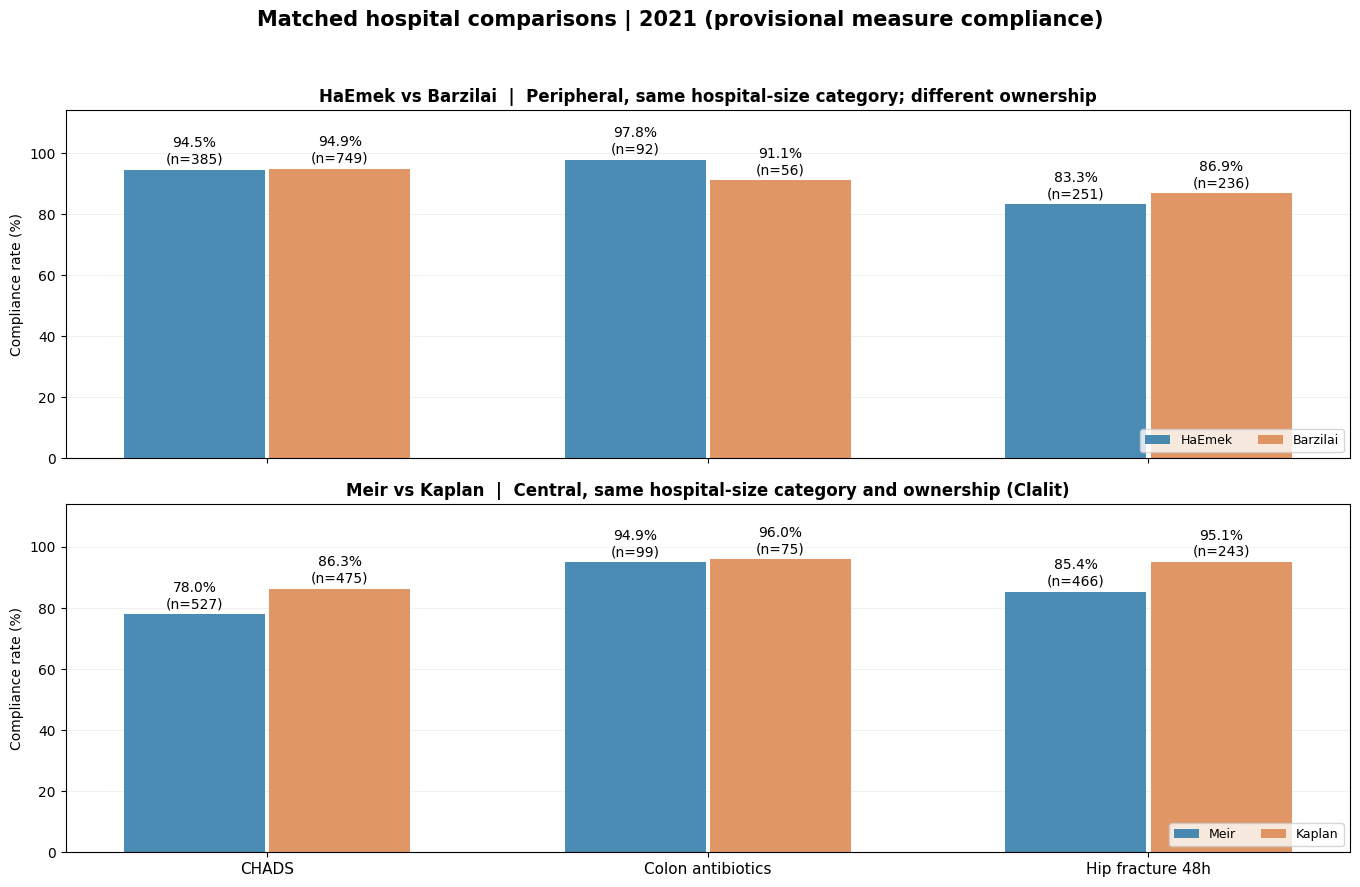

In [45]:
# 7.2 — Complete 2021 numerator/denominator/rate comparison and approximate difference CI.
pair_rates_2021 = (clinical_hy.loc[
    clinical_hy.measurement_year.eq(2021) & clinical_hy.hospital_id.isin(PAIR_IDS),
    ['hospital_id','metric_short','cases','approved_if_blank_zero','blank_numerator_rows',
     'rate_if_blank_zero_pct']].copy())
pair_rates_2021['hospital']=pair_rates_2021.hospital_id.map(PAIR_LABELS)
pair_rates_2021['pair']=pair_rates_2021.hospital_id.map(PAIR_GROUP)
pair_rates_2021['failures_if_blank_zero']=pair_rates_2021.cases-pair_rates_2021.approved_if_blank_zero
print('2021 outcome rates (PROVISIONAL, blank numerators treated as zero successes):')
display(pair_rates_2021[['pair','hospital','metric_short','cases','approved_if_blank_zero',
   'failures_if_blank_zero','rate_if_blank_zero_pct','blank_numerator_rows']].round(2))

pair_differences=[]
for z in PAIR_SPECS:
    for metric in metric_order:
        a=pair_rates_2021.loc[(pair_rates_2021.hospital_id==z['a']) & (pair_rates_2021.metric_short==metric)].iloc[0]
        b=pair_rates_2021.loc[(pair_rates_2021.hospital_id==z['b']) & (pair_rates_2021.metric_short==metric)].iloc[0]
        pa=a.rate_if_blank_zero_pct/100.; pb=b.rate_if_blank_zero_pct/100.
        diff=100*(pb-pa)  # second minus first
        se=100*np.sqrt(pa*(1-pa)/a.cases+pb*(1-pb)/b.cases)
        pair_differences.append({'pair':z['pair_name'],'measure':metric,
           'difference_second_minus_first_pp':diff,
           'approx_lower_95_pp':diff-1.96*se,'approx_upper_95_pp':diff+1.96*se,
           'n_first':int(a.cases),'n_second':int(b.cases)})
pair_diff_df=pd.DataFrame(pair_differences)
print('Differences (second hospital minus first hospital), percentage points:')
display(pair_diff_df.round(2))

fig,axes=plt.subplots(2,1,figsize=(13.7,9.0),sharex=True)
colors=['#317CAA','#DD8950']
for ax,z in zip(axes,PAIR_SPECS):
    pos=np.arange(len(metric_order))
    for idx,(hospital,label,color) in enumerate([(z['a'],z['a_en'],colors[0]),(z['b'],z['b_en'],colors[1])]):
        rows=pair_rates_2021.loc[pair_rates_2021.hospital_id.eq(hospital)].set_index('metric_short').loc[metric_order]
        heights=rows.rate_if_blank_zero_pct.to_numpy()
        xs=pos+(idx-.5)*.33
        bars=ax.bar(xs,heights,width=.32,color=color,label=label,alpha=.88)
        for x0,val,n in zip(xs,heights,rows.cases):
            ax.text(x0,val+1.0,f'{val:.1f}%\n(n={int(n)})',ha='center',va='bottom',fontsize=10)
    ax.set_xticks(pos,metric_order,fontsize=11)
    ax.set_ylabel('Compliance rate (%)')
    ax.set_ylim(0,114)
    ax.grid(axis='y',alpha=.17)
    ax.set_axisbelow(True)
    ax.set_title(z['pair_name']+'  |  '+z['short'],fontsize=12,weight='bold')
    ax.legend(loc='lower right',ncol=2,fontsize=9)
fig.suptitle('Matched hospital comparisons | 2021 (provisional measure compliance)',fontsize=15,weight='bold')
fig.tight_layout(rect=(0,0,1,.95))
Path('charts').mkdir(exist_ok=True)
fig.savefig('charts/quality_two_pairs_2021_three_measures.png',dpi=190,bbox_inches='tight')
plt.show()

Path('exports').mkdir(exist_ok=True)
pair_rates_2021.to_csv('exports/MOH_2021_Two_Pairs_Rates_PROVISIONAL.csv',index=False,encoding='utf-8-sig')
pair_diff_df.to_csv('exports/MOH_2021_Two_Pairs_Differences_APPROX.csv',index=False,encoding='utf-8-sig')

### 7.3 — האם ההבדלים נשמרים לאורך זמן?

נשווה **CHADS ואנטיביוטיקה** בשנים 2020–2024, ומדד **ניתוח שבר בצוואר הירך** רק ב־2020–2021, בהתאם לכיסוי האמיתי של הקבצים. הרכב המתמחים בידינו רק ל־2021, ולכן אסור לייחס שינויי איכות ב־2022–2024 לשינוי בהרכב המתמחים — אין לנו הרכב מתמחים לאותן שנים. מטרת התרשים לזהות האם ההבדל בשנת החתך עקבי או חריג יחסית לשנים אחרות.

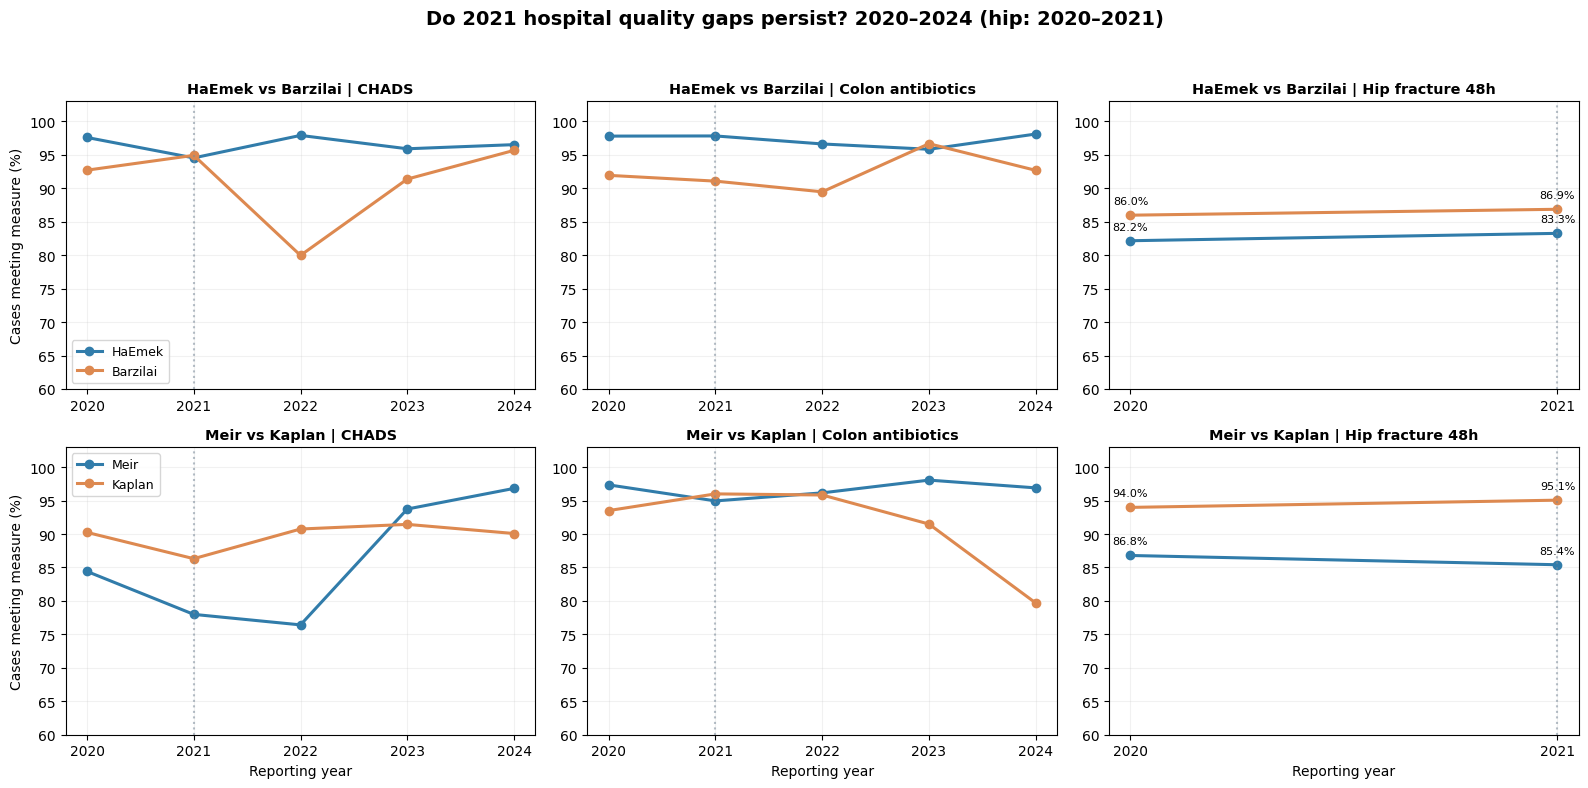

,hospital,metric_short,measurement_year,cases,rate_if_blank_zero_pct
20,Barzilai,CHADS,2020,782.0,92.71
44,Barzilai,CHADS,2021,749.0,94.93
68,Barzilai,CHADS,2022,714.0,79.97
91,Barzilai,CHADS,2023,696.0,91.38
115,Barzilai,CHADS,2024,1247.0,95.67
6,HaEmek,CHADS,2020,333.0,97.60
30,HaEmek,CHADS,2021,385.0,94.55
54,HaEmek,CHADS,2022,430.0,97.91
78,HaEmek,CHADS,2023,391.0,95.91
101,HaEmek,CHADS,2024,403.0,96.53


In [46]:
# 7.3 — Time-series contrast: only years observed in each quality source.
pair_time = clinical_hy.loc[clinical_hy.hospital_id.isin(PAIR_IDS)].copy()
pair_time['hospital']=pair_time.hospital_id.map(PAIR_LABELS)
fig,axs=plt.subplots(2,3,figsize=(16,8.0),sharey=False)
for i,z in enumerate(PAIR_SPECS):
    for j,m in enumerate(metric_order):
        ax=axs[i,j]
        for hospital,label,color in [(z['a'],z['a_en'],colors[0]),(z['b'],z['b_en'],colors[1])]:
            dat=pair_time.loc[pair_time.hospital_id.eq(hospital) & pair_time.metric_short.eq(m)].sort_values('measurement_year')
            if len(dat):
                ax.plot(dat.measurement_year,dat.rate_if_blank_zero_pct,marker='o',lw=2.2,color=color,label=label)
                if m=='Hip fracture 48h':
                    for x0,y0 in zip(dat.measurement_year,dat.rate_if_blank_zero_pct):
                        ax.annotate(f'{y0:.1f}%',(x0,y0),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
        ax.axvline(2021,ls=':',color='#798999',alpha=.55)
        ax.set_title(f'{z["pair_name"]} | {m}',fontsize=10.4,weight='bold')
        ax.set_ylabel('Cases meeting measure (%)' if j==0 else '')
        ax.set_xlabel('Reporting year' if i==1 else '')
        ax.set_ylim(60,103)
        ax.grid(alpha=.17)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
        if j==0: ax.legend(fontsize=9)
fig.suptitle('Do 2021 hospital quality gaps persist? 2020–2024 (hip: 2020–2021)',fontsize=14,weight='bold')
fig.tight_layout(rect=(0,0,1,.95))
fig.savefig('charts/quality_two_pairs_yearly_trends.png',dpi=190,bbox_inches='tight')
plt.show()
display(pair_time[['hospital','metric_short','measurement_year','cases','rate_if_blank_zero_pct']]
        .sort_values(['metric_short','hospital','measurement_year']).round(2))
pair_time.to_csv('exports/MOH_Two_Pairs_All_Years_PROVISIONAL.csv',index=False,encoding='utf-8-sig')

### 7.4 — בדיקת דמיון המטופלים: גיל, מין, סוג ניתוח ומשמרת

בתי חולים בעלי אותו סיווג גודל ומרכזיות עדיין עשויים לטפל באוכלוסיות שונות. נבדוק הבדלי *תמהיל* לפי מספר המקרים בשורה (`number_of_cases`) ולא לפי מספר השורות. אחר כך נבצע **תקנון ישיר חד־ממדי**: נחשב בכל בית חולים את שיעור העמידה בכל שכבת גיל (או מגדר/שיטה), ונשקלל אותו בהתפלגות משותפת של אותו זוג בתי חולים. זהו כלי EDA לבדיקת רגישות — **לא** התאמה מלאה לסיכון, חומרת מחלה, תחלואה נלווית או כל המשתנים בו־זמנית. כאשר לשכבה אין מקרים באחד מבתי החולים, נדווח על היעדר חפיפה ולא נניח שיעור 0.

Single-variable, pooled-case-mix direct standardisation. NOT multivariable risk adjustment:


adjusted_rate_pct                       \
hospital                                                                Barzilai HaEmek Kaplan   Meir   
pair               metric            stratification                                                     
HaEmek vs Barzilai CHADS             age_range                             94.94  94.55    NaN    NaN   
                                     day_range                             94.81  94.52    NaN    NaN   
                                     gender                                94.91  94.58    NaN    NaN   
                   Colon antibiotics detailed_age_range_groups             89.95  98.25    NaN    NaN   
                                     gender                                90.47  97.84    NaN    NaN   
                                     method                                91.52  97.78    NaN    NaN   
                   Hip fracture 48h  age_range                             87.08  83.25    NaN    NaN   
                                     gender                                86.85  83.29    NaN    NaN   
                                     method                                87.08  81.12    NaN    NaN   
                                     shift                                 87.22  83.25    NaN    NaN   
Meir vs Kaplan     CHADS             age_range                               NaN    NaN  86.17  78.68   
                                     day_range                               NaN    NaN  86.35  78.00   
                                     gender                                  NaN    NaN  86.37  77.76   
                   Colon antibiotics detailed_age_range_groups               NaN    NaN  96.20  94.97   
                                     gender                                  NaN    NaN  96.02  94.80   
                                     method                                  NaN    NaN  96.15  95.09   
                   Hip fracture 48h  age_range                               NaN    NaN  95.06  85.45   
                                     gender                                  NaN    NaN  95.05  85.40   
                                     method                                  NaN    NaN  95.40  85.08   
                                     shift                                   NaN    NaN  94.80  85.19   

                                                               share_cases_with_common_strata                     
hospital                                                                             Barzilai HaEmek Kaplan Meir  
pair               metric            stratification                                                               
HaEmek vs Barzilai CHADS             age_range                                           1.00    1.0    NaN  NaN  
                                     day_range                                           1.00    1.0    NaN  NaN  
                                     gender                                              1.00    1.0    NaN  NaN  
                   Colon antibiotics detailed_age_range_groups                           0.96    1.0    NaN  NaN  
                                     gender                                              1.00    1.0    NaN  NaN  
                                     method                                              1.00    1.0    NaN  NaN  
                   Hip fracture 48h  age_range                                           1.00    1.0    NaN  NaN  
                                     gender                                              1.00    1.0    NaN  NaN  
                                     method                                              1.00    1.0    NaN  NaN  
                                     shift                                               1.00    1.0    NaN  NaN  
Meir vs Kaplan     CHADS             age_range                                            NaN    NaN    1.0  1.0  
                                     

pair                hospital
HaEmek vs Barzilai  Barzilai    46.6
                    HaEmek      40.5
Meir vs Kaplan      Kaplan      44.4
                    Meir        53.9
Name: CHADS — age_range selected categories (%), dtype: float64

pair                hospital
HaEmek vs Barzilai  Barzilai    38.1
                    HaEmek      32.7
Meir vs Kaplan      Kaplan      36.6
                    Meir        40.3
Name: Hip fracture 48h — age_range selected categories (%), dtype: float64

pair                hospital
HaEmek vs Barzilai  Barzilai    44.5
                    HaEmek      53.0
Meir vs Kaplan      Kaplan      28.0
                    Meir        57.9
Name: Hip fracture 48h — shift selected categories (%), dtype: float64

pair                hospital
HaEmek vs Barzilai  Barzilai    48.2
                    HaEmek      19.6
Meir vs Kaplan      Kaplan      49.3
                    Meir        44.4
Name: Colon antibiotics — detailed_age_range_groups selected categories (%), dtype: float64

Age-standardised 2021 rates (pooled 2-hospital case mix; common strata only):


hospital                              Barzilai  HaEmek  Kaplan   Meir
pair               metric                                            
HaEmek vs Barzilai CHADS                 94.94   94.55     NaN    NaN
                   Colon antibiotics     89.95   98.25     NaN    NaN
                   Hip fracture 48h      87.08   83.25     NaN    NaN
Meir vs Kaplan     CHADS                   NaN     NaN   86.17  78.68
                   Colon antibiotics       NaN     NaN   96.20  94.97
                   Hip fracture 48h        NaN     NaN   95.06  85.45

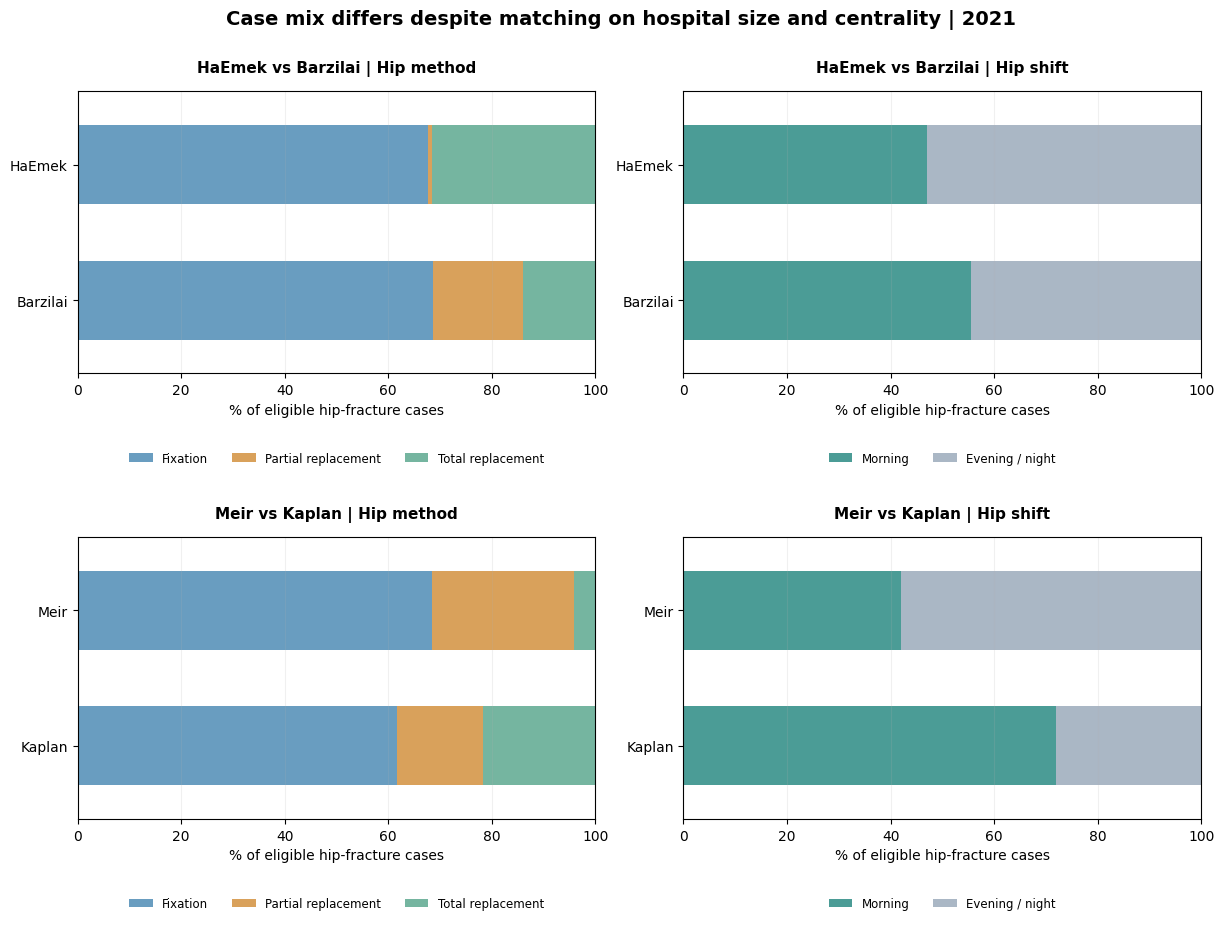

In [47]:
# 7.4 — One-dimensional direct case-mix standardisation (pair-pooled weights).
pair_raw_2021 = clinical.loc[clinical.measurement_year.eq(2021) & clinical.hospital_id.isin(PAIR_IDS)].copy()
pair_raw_2021['success_if_blank_zero'] = pair_raw_2021.number_of_cases_approved.fillna(0)

key_strata = {'CHADS': ['gender','age_range','day_range'],
    'Colon antibiotics':['gender','detailed_age_range_groups','method'],
    'Hip fracture 48h':['gender','age_range','method','shift']}

standardised=[]
case_mix=[]
for z in PAIR_SPECS:
    pair_data=pair_raw_2021.loc[pair_raw_2021.hospital_id.isin([z['a'],z['b']])]
    for m in metric_order:
        q=pair_data.loc[pair_data.metric_short.eq(m)]
        for variable in key_strata[m]:
            counts=(q.groupby(['hospital_id',variable],dropna=False)
                    .agg(cases=('number_of_cases','sum'),approved=('success_if_blank_zero','sum')).reset_index())
            wide_cases=(counts.pivot(index=variable,columns='hospital_id',values='cases')
                         .reindex(columns=[z['a'],z['b']]).fillna(0))
            common=wide_cases.index[(wide_cases[z['a']]>0)&(wide_cases[z['b']]>0)]
            w=wide_cases.loc[common].sum(axis=1)
            if len(common)<1 or w.sum()==0: continue
            weights=w/w.sum()
            wide_success=(counts.pivot(index=variable,columns='hospital_id',values='approved')
                          .reindex(index=common,columns=[z['a'],z['b']]))
            rates=100*wide_success/wide_cases.loc[common]
            adj=rates.mul(weights,axis=0).sum(axis=0)
            cover=wide_cases.loc[common].sum()/wide_cases.sum()
            for hospital in [z['a'],z['b']]:
                standardised.append({'pair':z['pair_name'],'metric':m,'stratification':variable,
                    'hospital':PAIR_LABELS[hospital], 'adjusted_rate_pct':adj[hospital],
                    'share_cases_with_common_strata':cover[hospital],
                    'n_common_strata':len(common)})
            for value,group in counts.groupby(variable,dropna=False):
                for rr in group.itertuples():
                    case_mix.append({'pair':z['pair_name'],'metric':m,'stratification':variable,
                       'stratum_value':str(value),'hospital':PAIR_LABELS[rr.hospital_id],
                       'cases':rr.cases,'share_pct':100*rr.cases/
                       q.loc[q.hospital_id.eq(rr.hospital_id),'number_of_cases'].sum()})
standardised_df=pd.DataFrame(standardised)
case_mix_df=pd.DataFrame(case_mix)
print('Single-variable, pooled-case-mix direct standardisation. NOT multivariable risk adjustment:')
std_wide=(standardised_df.pivot_table(index=['pair','metric','stratification'],columns='hospital',
                                     values=['adjusted_rate_pct','share_cases_with_common_strata']) )
display(std_wide.round(2))

# Summary: age, sex, operation method, shift — % of cases in a selected informative group.
chosen_strata={('CHADS','age_range'):[' 80 - 84',' 85 - 89',' 90 +'],
               ('Hip fracture 48h','age_range'):[' 85 +'],
               ('Hip fracture 48h','shift'):['ערב ולילה'],
               ('Colon antibiotics','detailed_age_range_groups'):[' 71 - 80',' 80 +']}
for (m,var),levels in chosen_strata.items():
    candidate=case_mix_df.loc[(case_mix_df.metric==m)&(case_mix_df.stratification==var)]
    # source data sometimes has leading spaces; comparison normalises strings.
    selected=candidate.loc[candidate.stratum_value.str.strip().isin([s.strip() for s in levels])]
    display(selected.groupby(['pair','hospital']).share_pct.sum().rename(m+' — '+var+' selected categories (%)').round(1))

# Summarize 2021 age-standardised differences as a simple sensitivity check.
select_age=standardised_df.loc[
    ((standardised_df.metric=='Colon antibiotics') & (standardised_df.stratification=='detailed_age_range_groups')) |
    ((standardised_df.metric!='Colon antibiotics') & (standardised_df.stratification=='age_range'))]
print('Age-standardised 2021 rates (pooled 2-hospital case mix; common strata only):')
display(select_age.pivot(index=['pair','metric'],columns='hospital',values='adjusted_rate_pct').round(2))
standardised_df.to_csv('exports/MOH_Two_Pairs_2021_One_Variable_Standardisation_PROVISIONAL.csv',index=False,encoding='utf-8-sig')
case_mix_df.to_csv('exports/MOH_Two_Pairs_2021_Case_Mix.csv',index=False,encoding='utf-8-sig')

# Visualise selected case-mix differences in hip fracture: surgical method and shift.
# Use short English category labels for legibility in a multilingual chart.
category_maps = {
    'method': {'קיבוע':'Fixation','החלפה חלקית':'Partial replacement',
               'החלפה מלאה':'Total replacement'},
    'shift': {'בוקר':'Morning','ערב ולילה':'Evening / night'}
}
cat_orders = {
    'method':['Fixation','Partial replacement','Total replacement'],
    'shift':['Morning','Evening / night']
}
cat_colors = {
    'Fixation':'#699DC0', 'Partial replacement':'#D9A15B',
    'Total replacement':'#75B5A0', 'Morning':'#4B9C96',
    'Evening / night':'#AAB7C5'
}
fig,axs=plt.subplots(2,2,figsize=(14.5,9.7))
fig.subplots_adjust(top=.88,bottom=.13,hspace=.58,wspace=.17)
for i,z in enumerate(PAIR_SPECS):
    for j,variable in enumerate(['method','shift']):
        ax=axs[i,j]
        sub=case_mix_df.loc[(case_mix_df.pair==z['pair_name']) &
             (case_mix_df.metric=='Hip fracture 48h') &
             (case_mix_df.stratification==variable)].copy()
        sub['category_en']=sub.stratum_value.str.strip().map(category_maps[variable]).fillna('Unknown')
        wide=sub.pivot_table(index='hospital',columns='category_en',values='share_pct',aggfunc='sum').fillna(0)
        columns=cat_orders[variable]
        if 'Unknown' in wide:columns=columns+['Unknown']
        wide=wide.reindex(index=[z['a_en'],z['b_en']],columns=columns,fill_value=0)
        wide.plot(kind='barh',stacked=True,ax=ax,
                  color=[cat_colors.get(s,'#D8D8D8') for s in columns],
                  width=.58,legend=False)
        ax.set_title(z['pair_name']+' | Hip '+variable,fontsize=11,weight='bold',pad=14)
        ax.set_xlabel('% of eligible hip-fracture cases')
        ax.set_ylabel('')
        ax.set_xlim(0,100)
        ax.grid(axis='x',alpha=.18)
        ax.invert_yaxis()
        ax.tick_params(axis='y',labelrotation=0)
        ax.legend(loc='upper center',bbox_to_anchor=(.5,-.24),
                  ncol=len(columns),fontsize=8.5,frameon=False)
fig.suptitle('Case mix differs despite matching on hospital size and centrality | 2021',
             fontsize=14,weight='bold',y=.965)
fig.savefig('charts/quality_two_pairs_hip_casemix.png',dpi=190,bbox_inches='tight')
plt.show()

### 7.5 — בדיקת רגישות לחוסרים ומגבלות בהסקה

הפערים בשיעורי העמידה תלויים בפרשנות של מונה חסר (`number_of_cases_approved`). נבדוק מה משתנה אם **משמיטים** שורות עם מונה חסר (חלופה שאינה בהכרח נכונה), בהשוואה להנחה שמונה חסר משמעו 0 הצלחות. ההבדל בין התוצאות הוא מבחן ליציבות החישוב, **לא** הכרעה איזה טיפול ב־NULL נכון. לא נדע אם חלק מהתצפיות חסרות משום שהמדידה לא בוצעה ללא פירוט במקור.

In [48]:
# 7.5 — Missing-numerator sensitivity in the four selected hospitals, 2021.
sub=pair_raw_2021.copy()
rows=[]
for (hid,m),g in sub.groupby(['hospital_id','metric_short']):
    n_all=g.number_of_cases.sum()
    n_known=g.loc[g.number_of_cases_approved.notna(),'number_of_cases'].sum()
    n_succ=g.number_of_cases_approved.sum()
    rows.append({'hospital':PAIR_LABELS[hid], 'metric':m,
      'cases_all':n_all, 'cases_in_blank_rows':n_all-n_known,
      'blank_0_rate_pct':100*n_succ/n_all,
      'drop_blank_rows_rate_pct':100*n_succ/n_known if n_known else np.nan,
      'bias_if_dropped_pp':100*n_succ/n_known-100*n_succ/n_all if n_known else np.nan})
missing_sensitivity=pd.DataFrame(rows)
print('2021 missing numerator sensitivity by hospital:')
display(missing_sensitivity.sort_values(['metric','hospital']).round(2))
missing_sensitivity.to_csv('exports/MOH_Two_Pairs_2021_Null_Sensitivity.csv',index=False,encoding='utf-8-sig')

# Check unique row keys at provided stratification granularity (no duplicated cells).
source_dimensions=['metric_short','measurement_year','month','provider','gender','shift','day_range',
                  'age_range','method','detailed_age_range_groups']
print('Repeated partial-strata keys (can differ by actual_time; NOT exact duplicate source rows):',
      int(clinical.loc[clinical.hospital_id.isin(PAIR_IDS)].duplicated(source_dimensions).sum()))
print('2021 exact duplicate source rows (4 hospitals):',int(sub.duplicated().sum()))

2021 missing numerator sensitivity by hospital:


,hospital,metric,cases_all,cases_in_blank_rows,blank_0_rate_pct,drop_blank_rows_rate_pct,bias_if_dropped_pp
9,Barzilai,CHADS,749.0,4.0,94.93,95.44,0.51
0,HaEmek,CHADS,385.0,6.0,94.55,96.04,1.50
6,Kaplan,CHADS,475.0,9.0,86.32,87.98,1.67
3,Meir,CHADS,527.0,18.0,77.99,80.75,2.76
10,Barzilai,Colon antibiotics,56.0,5.0,91.07,100.00,8.93
1,HaEmek,Colon antibiotics,92.0,2.0,97.83,100.00,2.17
7,Kaplan,Colon antibiotics,75.0,3.0,96.00,100.00,4.00
4,Meir,Colon antibiotics,99.0,5.0,94.95,100.00,5.05
11,Barzilai,Hip fracture 48h,236.0,31.0,86.86,100.00,13.14
2,HaEmek,Hip fracture 48h,251.0,42.0,83.27,100.00,16.73


Repeated partial-strata keys (can differ by actual_time; NOT exact duplicate source rows): 812
2021 exact duplicate source rows (4 hospitals): 0


### 7.6 — מסקנות מהבדיקה המעמיקה (ראשוניות)

**העמק מול ברזילי:** פער 47 נקודות אחוז בשיעור המתמחים בוגרי מוסדות לא מאושרים, אך **שיעור CHADS כמעט זהה** ב־2021. במדד האנטיביוטיקה **העמק גבוה יותר**, ואילו בניתוח שבר בתוך 48 שעות **ברזילי גבוה יותר**. גם אחרי תקנון חד־ממדי פשוט לפי גיל/מין/סוג ניתוח, אין תבנית אחידה. למרות התאמה של מרכזיות וקטגוריית גודל, יש **הבדל בבעלות**, ולכן זה אינו ניסוי מבוקר.

**מאיר מול קפלן:** פער 22 נקודות אחוז בהרכב המתמחים באותה בעלות, מרכזיות וקטגוריית גודל. ב־2021 **קפלן גבוה יותר ב־CHADS ובניתוח שבר**, ובאנטיביוטיקה הפער קטן. הפערים ב־CHADS משתנים מאוד לאורך השנים — מאיר משתפר משמעותית ב־2023–2024 — כך שהתמונה אינה עדות להשפעה יציבה של מסלולי ההכשרה. יש גם **הבדל בתמהיל המשמרות ובסוגי הניתוח**.

**משמעות מחקרית:** שני הזוגות **אינם תומכים בהשערה פשוטה** שלפיה שיעור גבוה יותר של מתמחים ממוסדות לא מאושרים מלווה בהכרח בעמידה נמוכה יותר בכל מדדי האיכות. עם זאת, אין בכך הוכחה ששיעור זה אינו משפיע על איכות הטיפול: הנתונים אקולוגיים, חלק מהמדדים מושפעים מתהליכים בית־חולימיים ולא רק מהרופא, ואין פירוק של מקרים לפי מסלול הכשרת המטפל. לא ניתן לייחס הבדלים לבית חולים בודד, לרופא מסוים או למסלול הכשרה.

**עדכון בדיקת המונה החסר:** סעיף 5.2.1 מציג הצלבת זמן ושחזור נתונים רשמיים התומכים בריק כאפס. אין להציג זאת כאישור מפורש מהספק, ובדיקת בלעדיות הפילוחים עדיין פתוחה. את פערי הגודל המדויקים אפשר לאמת מול מיטות/תיקי מטופלים אם יתווספו נתונים, ולא רק קבוצת גודל.

## 8. סיכום הממצאים — בין כמות, הרכב המתמחים ואיכות הטיפול

### 8.1 כמות ומקורות הכשרה

- **תלות בהכשרה בחו״ל:** בשנת 2021 שיעור הרופאים שהוכשרו בחו״ל בישראל היה **57.8%**, לעומת חציון של כ־**13.5%** במדינות OECD המדווחות על המדד (מדגם מדינות עם נתונים בלבד).
- **מגמת זמינות:** בשנים 2010–2024 מלאי הרופאים לפי מקום ההכשרה בישראל גדל בכ־**42.9%** לעומת גידול אוכלוסייה של כ־**31.2%**; במונחי מלאי לנפש — כ־**8.9%**. רופאים פעילים הם סדרה אחרת, ויש להבחין בין שתי ההגדרות.
- **שונות בין בתי חולים:** שיעור המתמחים בוגרי מוסדות לא מאושרים ב־2021 נע בין **6%** בשניידר ל־**67%** בברזילי (חציון של **30%** במדגם 25 בתי החולים). קטגוריה זו **אינה** שקולה לכלל הרופאים שלמדו בחו״ל.

### 8.2 איכות — מה מצאנו בפועל?

| מדד איכות והשוואה ברמת בית חולים | שנת הכשרה ← שנת איכות | בתי חולים | Pearson r | מסקנה ראשונית |
|:--|:--:|--:|--:|:--|
| כלל המתמחים ↔ CHADS | 2021 ← 2021 | 21 | −0.128 | שלילי חלש מאוד, לא מובהק |
| כלל המתמחים ↔ אנטיביוטיקה | 2021 ← 2021 | 24 | −0.174 | שלילי חלש, לא מובהק |
| כלל המתמחים ↔ שבר תוך 48 שעות | 2021 ← 2021 | 23 | +0.295 | חיובי חלש, לא מובהק |
| קרדיולוגיה ↔ CHADS | 2020 ← 2020 | 9 | **−0.750** | שלילי יחסית חזק; מובהק *ללא* תיקון, לא לאחר תיקון ל־3 בדיקות |
| כירורגיה כללית ↔ אנטיביוטיקה | 2020 ← 2020 | 10 | −0.191 | לא מובהק |
| אורתופדיה ↔ שבר תוך 48 שעות | 2020 ← 2020 | 10 | +0.445 | לא מובהק |

**הבחנה חשובה:** המתאם של קרדיולוגיה–CHADS ב־2020 מצדיק בירור נוסף, ואין לתאר את התוצאות כ־"לא מצאנו כלל קשר". ערך p נומינלי ≈0.020; לאחר Bonferroni לשלוש בדיקות p≈0.059. בוצעה גם בדיקת Leave-One-Hospital-Out בסעיף 6.5. כל אלה מתאמים חקרניים, **לא אומדן השפעה**.

**בדיקות עומק:** בהעמק–ברזילי הפער בהרכב המתמחים הוא **47 נקודות אחוז** ולמרות זאת המדדים אינם מצביעים על יתרון עקבי לאחד הצדדים. במאיר–קפלן, קפלן הציג ב־2021 שיעורי עמידה גבוהים יותר בשלושת המדדים למרות שיעור גבוה יותר של מתמחים ממוסדות לא מאושרים; אולם בהשוואה לאורך שנים מגמת CHADS השתנתה. ההשוואות אינן מבוקרות דיין להסקת סיבתיות.

### 8.3 מה מסקנת האיכות — ומה אינה?

**מסקנה נתמכת:** בנתונים המוגבלים לא נמצא **קשר שלילי עקבי ומובהק** בין שיעור המתמחים שהוכשרו במוסדות לא מאושרים לבין עמידה במדדי איכות מערכתיים בשלוש הדוגמאות שנבדקו. בבדיקה ממוקדת בקרדיולוגיה נמצא אות שלילי חזק יותר — אך לא מובהק לאחר תיקון לריבוי בדיקות.

**לא ניתן להסיק:** שמסלול הכשרה אינו משפיע על איכות רופא; שמסלול הכשרה כן משפיע עליה; ששיעור המתמחים משקף את כלל הרופאים והמטפלים בפועל; או שהפער במדדי התהליך שווה לפער בכישורי טיפול קליניים. **אי־מובהקות אינה הוכחה להעדר אפקט.**

**למה המדדים מוגבלים לבחינת איכות רופא?**

1. **מדד תהליכי ברמת בית חולים ≠ איכות רופא בודד:** נהלים, זמינות חדרי ניתוח, עומס, סיעוד, מומחים בכירים, ציוד ומדיניות הנהלה משפיעים על התוצאה.
2. **אין חיבור חשיפה–תוצאה:** שיעור מתמחים בכלל בית החולים יכול להיות שונה מאוד משיעורם במחלקה הרלוונטית; וגם שיעור במחלקה אינו מלמד מי טיפל בפועל או מי קיבל החלטה רפואית.
3. **בחירת המדדים:** שלושה מדדים הנמצאים במעקב ארצי עשויים לקבל תשומת לב ניהולית מיוחדת (השערה שלא נבדקה כאן); הם אינם מכסים תמותה, סיבוכים, חוויית מטופל ועוד.
4. **ערבוב גורמים וקבוצות קטנות:** חומרת מקרים, גיל, מחלות רקע, התמחות בית החולים, גודל ובעלות; בפרט, חישובי ההתמחויות מבוססים על 9–10 בתי חולים בלבד.
5. **בדיקות איכות הנתונים:** חישוב מונה ריק כאפס נתמך בהצלבה לפי זמן ובשחזור פרסומים רשמיים (סעיף 5.2.1); אישור ספק מפורש ובלעדיות פילוחי המקור עדיין לא הושלמו.

### 8.4 מסקנת מדיניות זהירה

אפשר להצדיק **הרחבת יכולת ההכשרה המקומית** מהיבטי חוסן מערכת הבריאות, גישה להכשרה והקטנת התלות בהכשרה בחו״ל, **גם בלי לטעון שהוכח פער באיכות הבוגרים**. כדי לטעון על איכות אישית נחוצים נתונים ברמת הרופא והמטופל, לא רק מדדי תהליך בית־חולימיים. השוואה לחציון OECD מצביעה על פער יחסי, **לא** על מספר הרופאים האופטימלי לישראל.


## 9. שקף נדרש למצגת: איזה מידע היה מאפשר לענות טוב יותר על שאלת המחקר?

**שקף מוצע — ארבע קבוצות נתונים, פריטים קונקרטיים (מתאים לשקף 16:9 בשתי עמודות)**

| קבוצת המידע | אילו נתונים צריך, בדיוק? |
|:--|:--|
| **הרופאים ומסלול ההכשרה** | מזהה רופא אנונימי; מוסד ומדינת לימודים; הכרה במוסד במועד הלימודים; ציוני בחינת רישוי; התמחות, דרגה (מתמחה/מומחה), ותק, הכשרה קלינית וניסיון; **מספר הרופאים בפועל** לפי מחלקה ושנה, ולא רק אחוזי מתמחים. |
| **מי טיפל במי ובמה?** | מזהה מטופל/אירוע אנונימי; בית חולים, מחלקה, תאריך, הליך; קישור למזהי הרופאים שטיפלו בפועל; **מי קיבל החלטה, מי ביצע פעולה ומי פיקח**; משך ומידת המעורבות בטיפול. |
| **תוצאות איכות מגוונות** | תמותה וסיבוכים **מתוקננים לסיכון**, זיהומים, אשפוזים חוזרים, שגיאות טיפול ותוצאות ארוכות טווח; איכות האבחון והחלטות טיפול; שביעות רצון/תלונות כמדדים **משלימים** (לא כמדד בלעדי). |
| **בקרות והשוואה לאורך זמן** | גיל, מגדר, מחלות רקע וחומרת המקרה; עומס, תקני כוח אדם, משמרות, ציוד, נהלים, זמני המתנה; כמה שנות נתונים; אותה הגדרה ומכנה לכל מדד; נפח מקרים מספק בכל קבוצה. |

**השורה התחתונה לשקף:** הנתון החשוב ביותר שחסר הוא קישור אנונימי בין **מסלול הכשרת הרופא → מעורבותו בטיפול → תוצאת המטופל**, והשוואת מקרים דומים תוך בקרה על גורמי רקע רפואיים ומערכתיים.

**הסתייגות אתית/משפטית:** מדובר בנתונים רגישים שידרשו אנונימיזציה, הרשאות מחקר ואבטחת מידע. גם נתונים כאלה אינם מבטיחים זיהוי סיבתי ללא תכנון מחקר מתאים.


## 10. מה נשאר לפני הגשה והכנת מצגת Gamma?

| עדיפות | משימה | מצב |
|:--|:--|:--|
| **בוצע** | הצלבת מונה ריק עם זמן השבר ושחזור נתונים רשמיים; גרף וטבלת ספירות בסעיף 5.2.1 | **תמיכה אמפירית חזקה בריק כאפס**; אישור ספק מפורש לא נמצא |
| **חובה** | אימות האם פילוחי המקור בלעדיים או חופפים | **פתוח** — נפרד מבדיקת המונה הריק |
| **חובה** | ביקורת שיוך בתי חולים והתמחויות בקובץ 2020 מול תרשים המקור, במיוחד בחינת ערכי 0 לעומת חסר, ומיפוי מחלקה↔מדד | **בדיקת השלמה** |
| **בוצע** | מתאמי 2021 להרכב הכללי, מתאמי 2020 לפי התמחות ומדד, התאמת שנים, בדיקת Leave-One-Hospital-Out בקרדיולוגיה | **בוצע במחברת** |
| **בוצע** | חישוב OECD לשנת 2021 לפי *רופאים פעילים*, עם חציון/ממוצע ותרגום להפרש מספרי (לא "תקנים חסרים") | **בוצע בסעיף 3.11** |
| **לפני הגשה** | ריצה נקייה מתחילת המחברת, בדיקת מקורות לכותרות הגרפים, בחירת מספרים סופיים וייצוא גרפים ל־Gamma | **בדיקת סגירה** |
| **מצגת** | תכנון 18–20 שקפים / 15 דקות, פרומפט Gamma, שקף מידע חסר, מגבלות, המלצות וחלוקת זמן דיבור | **שלב הבא** |

**משפט סיכום נכון למצגת:** *"מצאנו תלות גבוהה בהכשרת רופאים בחו״ל ושונות ניכרת בהרכב המתמחים, אך לא זיהינו קשר שלילי עקבי במדדי איכות מערכתיים; כדי לבדוק איכות של רופאים יש צורך במידע פרטני יותר ובתקנון קליני."*
